# Visualising an Overtake in the RACECAR Dataset
### From a whole-track LiDAR map to the view of the passing car's camera

## Purpose and approach

The RACECAR dataset contains recordings of autonomous race cars driving at high speed, stored in the nuScenes format. Each recording holds LiDAR scans, radar data and camera images, together with the position and orientation of the car at every moment. This notebook documents an exploratory analysis of that dataset and, building on it, the construction of one short video of a real overtake between two of the cars. The question behind the video is practical: how can data from several sensors, recorded by two different cars, be brought into one coherent picture of a manoeuvre that lasts only a few seconds?

The full recordings of the multi-car runs are tens of gigabytes each. The work therefore follows a deliberate order. First, only the small metadata tables are read, in order to understand what was recorded, by whom, and when. Second, one overtake is located by comparing the paths of two cars. Third, only the files belonging to that overtake are downloaded from the archive. Finally, the sensor data are aligned in time and space and rendered as a video.

## The result

The final video lasts about 28 seconds and consists of five pieces that are joined without visible cuts:

1. A map of the whole track, built from the LiDAR sweeps of the car MIT-PITT-RW during the lap before the overtake. The second car, KAIST, appears as a moving marker with a trail.
2. A three-second transition in which the camera zooms, rotates and pans from the map to a top-down view that is fixed to the car.
3. The top-down LiDAR view ("cockpit view") of MIT-PITT-RW, in which KAIST becomes visible as a cluster of points.
4. A two-second "virtual camera" transition that tilts the top-down view into the perspective of a real camera and fades into the photograph.
5. The real footage of the front-right camera until about three seconds after KAIST has left the image.

## Three data problems that shape the analysis

Three properties of the data had to be diagnosed and corrected before any result could be trusted. The first is that the timestamps are not on a single scale: a large share of them is inflated by a factor of ten (Section 2). The second is that the stored orientation of the car is rotated by 90 degrees relative to its direction of travel (Section 5). The third is that the clocks of the two cars do not agree exactly, and that the offset which fits the camera differs from the one which fits the LiDAR (Sections 5.5 and 7.5a). All three problems are demonstrated with figures and corrected explicitly, rather than silently.

## Outline

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | The dataset and its metadata: scenes, logs, sensors, and which recordings can be combined |
| 2 | Data quality: the timestamp scale |
| 3 | The two cars: trajectories, detection of overtakes, and the choice of one pass |
| 4 | Downloading only the files needed for that pass |
| 5 | From raw LiDAR points to the camera image: coordinate frames, orientation fix, projection, clock offset |
| 6 | Building the video, piece by piece, and joining the pieces |
| 7 | Extension: finding the passing car without being told where it is |
| 8 | Summary, limitations and files produced |

## How to read this notebook

The cells are written to be run from top to bottom. Each section starts with a short statement of what is done and why, and, where the output requires interpretation, ends with a reading of the result. Figures are saved in the folder `figures/` and videos in `videos/`; the figure numbers follow the file names (number 12 is not used). The raw data are not part of the notebook: they are downloaded from the public bucket `racecar-dataset` (region us-west-2) without credentials.

## 0. Setup

The first cell installs the Python packages listed in `requirements.txt` (among others `boto3` for the download, `pandas` and `numpy` for the tables, `matplotlib` for the figures, and `imageio-ffmpeg`, `opencv-python` and `scipy` for the video). The extension in Section 7 additionally needs `scikit-learn` and `torch`. After a first installation the kernel may need to be restarted.

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 1. The dataset and its metadata

The nuScenes format separates a small relational index from the bulky sensor files. The index consists of JSON tables (scenes, logs, sensors, calibrations, poses, and so on), whereas point clouds and images are stored as separate files. Reading the index first makes it possible to plan which of the large files are really needed.

### 1.1 Downloading the metadata archive

The data are stored in a public Amazon S3 bucket. Because no credentials are required, the client is configured to send unsigned requests. Only the file `metadata.tar` is downloaded here.

In [2]:
import boto3
from botocore import UNSIGNED
from botocore.config import Config
from pathlib import Path

DATA = Path("data"); DATA.mkdir(exist_ok=True)

# Public bucket, so no credentials: UNSIGNED tells boto3 not to sign the request
s3 = boto3.client("s3", region_name="us-west-2",
                  config=Config(signature_version=UNSIGNED))
s3.download_file("racecar-dataset", "RACECAR-nuScenes/metadata.tar",
                 str(DATA / "metadata.tar"))

### 1.2 Contents of the archive

Listing the names inside the archive shows the folder `v1.0-mini` and 13 JSON tables, which is the standard set of nuScenes tables.

In [3]:
import tarfile
with tarfile.open(DATA / "metadata.tar") as t:
    names = t.getnames()
print(len(names))
print(names[:30])

14
['v1.0-mini', 'v1.0-mini/attribute.json', 'v1.0-mini/calibrated_sensor.json', 'v1.0-mini/category.json', 'v1.0-mini/ego_pose.json', 'v1.0-mini/instance.json', 'v1.0-mini/log.json', 'v1.0-mini/map.json', 'v1.0-mini/sample.json', 'v1.0-mini/sample_annotation.json', 'v1.0-mini/sample_data.json', 'v1.0-mini/scene.json', 'v1.0-mini/sensor.json', 'v1.0-mini/visibility.json']


### 1.3 Extracting the tables

The archive is extracted with the `data` filter, which refuses unsafe paths inside a tar file. The printed sizes show where the weight lies: `sample_data.json` (928 MB) holds one row for every single sensor reading, `ego_pose.json` (135 MB) holds the pose of the car at every reading, and `sample.json` (10 MB) holds the keyframes. All other tables are negligible in size.

In [4]:
import tarfile, json
import pandas as pd

with tarfile.open(DATA / "metadata.tar") as t:
    t.extractall(DATA, filter="data")   # "data" filter blocks unsafe paths inside the tar

ROOT = DATA / "v1.0-mini"
for p in sorted(ROOT.glob("*.json")):
    print(f"{p.name:28s}{p.stat().st_size / 1e6:10.1f} MB")

attribute.json                     0.0 MB
calibrated_sensor.json             0.0 MB
category.json                      0.0 MB
ego_pose.json                    135.4 MB
instance.json                      0.0 MB
log.json                           0.0 MB
map.json                           0.0 MB
sample.json                       10.2 MB
sample_annotation.json             0.0 MB
sample_data.json                 928.1 MB
scene.json                         0.0 MB
sensor.json                        0.0 MB
visibility.json                    0.0 MB


### 1.4 Scenes, logs and sensors

A small helper `load()` reads a table into a data frame. Three tables give the first overview. A **scene** is one continuous recording segment, with a name and a description (for example "Solo laps between 100 and 140 mph"). A **log** states which vehicle recorded it, where, and on which date. A **sensor** is one data channel of a car (for example `LIDAR_FRONT` or `CAMERA_FRONT_RIGHT`).

The dataset contains 22 scenes, 22 logs and 11 sensors.

In [5]:
def load(name):
    with open(ROOT / f"{name}.json") as f:
        return pd.DataFrame(json.load(f))

scene  = load("scene")
log    = load("log")
sensor = load("sensor")

print(len(scene), "scenes |", len(log), "logs |", len(sensor), "sensors")
print(scene.columns.tolist())
print(log.columns.tolist())
scene.head(3)

22 scenes | 22 logs | 11 sensors
['description', 'first_sample_token', 'last_sample_token', 'log_token', 'name', 'nbr_samples', 'token']
['date_captured', 'location', 'logfile', 'token', 'vehicle']


,description,first_sample_token,last_sample_token,log_token,name,nbr_samples,token
0,Solo laps between 100 and 140 mph,5933c81af5e770dffbbcf61fd9b37acc,e994bdcb09f4f412b63048f29a40ef4c,b2c2478b05990625f7aeddacca256411,SOLO-FAST-100-140,1799,3f0071a679de9ad85854f63cfe069c2c
1,Solo laps between 70 and 100 mph,930695078898d9594d037a9e071553ce,4e12e3ff2546f96b217bacd82a8e988e,d95fec9ccb762b37f43dedbf8e56eacb,SOLO-SLOW-70-100,3899,7d40257ad02b974d440ceaae1b36e055
2,Solo laps below 70 mph,0bfce898ed300c968c9fb2a9d32f55a6,2559bf59c2810e444b8d71593a35ee20,b90d57de1e87976f041acb288999b0b6,SOLO-SLOW-70,2676,092e2c709a196afe68e1a8a8bc711171


### 1.5 First look at the timestamps

Before scenes can be compared in time, the timestamps need to be understood. The number of digits of every sample timestamp is counted. A Unix time in seconds has 10 digits at present.

In [6]:
sample = load("sample")
print(sample.columns.tolist())

digits = sample["timestamp"].astype("int64").astype(str).str.len()
print(digits.value_counts())

['next', 'prev', 'scene_token', 'timestamp', 'token']
timestamp
11    38108
Name: count, dtype: int64


All 38,108 sample timestamps have 11 digits. They are therefore not plain Unix times in seconds, but appear to be inflated by a factor of ten. Section 2 examines the other tables as well, and the next cell defines a correction.

### 1.6 Normalising timestamps and summarising each scene

The function `norm_ts` rescales each timestamp according to its own number of digits (`shift = digits - 10`, then division by `10**shift`). A correction per value, rather than one global factor, is needed because, as Section 2 shows, the tables contain a mixture of scales. The normalised times give the start, end and duration of every scene. The durations range from 349.5 s to 1,949 s.

In [7]:
def norm_ts(t):
    shift = len(str(int(t))) - 10
    return t / 10**shift

sample["t"] = sample["timestamp"].apply(norm_ts)

span = (sample.groupby("scene_token")["t"]
              .agg(n_samples="count", t_min="min", t_max="max"))

scenes = (scene.merge(log, left_on="log_token", right_on="token", suffixes=("", "_log"))
               [["name", "vehicle", "location", "date_captured", "nbr_samples", "token"]]
               .merge(span, left_on="token", right_index=True))
scenes["duration_s"] = scenes["t_max"] - scenes["t_min"]

pd.set_option("display.width", 200)
scenes.drop(columns="token")

,name,vehicle,location,date_captured,nbr_samples,n_samples,t_min,t_max,duration_s
0,SOLO-FAST-100-140,MIT-PITT-RW,LVMS,2022-01-07,1799,1799,1.641584e+09,1.641585e+09,899.0
1,SOLO-SLOW-70-100,MIT-PITT-RW,LVMS,2021-12-29,3899,3899,1.640814e+09,1.640816e+09,1949.0
2,SOLO-SLOW-70,MIT-PITT-RW,LVMS,2021-12-15,2676,2676,1.639611e+09,1.639613e+09,1337.5
3,MULTI-SLOW-KAIST,MIT-PITT-RW,LVMS,2022-01-02,1399,1399,1.641164e+09,1.641164e+09,699.0
4,SOLO-FAST-100-140,TUM,IMS,2021-10-23,919,919,1.635011e+09,1.635011e+09,459.0
5,PYLON,TUM,IMS,2021-10-23,818,818,1.635011e+09,1.635012e+09,408.5
6,MULTI-FAST-EURO,TUM,LVMS,2022-01-07,1469,1469,1.641596e+09,1.641596e+09,734.0
7,MULTI-FAST-POLI,TUM,LVMS,2022-01-07,1599,1599,1.641598e+09,1.641599e+09,799.0
8,MULTI-SLOW-EURO,TUM,LVMS,2022-01-04,2845,2845,1.641332e+09,1.641334e+09,1422.0
9,SOLO-FAST-140,TUM,LVMS,2022-01-07,1156,1156,1.641588e+09,1.641589e+09,577.5


### 1.7 Finding recordings that can be combined

An overtake can only be studied if two cars were driving on the same track at the same time and both recorded it. Scene names of the form `MULTI-SLOW-KAIST` indicate a multi-car run in which the recording car met the car named at the end. Two scenes form a pair if they share the speed class and the date, and if each car names the other. The overlap of a pair is the earlier of the two end times minus the later of the two start times, computed with the normalised times.

In [8]:
short = {"MIT-PITT-RW": "MIT", "KAIST": "KAIST", "TUM": "TUM",
         "EURORACING": "EURO", "CAVALIER": "CAV", "POLIMOVE": "POLI"}

multi = scenes[scenes["name"].str.startswith("MULTI")].copy()
multi["me"]    = multi["vehicle"].map(short)
multi["other"] = multi["name"].str.split("-").str[-1]   # the car named in the suffix
multi["speed"] = multi["name"].str.split("-").str[1]    # SLOW / FAST

m = multi[["name", "vehicle", "me", "other", "speed", "date_captured", "t_min", "t_max"]]

# A pair = my "other" is your "me" and vice versa, same speed class, same date
pairs = m.merge(m, left_on=["speed", "date_captured", "me", "other"],
                   right_on=["speed", "date_captured", "other", "me"],
                   suffixes=("_a", "_b"))
pairs = pairs[pairs["vehicle_a"] < pairs["vehicle_b"]].copy()   # drop mirrored duplicates

pairs["overlap_s"] = (pairs[["t_max_a", "t_max_b"]].min(axis=1)
                      - pairs[["t_min_a", "t_min_b"]].max(axis=1))
pairs[["name_a", "vehicle_a", "name_b", "vehicle_b", "date_captured", "overlap_s"]]

,name_a,vehicle_a,name_b,vehicle_b,date_captured,overlap_s
3,MULTI-SLOW-MIT,KAIST,MULTI-SLOW-KAIST,MIT-PITT-RW,2022-01-02,698.999811
4,MULTI-SLOW-POLI,CAVALIER,MULTI-SLOW-CAV,POLIMOVE,2022-01-04,598.999490
6,MULTI-FAST-TUM,EURORACING,MULTI-FAST-EURO,TUM,2022-01-07,-10151.008448
7,MULTI-SLOW-TUM,EURORACING,MULTI-SLOW-EURO,TUM,2022-01-04,-9500.994037


Four candidate pairs result. Two of them have a positive overlap: MIT-PITT-RW and KAIST on 2022-01-02 (about 699 s) and CAVALIER and POLIMOVE on 2022-01-04 (about 599 s). The two pairs of EURORACING and TUM show overlaps of about -9,500 and -10,150 s, which means that their logs do not cover the same time interval when the timestamps are taken at face value. These pairs cannot be compared directly and are not used. The pair MIT-PITT-RW and KAIST is used in the remainder of the notebook.

### 1.8 Sensors and calibrations

The sensor table lists 11 channels: three LiDARs and one fused LiDAR, one radar, and six camera channels. The table `calibrated_sensor` has 78 rows. Each row describes one sensor as mounted on one vehicle: its position and orientation relative to the car and, for cameras, the intrinsic matrix. These calibrations are needed later to move points between the sensor frames and the car frame.

In [9]:
print(sensor)
calib = load("calibrated_sensor")
print(len(calib), calib.columns.tolist())

                      channel modality                             token
0                 LIDAR_FRONT    lidar  86a41f36e1700f957f36cf52a0590528
1                  LIDAR_LEFT    lidar  08f4d1ddfb90dae796f4185c1a126e66
2                 LIDAR_RIGHT    lidar  a31a6dc3ff558558817257f193456500
3                 RADAR_FRONT    radar  2432b488c210410561b02018237366c9
4            CAMERA_REAR_LEFT   camera  c8517f3999746d7c2f69a2b75c1032df
5   CAMERA_FRONT_RIGHT_CENTER   camera  a20123abc202f7f165b1768d29d5ba45
6           CAMERA_REAR_RIGHT   camera  422b3ce674889c03b950a375f3b53687
7          CAMERA_FRONT_RIGHT   camera  8a2b611d5a6f6622072abafadaf11789
8    CAMERA_FRONT_LEFT_CENTER   camera  2eb675e743dd7e021c27c7880b434f26
9           CAMERA_FRONT_LEFT   camera  57b859ea8aff6720023c2af504a752ab
10                LIDAR_FUSED    lidar  73a24031bebeef40a81452dd0ded0bc7
78 ['camera_intrinsic', 'rotation', 'sensor_token', 'token', 'translation']


### 1.9 Figure 1: all recorded scenes

The first figure gives a visual overview: one bar per scene, with the length given as the number of samples, coloured by the contributing team. The colour palette is colour-blind friendly and is reused in all later figures. The function `style()` applies the common appearance of the axes. The scenes differ considerably in length, and the number of scenes per team is uneven.

This first version has a small defect: the axis labels are strings, and matplotlib treats identical strings as one category. Two scenes with the same name and location (for example `SOLO-FAST-100-140 (IMS)` from TUM and from EURORACING) are therefore drawn in the same row. The corrected version is produced two cells below and overwrites the saved file.

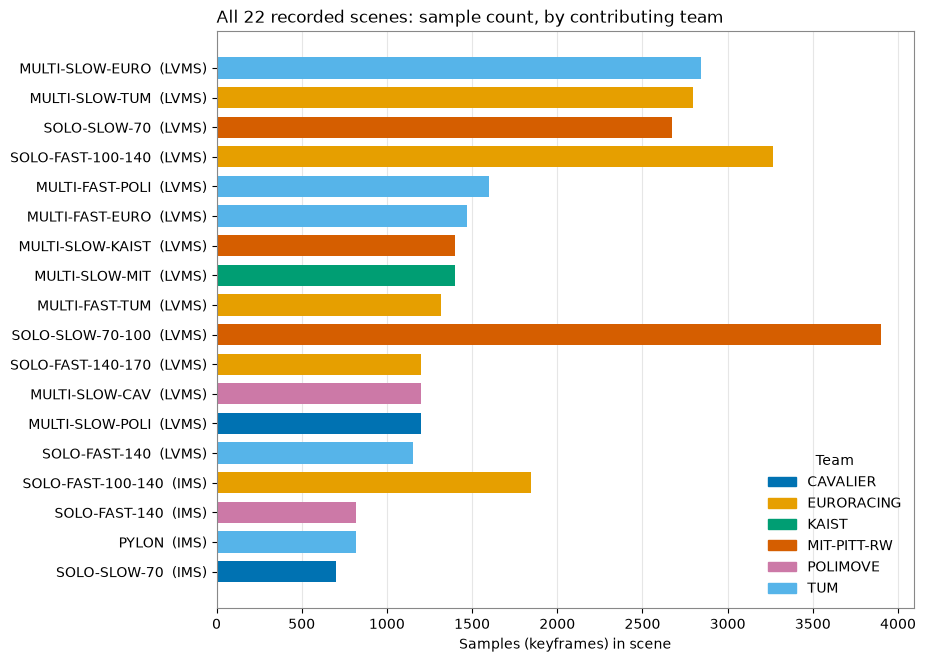

In [10]:
import matplotlib.pyplot as plt
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

TEAM_COLORS = {"CAVALIER": "#0072B2", "EURORACING": "#E69F00", "KAIST": "#009E73",
               "MIT-PITT-RW": "#D55E00", "POLIMOVE": "#CC79A7", "TUM": "#56B4E9"}

def style(ax):
    ax.grid(axis="x", color="#e6e6e6"); ax.set_axisbelow(True)
    for s in ax.spines.values(): s.set_color("#888")

d = scenes.sort_values("n_samples")
labels = [f"{n}  ({l})" for n, l in zip(d["name"], d["location"])]
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(labels, d["n_samples"], color=d["vehicle"].map(TEAM_COLORS), height=0.72)
ax.set_xlabel("Samples (keyframes) in scene")
ax.set_title("All 22 recorded scenes: sample count, by contributing team", loc="left")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TEAM_COLORS.values()]
ax.legend(handles, TEAM_COLORS.keys(), title="Team", loc="lower right", frameon=False)
style(ax)
fig.savefig("figures/01_scene_overview.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.10 Figure 2: multi-car logs on the wall clock

For each recording day, the multi-car logs are placed on a common time axis (hour of the day, in UTC, from the normalised timestamps). If two cars drove together, their bars should overlap. This figure visualises the result of the overlap table above.

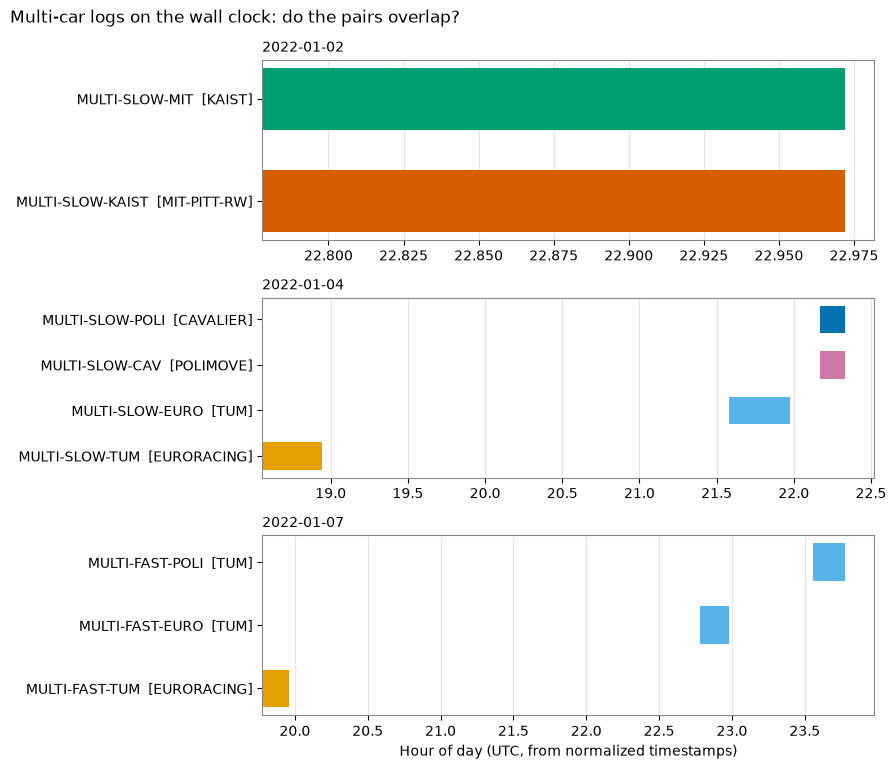

In [11]:
multi = scenes[scenes["name"].str.startswith("MULTI")].copy()
multi["start_h"] = (multi["t_min"] % 86400) / 3600       # hour of day, UTC
multi["dur_h"]   = multi["duration_s"] / 3600

dates = sorted(multi["date_captured"].unique())
fig, axes = plt.subplots(len(dates), 1, figsize=(9, 2.6 * len(dates)))
for ax, day in zip(axes, dates):
    g = multi[multi["date_captured"] == day].sort_values("start_h")
    ax.barh(g["name"] + "  [" + g["vehicle"] + "]", g["dur_h"], left=g["start_h"],
            color=g["vehicle"].map(TEAM_COLORS), height=0.6)
    ax.set_title(day, loc="left", fontsize=10)
    style(ax)
axes[-1].set_xlabel("Hour of day (UTC, from normalized timestamps)")
fig.suptitle("Multi-car logs on the wall clock: do the pairs overlap?", x=0.01, ha="left")
fig.tight_layout()
fig.savefig("figures/02_multi_timeline.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.11 Figure 1, corrected

The same figure is redrawn with explicit numeric tick positions, so that every scene has its own row even when labels are identical. This is the version that is kept in `figures/01_scene_overview.png`.

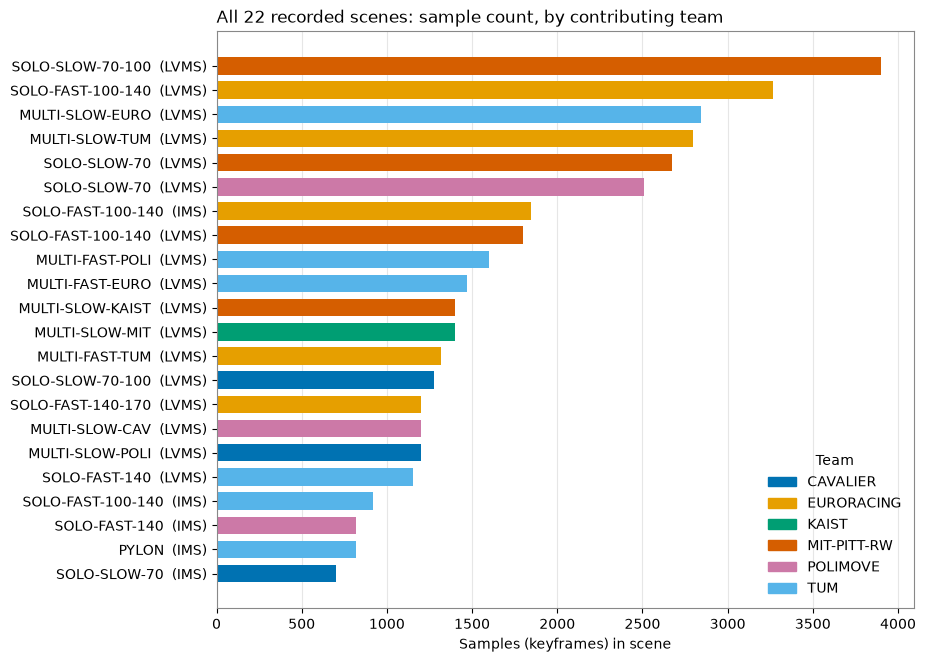

In [12]:
d = scenes.sort_values("n_samples").reset_index(drop=True)
labels = [f"{n}  ({l})" for n, l in zip(d["name"], d["location"])]

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(range(len(d)), d["n_samples"], color=d["vehicle"].map(TEAM_COLORS), height=0.72)
ax.set_yticks(range(len(d))); ax.set_yticklabels(labels)
ax.set_xlabel("Samples (keyframes) in scene")
ax.set_title("All 22 recorded scenes: sample count, by contributing team", loc="left")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TEAM_COLORS.values()]
ax.legend(handles, TEAM_COLORS.keys(), title="Team", loc="lower right", frameon=False)
style(ax)
fig.savefig("figures/01_scene_overview.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.12 The table `sample_data`

`sample_data.json` is the largest table (1,491,862 rows). Each row is one sensor reading, with the file name, the keyframe flag, the link to the pose of the car (`ego_pose_token`) and the link to the calibration. It is loaded once and stored as a pickle file, which makes later sessions much faster.

In [13]:
import gc
sd = pd.DataFrame(json.load(open(ROOT / "sample_data.json")))
print(len(sd), sd.columns.tolist())
sd.to_pickle(DATA / "sample_data.pkl")   # next session: pd.read_pickle(...) is much faster
sd.head(2)

1491862 ['calibrated_sensor_token', 'ego_pose_token', 'fileformat', 'filename', 'height', 'is_key_frame', 'next', 'prev', 'sample_token', 'timestamp', 'token', 'width']


,calibrated_sensor_token,ego_pose_token,fileformat,filename,height,is_key_frame,next,prev,sample_token,timestamp,token,width
0,390cba50cb07fc308fe3b5e5f4bee061,e393ef8fe703778f7a3574ff6eddfcbd,pcd.bin,samples/LIDAR_FRONT/SOLO-FAST-100-140__LIDAR_F...,0,True,a036f60f0af9e490cff3bf575130e768,,5933c81af5e770dffbbcf61fd9b37acc,1.641584e+08,993792a94260b3bc1cbebc6baa65f958,0
1,bc2ce79cde9e778e35140a40d2e16df1,e393ef8fe703778f7a3574ff6eddfcbd,pcd.bin,samples/LIDAR_LEFT/SOLO-FAST-100-140__LIDAR_LE...,0,True,f826f3c2d222690002cfa3fcc243c21b,,5933c81af5e770dffbbcf61fd9b37acc,1.641584e+08,96d5125de55d18d97cd31b8003ee44fd,0


### 1.13 Which sensors recorded in which log

The readings are joined to their channel and scene through the chain `sample_data` → `calibrated_sensor` → `sensor`, and `sample` → `scene`, and are then counted per channel. The table is restricted to the multi-car logs.

In [14]:
calib = load("calibrated_sensor")

chan = (sd[["sample_token", "calibrated_sensor_token"]]
        .merge(calib[["token", "sensor_token"]].rename(columns={"token": "calibrated_sensor_token"}),
               on="calibrated_sensor_token")
        .merge(sensor[["token", "channel"]].rename(columns={"token": "sensor_token"}),
               on="sensor_token")
        .merge(sample[["token", "scene_token"]].rename(columns={"token": "sample_token"}),
               on="sample_token")
        .merge(scenes[["token", "name", "vehicle"]].rename(columns={"token": "scene_token"}),
               on="scene_token"))

counts = chan.groupby(["name", "vehicle", "channel"]).size().unstack(fill_value=0)
mc = counts[counts.index.get_level_values("name").str.startswith("MULTI")]
mc

,channel,CAMERA_FRONT_LEFT,CAMERA_FRONT_LEFT_CENTER,CAMERA_FRONT_RIGHT,CAMERA_FRONT_RIGHT_CENTER,CAMERA_REAR_LEFT,CAMERA_REAR_RIGHT,LIDAR_FRONT,LIDAR_FUSED,LIDAR_LEFT,LIDAR_RIGHT,RADAR_FRONT
name,vehicle,,,,,,,,,,,
MULTI-FAST-EURO,TUM,0,0,0,0,0,0,0,14702,0,0,28882
MULTI-FAST-POLI,TUM,0,0,0,0,0,0,0,15954,0,0,32700
MULTI-FAST-TUM,EURORACING,0,0,0,0,0,0,13197,0,13197,13199,0
MULTI-SLOW-CAV,POLIMOVE,0,0,0,0,0,0,11188,0,11158,11171,0
MULTI-SLOW-EURO,TUM,0,0,0,0,0,0,0,28458,0,0,56465
MULTI-SLOW-KAIST,MIT-PITT-RW,3062,5092,4250,0,4803,4895,11928,0,10635,9683,29264
MULTI-SLOW-MIT,KAIST,0,0,0,0,0,0,13809,0,13324,13647,28219
MULTI-SLOW-POLI,CAVALIER,0,0,0,0,0,0,0,8349,0,0,0
MULTI-SLOW-TUM,EURORACING,0,0,0,0,0,0,28001,0,28001,28001,0


Only the log of MIT-PITT-RW contains camera images (five of the six camera channels; `CAMERA_FRONT_RIGHT_CENTER` is empty). The other cars recorded LiDAR and in some cases radar only, and some teams (TUM, CAVALIER) provide one fused LiDAR channel instead of three separate ones. This decides the roles in the video: MIT-PITT-RW is the camera car, and KAIST is the second car, whose position is known from its own log.

### 1.14 Figure 3: sensor coverage of the multi-car logs

The table above is shown as a heat map. Each cell is coloured by sensor type (camera, LiDAR, radar) if the sensor recorded, and the number of readings is printed in it. Partner logs sit next to each other, separated by white lines.

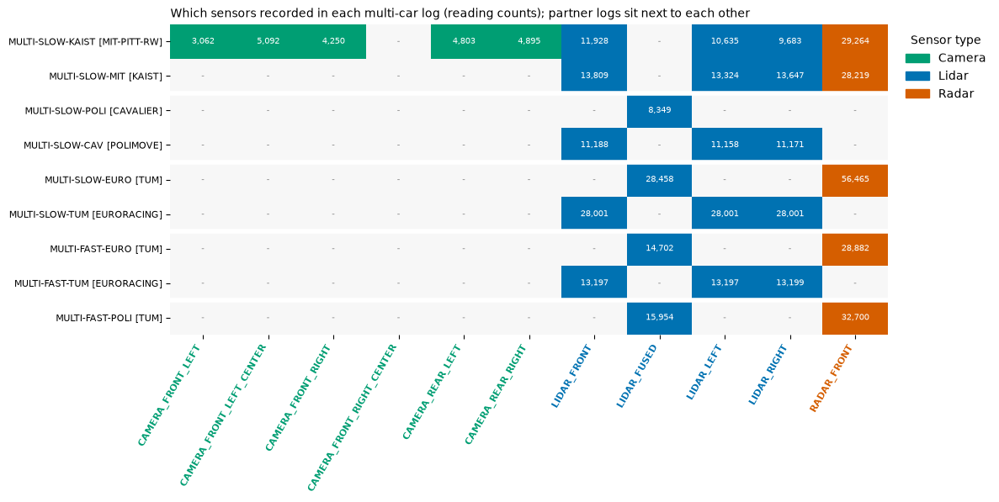

In [15]:
from matplotlib.colors import to_rgb
import numpy as np

MODALITY_COLORS = {"camera": "#009E73", "lidar": "#0072B2", "radar": "#D55E00"}
modality = lambda ch: ch.split("_")[0].lower()

order = [("MULTI-SLOW-KAIST", "MIT-PITT-RW"), ("MULTI-SLOW-MIT", "KAIST"),
         ("MULTI-SLOW-POLI", "CAVALIER"),    ("MULTI-SLOW-CAV", "POLIMOVE"),
         ("MULTI-SLOW-EURO", "TUM"),         ("MULTI-SLOW-TUM", "EURORACING"),
         ("MULTI-FAST-EURO", "TUM"),         ("MULTI-FAST-TUM", "EURORACING"),
         ("MULTI-FAST-POLI", "TUM")]
m = mc.loc[order]

# Build an RGB image: modality color where the sensor recorded, near-white where it didn't
rgb = np.ones((*m.shape, 3)) * 0.97
for j, ch in enumerate(m.columns):
    for i in range(m.shape[0]):
        if m.values[i, j] > 0:
            rgb[i, j] = to_rgb(MODALITY_COLORS[modality(ch)])

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.imshow(rgb, aspect="auto")
ax.set_xticks(range(m.shape[1])); ax.set_xticklabels(m.columns, rotation=60, ha="right", fontsize=8)
for lbl, ch in zip(ax.get_xticklabels(), m.columns):
    lbl.set_color(MODALITY_COLORS[modality(ch)]); lbl.set_fontweight("bold")
ax.set_yticks(range(len(m))); ax.set_yticklabels([f"{n} [{v}]" for n, v in m.index], fontsize=8)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        v = m.values[i, j]
        ax.text(j, i, f"{v:,}" if v else "-", ha="center", va="center", fontsize=7,
                color="white" if v else "#999")
for y in (1.5, 3.5, 5.5, 7.5):          # white separators between partner logs
    ax.axhline(y, color="white", lw=4)
ax.set_title("Which sensors recorded in each multi-car log (reading counts); partner logs sit next to each other",
             loc="left", fontsize=10)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in MODALITY_COLORS.values()]
ax.legend(handles, [k.capitalize() for k in MODALITY_COLORS], title="Sensor type",
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
for s in ax.spines.values(): s.set_visible(False)
fig.savefig("figures/03_channels_multi.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Data quality: the timestamp scale

Three tables carry timestamps: `sample`, `ego_pose` and `sample_data`. Each value is classified as 10 digits (the expected scale), 11 digits (inflated by a factor of ten) or other. The raw counts are printed because percentages can hide small groups, and Figure 4 shows the shares per table.

369264 ['rotation', 'timestamp', 'token', 'translation']
                         sample.json  ego_pose.json  sample_data.json
10-digit (correct)                 0          37023            128128
11-digit (inflated 10x)        38108         330553           1339310
other                              0           1688             24424


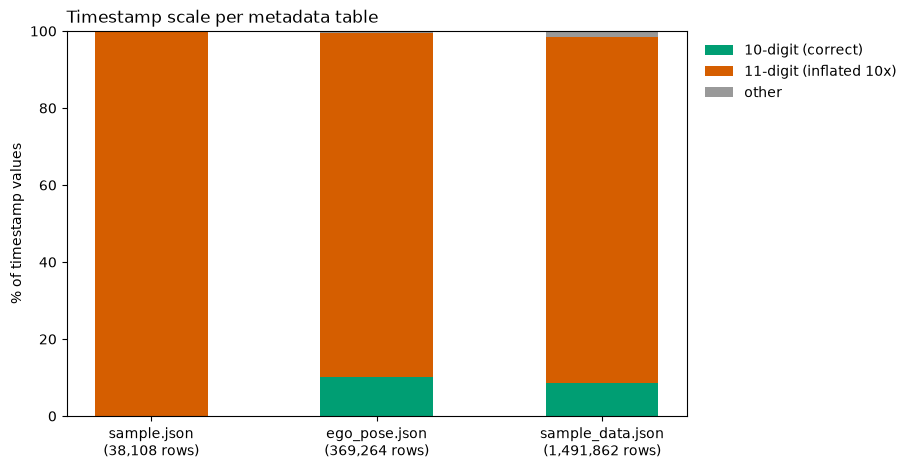

In [16]:
ego = load("ego_pose")                      # 135 MB, quick
print(len(ego), ego.columns.tolist())

def digit_class(ts):
    ts = pd.to_numeric(ts, errors="coerce")
    d = np.floor(np.log10(ts.where(ts > 0))) + 1      # number of digits per value
    return np.select([d == 10, d == 11], ["10-digit (correct)", "11-digit (inflated 10x)"], "other")

tables = {"sample.json": sample["timestamp"],
          "ego_pose.json": ego["timestamp"],
          "sample_data.json": sd["timestamp"]}
summary = (pd.DataFrame({k: pd.Series(digit_class(v)).value_counts() for k, v in tables.items()})
             .fillna(0).astype(int))
print(summary)           # raw counts: percentages can hide small groups

cats = ["10-digit (correct)", "11-digit (inflated 10x)", "other"]
pct = (summary / summary.sum() * 100).reindex(cats).fillna(0)
colors = ["#009E73", "#D55E00", "#999999"]

fig, ax = plt.subplots(figsize=(8, 5))
bottom = np.zeros(pct.shape[1])
for cat, c in zip(pct.index, colors):
    ax.bar(range(pct.shape[1]), pct.loc[cat].values, bottom=bottom, color=c, label=cat, width=0.5)
    bottom += pct.loc[cat].values
ax.set_xticks(range(pct.shape[1]))
ax.set_xticklabels([f"{k}\n({len(v):,} rows)" for k, v in tables.items()])
ax.set_ylabel("% of timestamp values"); ax.set_ylim(0, 100)
ax.set_title("Timestamp scale per metadata table", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.savefig("figures/04_timestamp_scale.png", dpi=200, bbox_inches="tight")
plt.show()

The result shows that no single correction factor is valid. All sample timestamps are inflated, but in `ego_pose` about 89.5 % of the values have 11 digits, 10.0 % have 10 digits and 1,688 values (0.5 %) have another format. In `sample_data` the shares are 89.8 % (11 digits), 8.6 % (10 digits) and 1.6 % (other). The normalisation per value from Section 1.6 therefore remains necessary. Values of the third category, for example 163961156.37, have only nine integer digits and cannot be rescaled reliably.

## 3. The two cars: trajectories and the choice of an overtake

### 3.1 Trajectories of MIT-PITT-RW and KAIST

For the two scenes of the chosen pair, one pose is taken for every `LIDAR_FRONT` reading, because both cars have this channel. The poses are joined to their own scene, so that each pose is attributed to the correct car. Every timestamp is normalised by its own digit count, and the horizontal position (x, y) is extracted from the translation. The result is 11,928 poses for MIT-PITT-RW and 13,809 for KAIST. Of these 25,737 values, 25,735 have 11 digits and two have 10 digits, which confirms that the correction per value is needed. Figure 5 shows the two paths; the dot marks the start.

timestamp
11    25735
10        2
Name: count, dtype: int64
                 n         t_min         t_max
vehicle                                       
KAIST        13809  1.641164e+09  1.641164e+09
MIT-PITT-RW  11928  1.641164e+09  1.641164e+09


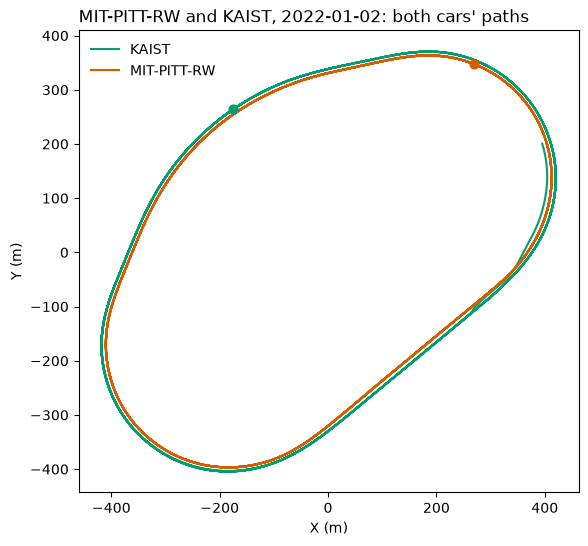

In [17]:
pair_scenes = scenes[scenes["name"].isin(["MULTI-SLOW-KAIST", "MULTI-SLOW-MIT"])][["token", "name", "vehicle"]]

# One ego pose per LIDAR_FRONT frame; both cars have this channel
lidar_sensor = sensor.loc[sensor["channel"] == "LIDAR_FRONT", "token"].iloc[0]
lidar_calibs = calib.loc[calib["sensor_token"] == lidar_sensor, "token"]
lf = sd.loc[sd["calibrated_sensor_token"].isin(lidar_calibs), ["sample_token", "ego_pose_token"]]

# Join sample -> scene so each pose belongs to exactly one car's own log
lf = (lf.merge(sample[["token", "scene_token"]].rename(columns={"token": "sample_token"}), on="sample_token")
        .merge(pair_scenes.rename(columns={"token": "scene_token"}), on="scene_token"))
traj = lf.merge(ego[["token", "timestamp", "translation"]].rename(columns={"token": "ego_pose_token"}),
                on="ego_pose_token")

# Normalize each timestamp by its own digit count
ts = traj["timestamp"].astype("float64")
digits = (np.floor(np.log10(ts)) + 1).astype(int)
print(digits.value_counts())
traj["t"] = ts / 10.0 ** (digits - 10)

xyz = np.array(traj["translation"].tolist())
traj["x"], traj["y"] = xyz[:, 0], xyz[:, 1]
traj = traj.sort_values(["vehicle", "t"]).reset_index(drop=True)
print(traj.groupby("vehicle").agg(n=("t", "size"), t_min=("t", "min"), t_max=("t", "max")))

CAR_COLORS = {"MIT-PITT-RW": "#D55E00", "KAIST": "#009E73"}
fig, ax = plt.subplots(figsize=(7, 6))
for veh, g in traj.groupby("vehicle"):
    ax.plot(g["x"], g["y"], color=CAR_COLORS[veh], lw=1.5, label=veh)
    ax.scatter(g["x"].iloc[0], g["y"].iloc[0], color=CAR_COLORS[veh], s=40, zorder=3)  # dot = start
ax.set_aspect("equal"); ax.legend(frameon=False)
ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
ax.set_title("MIT-PITT-RW and KAIST, 2022-01-02: both cars' paths", loc="left")
fig.savefig("figures/05_two_car_trajectories.png", dpi=200, bbox_inches="tight")
plt.show()

The two paths follow the same circuit, which indicates that both logs are expressed in the same global coordinate system. This is a precondition for computing the position of one car relative to the other.

### 3.2 Validating the timestamp correction

Two checks follow. The first tests whether the normalised pose times fall inside the time span of their own scene (with a margin of 10 s); the expected share is 1.0, and it is 1.0 for both cars. The second inspects the malformed `ego_pose` timestamps from Section 2. The values printed as examples have only nine integer digits, and none of the malformed values belongs to the poses used here (the trajectories contain only 10-digit and 11-digit values).

In [18]:
# 1) Do the normalized pose times fall inside their own scene's time span?
chk = traj.merge(scenes[["name", "vehicle", "t_min", "t_max"]], on=["name", "vehicle"])
chk["inside"] = (chk["t"] >= chk["t_min"] - 10) & (chk["t"] <= chk["t_max"] + 10)
print(chk.groupby("vehicle")["inside"].mean())     # want ~1.0 for both cars

# 2) What do the malformed ("other") ego_pose timestamps look like?
bad = ego.loc[digit_class(ego["timestamp"]) == "other", "timestamp"]
print(len(bad)); print(bad.head(10).tolist())

vehicle
KAIST          1.0
MIT-PITT-RW    1.0
Name: inside, dtype: float64


1688
[163961156.3706507, 163501094.01855806, 163501094.1168481, 163501094.21718356, 163501094.32063913, 163501094.41665536, 163501094.51728168, 163501094.61704606, 163501094.71629187, 163501094.81904307]


### 3.3 Relative position and detection of overtakes

The detection proceeds in four steps.

1. Both paths are interpolated onto a common 10 Hz time grid inside their overlap.
2. The heading of MIT-PITT-RW is estimated from its own motion (finite differences, smoothed over about one second). This avoids a dependence on the orientation stored in the data, which is examined only in Section 5.
3. The position of KAIST relative to MIT-PITT-RW is decomposed in MIT's own frame into an along-track gap (positive if KAIST is ahead), a lateral offset (positive if KAIST is on the left) and the Euclidean distance.
4. An overtake is defined as a change of sign of the along-track gap while the cars are closer than 40 m. The first and last two seconds are ignored because of edge effects of the smoothing.

Figure 6 shows the three quantities over time, with the detected passes as dashed lines.

t =  130.8 s | gap   7.3 m | lateral  -7.3 m | MIT-PITT-RW passes KAIST
t =  250.9 s | gap   7.9 m | lateral  -7.8 m | KAIST passes MIT-PITT-RW
t =  328.6 s | gap   7.4 m | lateral  -7.3 m | MIT-PITT-RW passes KAIST
t =  444.8 s | gap   6.8 m | lateral  -6.7 m | KAIST passes MIT-PITT-RW
t =  625.2 s | gap   6.9 m | lateral  -6.9 m | MIT-PITT-RW passes KAIST
5 crossings


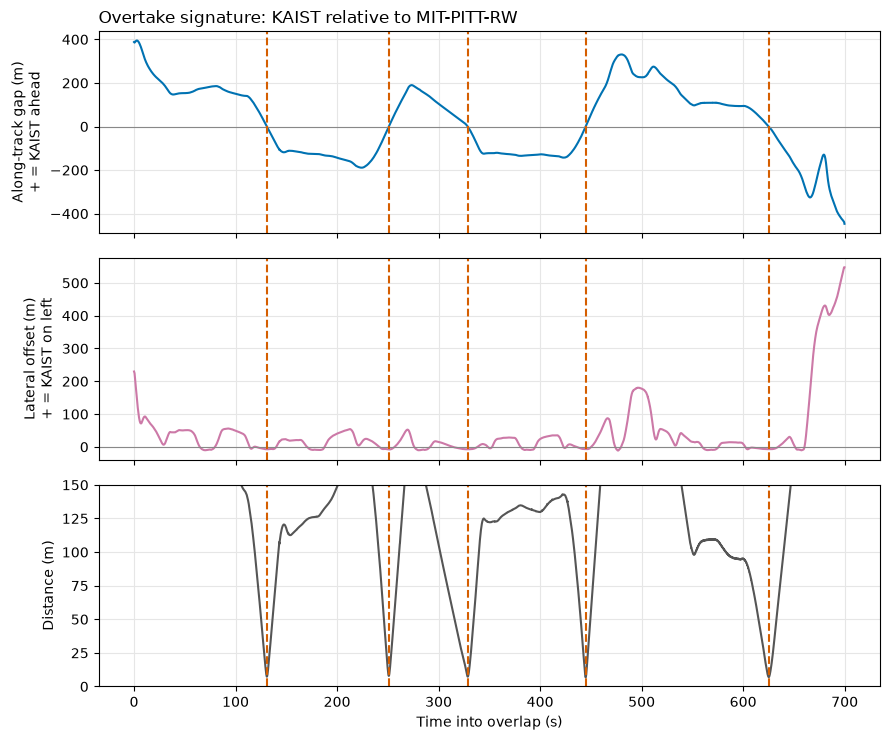

In [19]:
a = traj[traj["vehicle"] == "MIT-PITT-RW"].drop_duplicates("t").sort_values("t")   # camera car = reference
b = traj[traj["vehicle"] == "KAIST"].drop_duplicates("t").sort_values("t")

# Put both cars on one shared 10 Hz clock inside their overlap
t0, t1 = max(a["t"].min(), b["t"].min()), min(a["t"].max(), b["t"].max())
grid = np.arange(t0, t1, 0.1)
rs = lambda g, c: np.interp(grid, g["t"], g[c])
ax_, ay_, bx, by = rs(a, "x"), rs(a, "y"), rs(b, "x"), rs(b, "y")

# Reference car's heading from its own motion (finite difference, ~1 s smoothing).
# This avoids the quaternion-orientation question from the prompt for now.
smooth = lambda v, n=10: np.convolve(v, np.ones(n) / n, mode="same")
vx, vy = smooth(np.gradient(ax_, grid)), smooth(np.gradient(ay_, grid))
psi = np.arctan2(vy, vx)

# KAIST's position relative to MIT-PITT-RW, in MIT's own frame
dx, dy = bx - ax_, by - ay_
along = dx * np.cos(psi) + dy * np.sin(psi)    # + = KAIST ahead of MIT, - = behind
lat   = dy * np.cos(psi) - dx * np.sin(psi)    # + = KAIST on MIT's left, - = on its right
dist  = np.hypot(dx, dy)

# An overtake = along-track gap changes sign while the cars are genuinely close
ok = np.ones(len(grid), bool); ok[:20] = False; ok[-20:] = False   # ignore smoothing edge effects
cross = np.where(ok[:-1] & ok[1:] & (along[:-1] * along[1:] < 0) & (dist[:-1] < 40))[0]

ts_ = grid - grid[0]
for i in cross:
    who = "KAIST passes MIT-PITT-RW" if along[i] < 0 else "MIT-PITT-RW passes KAIST"
    print(f"t = {ts_[i]:6.1f} s | gap {dist[i]:5.1f} m | lateral {lat[i]:5.1f} m | {who}")
print(len(cross), "crossings")

fig, axs = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
axs[0].plot(ts_, along, color="#0072B2"); axs[0].set_ylabel("Along-track gap (m)\n+ = KAIST ahead")
axs[1].plot(ts_, lat, color="#CC79A7");   axs[1].set_ylabel("Lateral offset (m)\n+ = KAIST on left")
axs[2].plot(ts_, dist, color="#555");     axs[2].set_ylabel("Distance (m)"); axs[2].set_ylim(0, 150)
for ax in axs[:2]: ax.axhline(0, color="#888", lw=0.8)
for ax in axs:
    ax.grid(color="#e6e6e6")
    for i in cross: ax.axvline(ts_[i], color="#D55E00", ls="--")
axs[2].set_xlabel("Time into overlap (s)")
axs[0].set_title("Overtake signature: KAIST relative to MIT-PITT-RW", loc="left")
fig.tight_layout()
fig.savefig("figures/06_overtake_signature.png", dpi=200, bbox_inches="tight")
plt.show()

Five overtakes are found in the 699 s overlap, and they alternate between the cars: MIT-PITT-RW passes KAIST, KAIST passes MIT-PITT-RW, and so on. At the moment of passing, the distance between the cars is between 6.8 and 7.9 m, and the other car is each time about 7 m to the right (lateral offset between -6.7 and -7.8 m). The signature of an overtake in Figure 6 is therefore a zero crossing of the along-track gap, together with a minimum of the distance.

### 3.4 Speed, lap time and camera coverage

The speed of MIT-PITT-RW is computed from its path (converted to mph). The function `visits()` finds the earlier moments at which MIT was within 20 m of the same place, at least 30 s apart. The differences between these moments give the lap time, which is about 106 s here (for the first pass: 24.7 s, 130.8 s, 237.0 s, and so on). The speed at the five passes ranges from 50.0 to 69.8 mph. Finally, the number of camera frames per 5 s is counted for each camera channel of MIT-PITT-RW, and Figure 7 shows these counts over time with the passes as dashed lines.

crossing 1 at  130.8 s | MIT speed  66.4 mph | MIT was at this spot at t = ['24.7', '130.8', '237.0', '341.9', '438.7', '529.4', '619.2', '698.5']
crossing 2 at  250.9 s | MIT speed  50.0 mph | MIT was at this spot at t = ['37.2', '141.2', '250.9', '355.0', '451.1', '539.8', '629.3']
crossing 3 at  328.6 s | MIT speed  58.0 mph | MIT was at this spot at t = ['10.0', '118.1', '220.4', '328.6', '424.1', '517.1', '606.8', '683.9']
crossing 4 at  444.8 s | MIT speed  56.9 mph | MIT was at this spot at t = ['30.8', '135.9', '243.8', '348.6', '444.8', '534.5', '624.2']
crossing 5 at  625.2 s | MIT speed  69.8 mph | MIT was at this spot at t = ['32.0', '136.9', '245.2', '349.9', '446.0', '535.5', '625.2']
                          count       min         max
channel                                              
CAMERA_FRONT_LEFT          3062 -0.179059  698.747926
CAMERA_FRONT_LEFT_CENTER   5092 -0.239061  699.808822
CAMERA_FRONT_RIGHT         4250 -0.178284  699.593580
CAMERA_REAR_LEFT      

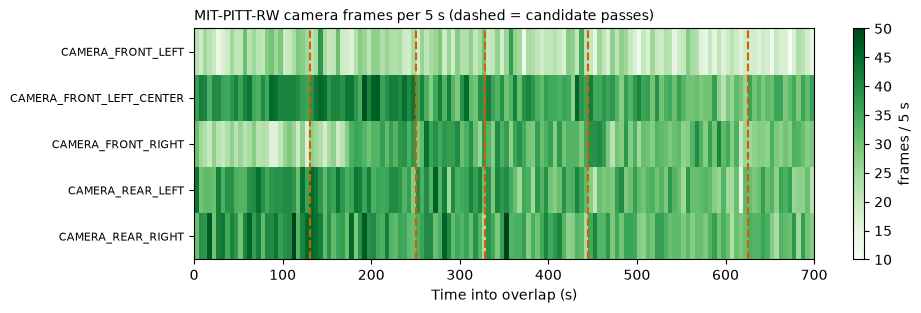

In [20]:
# Speed of the reference car, and "when was MIT at this spot before?" (lap time and lead-in)
speed_mph = np.hypot(np.gradient(ax_, grid), np.gradient(ay_, grid)) * 2.23694

def visits(i, radius=20, min_sep=30):
    d = np.hypot(ax_ - ax_[i], ay_ - ay_[i])
    near = np.where(d < radius)[0]
    groups = np.split(near, np.where(np.diff(near) > min_sep * 10)[0] + 1)   # grid is 10 Hz
    return [ts_[g[np.argmin(d[g])]] for g in groups if len(g)]

for k, i in enumerate(cross, 1):
    print(f"crossing {k} at {ts_[i]:6.1f} s | MIT speed {speed_mph[i]:5.1f} mph | "
          f"MIT was at this spot at t =", [f"{v:.1f}" for v in visits(i)])

# Camera coverage of MIT-PITT-RW over the same timeline
cam_sensors = (sensor.loc[sensor["channel"].str.startswith("CAMERA"), ["token", "channel"]]
                     .rename(columns={"token": "sensor_token"}))
cc = (calib[["token", "sensor_token"]].rename(columns={"token": "calibrated_sensor_token"})
          .merge(cam_sensors, on="sensor_token"))
mit_scene = scenes.loc[scenes["name"] == "MULTI-SLOW-KAIST", "token"].iloc[0]

cam = (sd[["sample_token", "calibrated_sensor_token", "timestamp"]]
       .merge(cc[["calibrated_sensor_token", "channel"]], on="calibrated_sensor_token")
       .merge(sample[["token", "scene_token"]].rename(columns={"token": "sample_token"}), on="sample_token"))
cam = cam[cam["scene_token"] == mit_scene].copy()
ts = cam["timestamp"].astype("float64")
dg = (np.floor(np.log10(ts)) + 1).astype(int)
cam["rel"] = ts / 10.0 ** (dg - 10) - grid[0]          # seconds into the overlap window

channels = sorted(cam["channel"].unique())
print(cam.groupby("channel")["rel"].agg(["count", "min", "max"]))

bins = np.arange(0, ts_[-1] + 5, 5)
cov = np.array([np.histogram(cam.loc[cam["channel"] == ch, "rel"], bins=bins)[0] for ch in channels])
fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(cov, aspect="auto", cmap="Greens", extent=[0, bins[-1], len(channels), 0])
ax.set_yticks(np.arange(len(channels)) + 0.5); ax.set_yticklabels(channels, fontsize=8)
for i in cross: ax.axvline(ts_[i], color="#D55E00", ls="--")
ax.set_xlabel("Time into overlap (s)")
ax.set_title("MIT-PITT-RW camera frames per 5 s (dashed = candidate passes)", loc="left", fontsize=10)
fig.colorbar(im, ax=ax, label="frames / 5 s")
fig.savefig("figures/07_camera_coverage.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.5 Choosing one pass (Figure 8)

The variable `K` selects which of the five passes is used. Pass 1 (at 130.8 s, MIT-PITT-RW overtaking KAIST at 66.4 mph) is selected. In this pass KAIST is first seen ahead of the camera car and then beside it. The last time MIT-PITT-RW was at the same place is 24.7 s, so the "lead-in lap" before the pass lasts about 106 s. During this lap the LiDAR of MIT-PITT-RW sweeps the whole track, which is the material for the map in the first piece of the video.

Figure 8 shows the paths with the lead-in lap highlighted (left) and the speed profile with the passes marked (right). The printed frame rates for the 20 s around the pass are 5.1 (front left), 8.0 (front left centre), 4.8 (front right), 8.4 (rear left) and 8.7 (rear right) frames per second. The front-right camera has the lowest rate, which becomes important in Section 6.6.

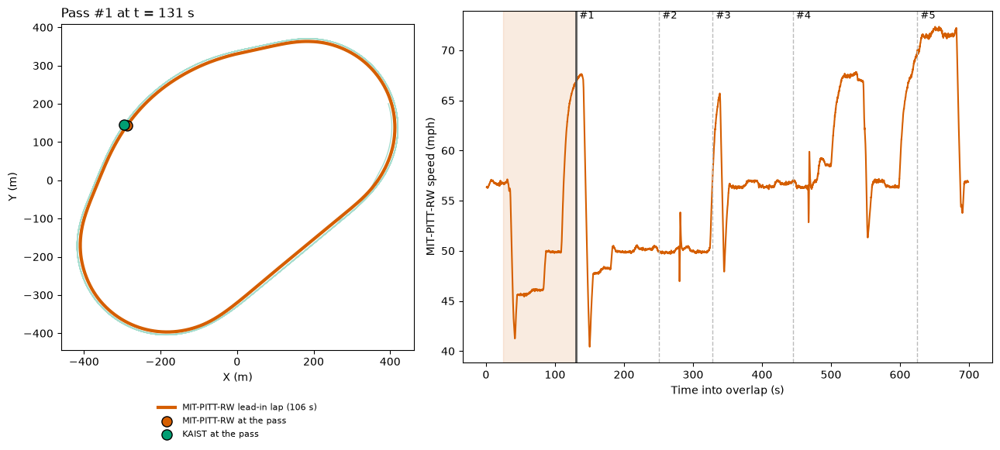

channel
CAMERA_FRONT_LEFT           5.1
CAMERA_FRONT_LEFT_CENTER    8.0
CAMERA_FRONT_RIGHT          4.8
CAMERA_REAR_LEFT            8.4
CAMERA_REAR_RIGHT           8.7
Name: frames per second, dtype: float64


In [21]:
K = 1                                 # which crossing (1 to 5); change it to compare passes
i = cross[K - 1]
prev = [v for v in visits(i) if v < ts_[i] - 30][-1]    # last time MIT was at this spot = start of lead-in lap
j0 = np.searchsorted(ts_, prev)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axs[0]
ax.plot(ax_, ay_, color="#D55E00", lw=1, alpha=0.35)
ax.plot(bx, by, color="#009E73", lw=1, alpha=0.35)
ax.plot(ax_[j0:i + 1], ay_[j0:i + 1], color="#D55E00", lw=3,
        label=f"MIT-PITT-RW lead-in lap ({ts_[i] - prev:.0f} s)")
ax.scatter(ax_[i], ay_[i], s=90, color="#D55E00", edgecolor="k", zorder=4, label="MIT-PITT-RW at the pass")
ax.scatter(bx[i], by[i], s=90, color="#009E73", edgecolor="k", zorder=4, label="KAIST at the pass")
ax.set_aspect("equal")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1)
ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
ax.set_title(f"Pass #{K} at t = {ts_[i]:.0f} s", loc="left")

ax = axs[1]
ax.plot(ts_[10:-10], smooth(speed_mph)[10:-10], color="#D55E00")
for k, j in enumerate(cross, 1):
    ax.axvline(ts_[j], color="#555" if k == K else "#bbb", ls="-" if k == K else "--", lw=2 if k == K else 1)
    ax.text(ts_[j], ax.get_ylim()[1], f" #{k}", va="top", fontsize=9)
ax.axvspan(prev, ts_[i], color="#D55E00", alpha=0.12)
ax.set_xlabel("Time into overlap (s)"); ax.set_ylabel("MIT-PITT-RW speed (mph)")
fig.tight_layout()
fig.savefig("figures/08_phase1_summary.png", dpi=200, bbox_inches="tight")
plt.show()

# Camera frame rate in the 20 s around the pass
win = cam[(cam["rel"] > ts_[i] - 10) & (cam["rel"] < ts_[i] + 10)]
print((win.groupby("channel").size() / 20).round(1).rename("frames per second"))

The choice is stored in `data/phase1_choice.json`: the time of the pass, the start of the lead-in lap, the two vehicles and scenes, and the geometry at the pass (gap 7.33 m, lateral offset -7.31 m). Later cells reload this file, so the analysis above does not have to be repeated.

In [22]:
import json
choice = {
    "pass_number": int(K),
    "t_unix": float(grid[i]),                    # absolute time of the pass
    "t_into_overlap_s": float(ts_[i]),
    "lead_in_start_unix": float(grid[j0]),       # start of the one-lap lead-in
    "camera_vehicle": "MIT-PITT-RW", "camera_scene": "MULTI-SLOW-KAIST",
    "other_vehicle": "KAIST",        "other_scene": "MULTI-SLOW-MIT",
    "gap_m": float(dist[i]), "lateral_m": float(lat[i]),
}
(DATA / "phase1_choice.json").write_text(json.dumps(choice, indent=2))
print(choice)

{'pass_number': 1, 't_unix': 1641163730.9548717, 't_into_overlap_s': 130.7998752593994, 'lead_in_start_unix': 1641163624.8549728, 'camera_vehicle': 'MIT-PITT-RW', 'camera_scene': 'MULTI-SLOW-KAIST', 'other_vehicle': 'KAIST', 'other_scene': 'MULTI-SLOW-MIT', 'gap_m': 7.3312613382162635, 'lateral_m': -7.309283314243523}


## 4. Downloading only what is needed

The archives of the multi-car runs are very large (12.7 to 42.7 GB each; the one of MIT-PITT-RW is 29.4 GB). Downloading a complete archive for a few seconds of data would be wasteful, so the next cells determine the exact files required and extract only those. The first cell lists the archives in the bucket with their sizes.

In [23]:
resp = s3.list_objects_v2(Bucket="racecar-dataset", Prefix="RACECAR-nuScenes/MULTI-SLOW/")
for o in resp.get("Contents", []):
    print(f"{o['Size'] / 1e9:6.1f} GB  {o['Key']}")

  12.7 GB  RACECAR-nuScenes/MULTI-SLOW/CAVALIER_MULTI-SLOW-POLI.tar
  42.7 GB  RACECAR-nuScenes/MULTI-SLOW/EURORACING_MULTI-SLOW-TUM.tar
  19.8 GB  RACECAR-nuScenes/MULTI-SLOW/KAIST_MULTI-SLOW-MIT.tar
  29.4 GB  RACECAR-nuScenes/MULTI-SLOW/MIT-PITT-RW_MULTI-SLOW-KAIST.tar
  16.8 GB  RACECAR-nuScenes/MULTI-SLOW/POLIMOVE_MULTI-SLOW-CAV.tar
  41.9 GB  RACECAR-nuScenes/MULTI-SLOW/TUM_MULTI-SLOW-EURO.tar


### 4.1 Which files are needed

Two time windows are defined around the chosen pass. The LiDAR window runs from five seconds before the start of the lead-in lap to 30 s after the pass. The camera window runs from 20 s before to 30 s after the pass. For LiDAR only keyframes are used. For the cameras both keyframes and sweeps (the additional frames between keyframes) are taken, to obtain as many images as possible.

The file names are obtained with the same join chain as in Section 1.13. The timestamps come from the metadata (normalised per value) and are never read from the file names. The result is 2,514 files, for example 282 LiDAR keyframes per LiDAR channel and, for `CAMERA_FRONT_RIGHT`, 89 keyframes and 143 sweeps. The list of wanted files is saved in `data/member_list.txt`.

In [24]:
choice = json.loads((DATA / "phase1_choice.json").read_text())
t_pass = choice["t_unix"]
LIDAR_WIN = (choice["lead_in_start_unix"] - 5, t_pass + 30)   # lead-in lap start, 5 s margin, to 30 s after the pass
CAM_WIN   = (t_pass - 20, t_pass + 30)                        # camera frames around the pass only

mit_scene = scenes.loc[scenes["name"] == choice["camera_scene"], "token"].iloc[0]

# Same join chain as before, this time keeping the filename
ch = (calib[["token", "sensor_token"]].rename(columns={"token": "calibrated_sensor_token"})
        .merge(sensor[["token", "channel"]].rename(columns={"token": "sensor_token"}), on="sensor_token"))
w = (sd.merge(sample[["token", "scene_token"]].rename(columns={"token": "sample_token"}), on="sample_token")
       .merge(ch[["calibrated_sensor_token", "channel"]], on="calibrated_sensor_token"))
w = w[w["scene_token"] == mit_scene].copy()

# Timestamps come from the metadata (normalized per value), never parsed from filenames
ts = w["timestamp"].astype("float64")
dg = (np.floor(np.log10(ts)) + 1).astype(int)
w["t"] = ts / 10.0 ** (dg - 10)

is_lidar = w["channel"].isin(["LIDAR_FRONT", "LIDAR_LEFT", "LIDAR_RIGHT"]) & w["is_key_frame"]
is_cam   = w["channel"].str.startswith("CAMERA")
want = w[(is_lidar & w["t"].between(*LIDAR_WIN)) | (is_cam & w["t"].between(*CAM_WIN))].copy()
want["kind"] = np.where(want["is_key_frame"], "keyframe", "sweep")

print(want.groupby(["channel", "kind"]).size().unstack(fill_value=0))
print(len(want), "files in total")
for c in ["LIDAR_FRONT", "CAMERA_FRONT_RIGHT"]:
    print(want.loc[want["channel"] == c, "filename"].head(2).tolist())

want["filename"].to_csv(DATA / "member_list.txt", index=False, header=False)

kind                      keyframe  sweep
channel                                  
CAMERA_FRONT_LEFT               94    162
CAMERA_FRONT_LEFT_CENTER       100    301
CAMERA_FRONT_RIGHT              89    143
CAMERA_REAR_LEFT                99    280
CAMERA_REAR_RIGHT              101    299
LIDAR_FRONT                    282      0
LIDAR_LEFT                     282      0
LIDAR_RIGHT                    282      0
2514 files in total
['samples/LIDAR_FRONT/MULTI-SLOW-KAIST__LIDAR_FRONT__1641163620156177664.pcd.bin', 'samples/LIDAR_FRONT/MULTI-SLOW-KAIST__LIDAR_FRONT__1641163620507481856.pcd.bin']
['samples/CAMERA_FRONT_RIGHT/MULTI-SLOW-KAIST__CAMERA_FRONT_RIGHT__1641163711289653700.jpg', 'sweeps/CAMERA_FRONT_RIGHT/MULTI-SLOW-KAIST__CAMERA_FRONT_RIGHT__1641163711374135300.jpg']


### 4.2 Inspecting the archive without downloading it

The tar file is opened in streaming mode (`"r|"`), and only the first 16 entries are printed. The archive contains the folders `samples/` and `sweeps/` with one subfolder per channel, and the entries appear to be stored in chronological order. This makes it possible to stop reading as soon as the time window has been passed.

In [25]:
KEY = "RACECAR-nuScenes/MULTI-SLOW/MIT-PITT-RW_MULTI-SLOW-KAIST.tar"
obj = s3.get_object(Bucket="racecar-dataset", Key=KEY)
with tarfile.open(fileobj=obj["Body"], mode="r|") as tf:     # "r|" = sequential streaming mode
    for n, m in enumerate(tf):
        print(m.name, m.size)
        if n >= 15: break
obj["Body"].close()

samples/RADAR_FRONT/MULTI-SLOW-KAIST__RADAR_FRONT__1641163599999341000.pcd 452
samples/CAMERA_REAR_RIGHT/MULTI-SLOW-KAIST__CAMERA_REAR_RIGHT__1641163599891442800.jpg 644397
samples/LIDAR_FRONT/MULTI-SLOW-KAIST__LIDAR_FRONT__16411636004803328.pcd.bin 517460
samples/LIDAR_RIGHT/MULTI-SLOW-KAIST__LIDAR_RIGHT__16411636004231936.pcd.bin 473480
samples/LIDAR_LEFT/MULTI-SLOW-KAIST__LIDAR_LEFT__16411636006187008.pcd.bin 505380
sweeps/RADAR_FRONT/MULTI-SLOW-KAIST__RADAR_FRONT__164116360099000.pcd 452
samples/CAMERA_FRONT_LEFT_CENTER/MULTI-SLOW-KAIST__CAMERA_FRONT_LEFT_CENTER__1641163599915935100.jpg 758697
sweeps/RADAR_FRONT/MULTI-SLOW-KAIST__RADAR_FRONT__16411636002346000.pcd 452
sweeps/RADAR_FRONT/MULTI-SLOW-KAIST__RADAR_FRONT__164116360038338000.pcd 1185
sweeps/LIDAR_FRONT/MULTI-SLOW-KAIST__LIDAR_FRONT__164116360054798592.pcd.bin 519540
sweeps/LIDAR_RIGHT/MULTI-SLOW-KAIST__LIDAR_RIGHT__164116360054899200.pcd.bin 473520
samples/CAMERA_REAR_LEFT/MULTI-SLOW-KAIST__CAMERA_REAR_LEFT__164116359984

### 4.3 Streaming extraction

The archive is read sequentially from S3 and only the 2,514 wanted files are written to disk (`data/raw_mit/`). The reading stops as soon as all files have been found, or when the file names indicate a time more than 30 s beyond the window. For this coarse stopping rule only the first ten digits of the file name (whole seconds) are used, because the remaining digits are not reliable. Progress is printed every 5,000 entries.

All 2,514 files were found (none missing). The extraction took 421 s and occupies 1.45 GB on disk, which is a small fraction of the 29.4 GB archive.

In [26]:
import re, time

KEY = "RACECAR-nuScenes/MULTI-SLOW/MIT-PITT-RW_MULTI-SLOW-KAIST.tar"
OUT = DATA / "raw_mit"; OUT.mkdir(exist_ok=True)   # same samples/... and sweeps/... paths as in the metadata
wanted = set(want["filename"])
STOP_SEC = int(max(LIDAR_WIN[1], CAM_WIN[1])) + 30  # give up if we read 30 s past the window

def sec_of(name):
    m = re.search(r"__(\d{10})\d*\.", name)         # first 10 digits = whole seconds; the rest is unreliable
    return int(m.group(1)) if m else None

found, seen, t_start = set(), 0, time.time()
obj = s3.get_object(Bucket="racecar-dataset", Key=KEY)
try:
    with tarfile.open(fileobj=obj["Body"], mode="r|") as tf:   # sequential streaming, nothing stored but our files
        for m in tf:
            seen += 1
            if m.name in wanted:
                if not (OUT / m.name).exists():
                    tf.extract(m, OUT, filter="data")
                found.add(m.name)
                if len(found) == len(wanted):
                    break                                    # got everything: stop reading the tar
            elif (s := sec_of(m.name)) is not None and s > STOP_SEC:
                break                                        # past the window: stop and report what's missing
            if seen % 5000 == 0:
                print(f"{tf.offset / 1e9:5.1f} GB read | {len(found)}/{len(wanted)} found | {time.time() - t_start:5.0f} s")
finally:
    obj["Body"].close()

missing = wanted - found
print(f"{len(found)}/{len(wanted)} found, {len(missing)} missing, {time.time() - t_start:.0f} s")
print(sorted(missing)[:5])
size = sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file())
print(f"{size / 1e9:.2f} GB on disk")

  1.8 GB read | 126/2514 found |   105 s
  3.6 GB read | 366/2514 found |   203 s
  5.4 GB read | 918/2514 found |   308 s
2514/2514 found, 0 missing, 416 s
[]
1.45 GB on disk


## 5. From raw LiDAR points to the camera image

### 5.1 Reading one LiDAR scan

A `.pcd.bin` file is a plain binary array of 32-bit floats. The file is read, reshaped into rows of five values (x, y, z, intensity, ring) and checked: the number of values (127,365) is divisible by five, which gives 25,473 points, and the ranges are plausible (x from 0.6 to 236 m, z from -0.7 to 31 m). The fifth column is zero for all points and therefore carries no information. Figure 9 shows one scan from above, coloured by intensity, in the coordinate frame of the sensor itself and not yet in that of the car.

127365 values; remainder when divided by 5: 0
              x         y         z  intensity     ring
count  25473.00  25473.00  25473.00   25473.00  25473.0
mean      33.84     -2.68      2.22       0.11      0.0
std       40.85     21.92      4.12       0.12      0.0
min        0.60    -69.54     -0.68       0.00      0.0
25%        9.98    -12.97     -0.35       0.04      0.0
50%       18.10     -5.60      0.79       0.08      0.0
75%       38.96      6.23      2.79       0.12      0.0
max      236.04    118.76     31.03       2.00      0.0


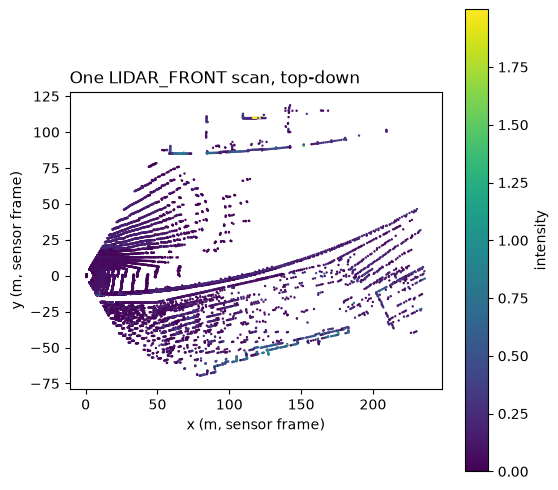

In [27]:
lidar_files = want.loc[want["channel"] == "LIDAR_FRONT", "filename"].tolist()
pts = np.fromfile(OUT / lidar_files[0], dtype=np.float32)
print(pts.size, "values; remainder when divided by 5:", pts.size % 5)
pts = pts.reshape(-1, 5)
cols = ["x", "y", "z", "intensity", "ring"]          # assumed layout: check it against the ranges below
print(pd.DataFrame(pts, columns=cols).describe().round(2))

fig, ax = plt.subplots(figsize=(6, 6))
sc = ax.scatter(pts[:, 0], pts[:, 1], c=pts[:, 3], s=0.5, cmap="viridis")
ax.set_aspect("equal"); ax.set_xlabel("x (m, sensor frame)"); ax.set_ylabel("y (m, sensor frame)")
ax.set_title("One LIDAR_FRONT scan, top-down", loc="left")
fig.colorbar(sc, ax=ax, label="intensity")
fig.savefig("figures/09_lidar_scan.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.2 The orientation of the car: a 90 degree error

To place the scans of a moving car in a common frame, the orientation of the car is needed. It is stored as a quaternion `[w, x, y, z]`. The function `quat_to_rot` converts it into a rotation matrix and `yaw_rot` builds a rotation about the vertical axis.

The stored orientation is tested against a quantity that does not depend on it: the direction in which the car is actually moving. For all moments with a speed above 5 m/s, the difference between the direction of motion and the "forward" direction of the rotation matrix is computed. Before any correction, this difference has a median of 90.1 degrees (5th to 95th percentile: 89.8 to 90.3 degrees). The offset is therefore almost constant, which points to a different convention for the forward axis in the stored rotation, and not to noise. Adding a yaw rotation of +90 degrees (`YAW_FIX_DEG`) reduces the median to 0.07 degrees, with 100 % of the values within 2 degrees. Figure 10 shows both cases.

From here on, the rotation from the vehicle frame to the global frame is always `quat_to_rot(q) @ yaw_rot(+90 degrees)`, where the vehicle frame has its x axis pointing forward and its y axis to the left.

BEFORE: median   90.1 deg | 5-95%:   89.8 ..   90.3
AFTER (fix +90 deg): median  0.07 | 5-95%: -0.19 ..  0.34 | within 2 deg: 100%


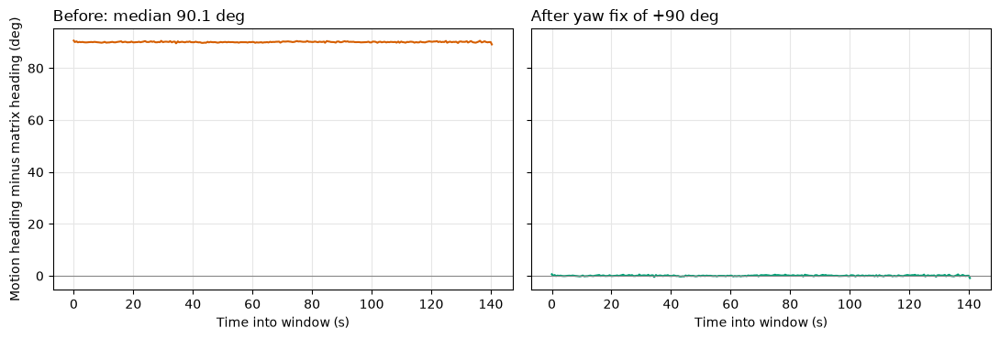

In [28]:
def quat_to_rot(q):                                   # q = [w, x, y, z]
    w, x, y, z = np.asarray(q, float) / np.linalg.norm(q)
    return np.array([[1-2*(y*y+z*z), 2*(x*y-z*w),   2*(x*z+y*w)],
                     [2*(x*y+z*w),   1-2*(x*x+z*z), 2*(y*z-x*w)],
                     [2*(x*z-y*w),   2*(y*z+x*w),   1-2*(x*x+y*y)]])

def yaw_rot(deg):
    a = np.deg2rad(deg); c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

wrap = lambda d: (d + 180) % 360 - 180               # keep angle differences in [-180, 180)

lf = want.loc[want["channel"] == "LIDAR_FRONT", ["filename", "ego_pose_token", "t"]]
poses = (lf.merge(ego[["token", "translation", "rotation"]].rename(columns={"token": "ego_pose_token"}),
                  on="ego_pose_token").sort_values("t").reset_index(drop=True))

P = np.array(poses["translation"].tolist()); tt = poses["t"].to_numpy()
vel = np.gradient(P[:, :2], tt, axis=0)
speed = np.hypot(vel[:, 0], vel[:, 1])
psi_motion = np.degrees(np.arctan2(vel[:, 1], vel[:, 0]))     # where the car is actually going

def heading_from_rot(fix_deg=0.0):                            # where the rotation matrix says "forward" is
    return np.array([np.degrees(np.arctan2((quat_to_rot(q) @ yaw_rot(fix_deg))[1, 0],
                                           (quat_to_rot(q) @ yaw_rot(fix_deg))[0, 0]))
                     for q in poses["rotation"]])

ok = speed > 5                                                # ignore near-standstill frames, where direction is noisy
before = wrap(psi_motion - heading_from_rot(0))[ok]
delta = float(np.median(before))
print(f"BEFORE: median {delta:6.1f} deg | 5-95%: {np.percentile(before, 5):6.1f} .. {np.percentile(before, 95):6.1f}")

YAW_FIX_DEG = float(np.round(delta))
after = wrap(psi_motion - heading_from_rot(YAW_FIX_DEG))[ok]
print(f"AFTER (fix {YAW_FIX_DEG:+.0f} deg): median {np.median(after):5.2f} | "
      f"5-95%: {np.percentile(after, 5):5.2f} .. {np.percentile(after, 95):5.2f} | within 2 deg: {np.mean(np.abs(after) < 2):.0%}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axs[0].plot(tt[ok] - tt[0], before, color="#D55E00"); axs[0].set_title(f"Before: median {delta:.1f} deg", loc="left")
axs[1].plot(tt[ok] - tt[0], after, color="#009E73");  axs[1].set_title(f"After yaw fix of {YAW_FIX_DEG:+.0f} deg", loc="left")
for ax in axs:
    ax.axhline(0, color="#888", lw=0.8); ax.grid(color="#e6e6e6"); ax.set_xlabel("Time into window (s)")
axs[0].set_ylabel("Motion heading minus matrix heading (deg)")
fig.tight_layout()
fig.savefig("figures/10_heading_check.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.3 A test of the corrected orientation: where is KAIST?

A direct test follows. Four seconds before the pass, KAIST should be a few tens of metres ahead of MIT-PITT-RW. The three LiDARs of one keyframe are moved into the vehicle frame with their own calibration (rotation and translation), MIT-PITT-RW is placed at the origin, and the position of KAIST is predicted from its trajectory and the pose of MIT-PITT-RW. In Figure 11, the predicted position is marked by a circle, once with the correction (panel A) and once with the orientation as stored (panel B).

With the correction, KAIST is predicted at (33.8, -5.9) m, which means about 34 m ahead and 6 m to the right. Without it, the prediction is (5.9, 33.8) m, about 34 m to the left, which contradicts the relative position found in Section 3.3. If the correction is right, the circle in panel A should enclose a compact group of LiDAR points and the circle in panel B should lie in empty space.

A: ego rotation + 90 deg: predicted KAIST position in vehicle frame (x, y) = [33.8 -5.9]
B: ego rotation as stored: predicted KAIST position in vehicle frame (x, y) = [ 5.9 33.8]


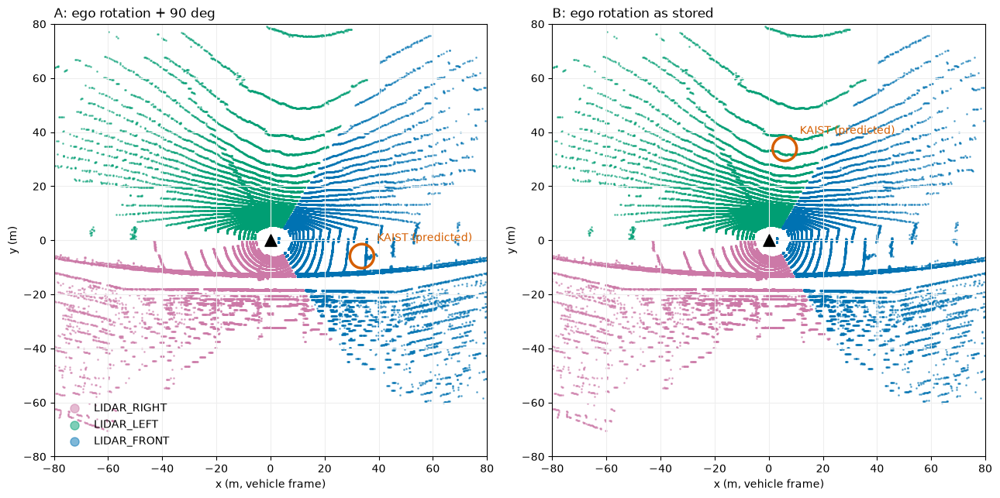

In [29]:
DT = -4                                           # seconds relative to the pass; KAIST is a few metres ahead then
i_scan = (poses["t"] - (t_pass + DT)).abs().idxmin()
pose = poses.loc[i_scan]; t_scan = pose["t"]
p_ego = np.array(pose["translation"], float)

kaist = traj[traj["vehicle"] == "KAIST"].sort_values("t")
p_kaist = np.array([np.interp(t_scan, kaist["t"], kaist["x"]),
                    np.interp(t_scan, kaist["t"], kaist["y"]), p_ego[2]])

# All three LiDARs of this keyframe, each moved into the vehicle frame with its own calibration
this_sample = want.loc[want["filename"] == pose["filename"], "sample_token"].iloc[0]
scan_rows = want[(want["sample_token"] == this_sample) & want["channel"].str.startswith("LIDAR")]
cloud = []
for _, r in scan_rows.iterrows():
    pts = np.fromfile(OUT / r["filename"], dtype=np.float32).reshape(-1, 5)[:, :3].astype(float)
    c = calib.loc[calib["token"] == r["calibrated_sensor_token"]].iloc[0]
    cloud.append((r["channel"], pts @ quat_to_rot(c["rotation"]).T + np.array(c["translation"], float)))

LCOL = {"LIDAR_FRONT": "#0072B2", "LIDAR_LEFT": "#009E73", "LIDAR_RIGHT": "#CC79A7"}
fig, axs = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, fix, title in [(axs[0], YAW_FIX_DEG, f"A: ego rotation + {YAW_FIX_DEG:.0f} deg"),
                       (axs[1], 0.0,         "B: ego rotation as stored")]:
    R_used = quat_to_rot(pose["rotation"]) @ yaw_rot(fix)
    pred = R_used.T @ (p_kaist - p_ego)           # KAIST in MIT's vehicle frame
    for ch, pc in cloud:
        ax.scatter(pc[:, 0], pc[:, 1], s=1, alpha=0.5, color=LCOL[ch], label=ch)
    ax.scatter(0, 0, marker="^", s=120, color="k", zorder=6)               # MIT-PITT-RW at the origin
    ax.scatter(*pred[:2], s=500, facecolor="none", edgecolor="#D55E00", lw=2.5, zorder=5)
    ax.annotate("KAIST (predicted)", pred[:2], textcoords="offset points", xytext=(14, 14), color="#D55E00")
    ax.set_xlim(-80, 80); ax.set_ylim(-80, 80); ax.set_aspect("equal")
    ax.set_xlabel("x (m, vehicle frame)"); ax.set_ylabel("y (m)")
    ax.set_title(title, loc="left"); ax.grid(color="#eee")
    print(f"{title}: predicted KAIST position in vehicle frame (x, y) = {pred[:2].round(1)}")
axs[0].legend(markerscale=8, frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("figures/11_kaist_prediction.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.4 A reusable function, and the clock offset between the two cars

The function `vehicle_cloud_and_pred(dt)` collects the three LiDARs of the keyframe closest to the time `dt` seconds after the pass, moves them into the vehicle frame, and predicts the position of KAIST in that frame. It returns the point cloud, the predicted position and the exact time difference to the pass.

The two cars logged on separate computers, so their clocks may not agree exactly. The parameter `KAIST_DT` expresses this: the position of KAIST is read from its trajectory at the time of the MIT scan plus `KAIST_DT`. It starts at 0 here and is tuned in the next cell.

In [30]:
KAIST_DT = 0.0   # seconds: look up KAIST's position at (MIT time + KAIST_DT)

def vehicle_cloud_and_pred(dt, fix=YAW_FIX_DEG):
    i = (poses["t"] - (t_pass + dt)).abs().idxmin()
    pose = poses.loc[i]; t_s = pose["t"]
    p_ego = np.array(pose["translation"], float)

    kaist = traj[traj["vehicle"] == "KAIST"].sort_values("t")
    t_k = t_s + KAIST_DT
    p_k = np.array([np.interp(t_k, kaist["t"], kaist["x"]),
                    np.interp(t_k, kaist["t"], kaist["y"]),
                    p_ego[2]])

    smp = want.loc[want["filename"] == pose["filename"], "sample_token"].iloc[0]
    rows = want[(want["sample_token"] == smp) & want["channel"].str.startswith("LIDAR")]
    parts = []
    for _, r in rows.iterrows():
        pts = np.fromfile(OUT / r["filename"], dtype=np.float32).reshape(-1, 5)[:, :3].astype(float)
        c = calib.loc[calib["token"] == r["calibrated_sensor_token"]].iloc[0]
        parts.append(pts @ quat_to_rot(c["rotation"]).T + np.array(c["translation"], float))

    pred = (quat_to_rot(pose["rotation"]) @ yaw_rot(fix)).T @ (p_k - p_ego)
    return np.vstack(parts), pred, t_s - t_pass

### 5.5 Projecting the LiDAR into the camera image, and calibrating the clock offset (Figure 13)

A LiDAR point `p` in the vehicle frame is moved into the frame of a camera by `p_cam = (p - t_cam) @ R_cam`, where `R_cam` and `t_cam` come from the calibration. Points behind the camera (depth below 0.5 m) are discarded. For the others, the pixel coordinates follow from the intrinsic matrix `K`:

$$u = f_x \, \frac{X}{Z} + c_x, \qquad v = f_y \, \frac{Y}{Z} + c_y .$$

The cell draws the photograph of `CAMERA_FRONT_RIGHT` at 3 s before the pass, the projected LiDAR points coloured by depth (semi-transparent, `ALPHA = 0.2`), and a ring at the predicted position of KAIST. The height of the ring is the local ground level (10th percentile of z within 8 m) plus 0.6 m, and its radius corresponds to about 1.5 m.

The ring tests the time alignment. At about 28 m/s, an error of 0.12 s corresponds to about 3.4 m, which is more than the length of a car. `KAIST_DT` was therefore adjusted until the ring was centred on the car, and a value of -0.12 s was found. In the printed output, 23,622 of 79,847 LiDAR points fall inside the image, and KAIST appears at pixel (267, 425) at a depth of 16.9 m. The scan itself was recorded 2.85 s before the pass.

23622 of 79847 LiDAR points land inside the CAMERA_FRONT_RIGHT image
KAIST pixel: [[267.1543349  425.40194621]] depth: [16.91139052] | real dt of scan vs pass: -2.85


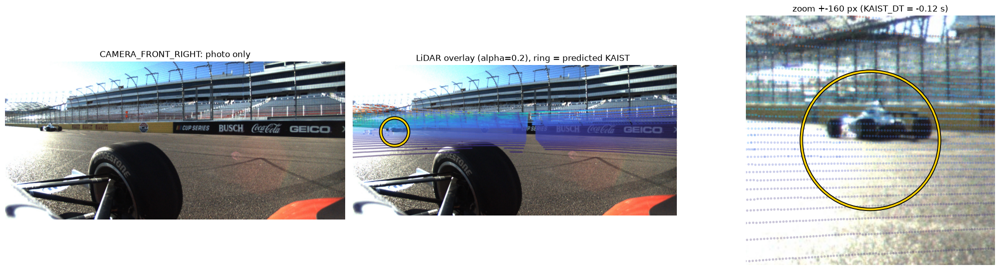

In [31]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.image import imread

CAM       = "CAMERA_FRONT_RIGHT"   # also try CAMERA_FRONT_LEFT / CAMERA_FRONT_LEFT_CENTER
DT        = -3                     # seconds relative to the pass (try -3, -2, -1)
KAIST_DT  = -0.12                   # <- tune this: 0.05 ... 0.15
ALPHA     = 0.2

cloud, pred, dt_real = vehicle_cloud_and_pred(DT)

# the keyframe photo that belongs to the same sample as the LiDAR scan
i   = (poses["t"] - (t_pass + DT)).abs().idxmin()
smp = want.loc[want["filename"] == poses.loc[i, "filename"], "sample_token"].iloc[0]
prow = want[(want["sample_token"] == smp) & (want["channel"] == CAM) & want["is_key_frame"]].iloc[0]
img  = imread(OUT / prow["filename"])
H, W = img.shape[:2]

cc    = calib.loc[calib["token"] == prow["calibrated_sensor_token"]].iloc[0]
R_cam = quat_to_rot(cc["rotation"]); t_cam = np.array(cc["translation"], float)
K     = np.array(cc["camera_intrinsic"], float)

def project(P):
    p_cam = (P - t_cam) @ R_cam                 # vehicle -> camera frame
    ok = p_cam[:, 2] > 0.5
    uvw = p_cam[ok] @ K.T
    uv = uvw[:, :2] / uvw[:, 2:3]
    return uv, p_cam[ok, 2], ok

uv, depth, ok = project(cloud)
inside = (uv[:, 0] >= 0) & (uv[:, 0] < W) & (uv[:, 1] >= 0) & (uv[:, 1] < H)
print(f"{inside.sum()} of {len(cloud)} LiDAR points land inside the {CAM} image")

# KAIST position: x,y from its trajectory, z = ground level near it (10th percentile) + 0.6 m
near = cloud[np.hypot(cloud[:, 0] - pred[0], cloud[:, 1] - pred[1]) < 8]
z_k  = (np.percentile(near[:, 2], 10) if len(near) > 20 else cloud[:, 2].min()) + 0.6
k_uv, k_d, k_ok = project(np.array([[pred[0], pred[1], z_k]]))
print("KAIST pixel:", k_uv, "depth:", k_d, "| real dt of scan vs pass:", round(dt_real, 3))

def ring(ax):
    if not k_ok.any():
        return
    r = 1.5 * K[0, 0] / k_d[0]                  # ~1.5 m radius in pixels
    ax.add_patch(Circle(k_uv[0], r, fill=False, ec="black",   lw=5))
    ax.add_patch(Circle(k_uv[0], r, fill=False, ec="#FFD400", lw=2.5))

fig, axs = plt.subplots(1, 3, figsize=(21, 5.5))

axs[0].imshow(img); axs[0].set_title(f"{CAM}: photo only")

axs[1].imshow(img)
axs[1].scatter(uv[inside, 0], uv[inside, 1], c=depth[inside], s=2, cmap="turbo", alpha=ALPHA)
ring(axs[1]); axs[1].set_title(f"LiDAR overlay (alpha={ALPHA}), ring = predicted KAIST")

axs[2].imshow(img)
axs[2].scatter(uv[inside, 0], uv[inside, 1], c=depth[inside], s=6, cmap="turbo", alpha=ALPHA)
ring(axs[2])
if k_ok.any():
    cx, cy = k_uv[0]
    axs[2].set_xlim(cx - 160, cx + 160); axs[2].set_ylim(cy + 160, cy - 160)
axs[2].set_title(f"zoom +-160 px (KAIST_DT = {KAIST_DT} s)")

for a in axs: a.axis("off")
plt.tight_layout()
plt.savefig("figures/13_camera_projection.png", dpi=150, bbox_inches="tight")
plt.show()

This calibration is a visual estimate from a single photograph, and the value of -0.12 s should be read as approximate. It is the clock offset of the camera (`KAIST_DT_CAM`). Section 7.5a later shows that the LiDAR points fit a different value, +0.10 s, and Section 6 uses each of the two values where it belongs.

## 6. Building the video

The video is built from five pieces, each rendered separately as an `.mp4` file and joined at the end (Section 6.10). All times are given relative to the moment of the pass, `T_PASS`.

| Piece | Content | Time relative to the pass | Length |
|---|---|---|---|
| 1 | Map sweep of the lead-in lap | from the start of the lap (about -106 s) to -9 s, shown at six times real speed | 16.2 s |
| 2 | Transition: map to cockpit view | -9 s to -6 s | 3.0 s |
| 3 | Cockpit view (LiDAR, top-down) | -6.0 s to -3.5 s | 2.5 s |
| 4 | Virtual camera: cockpit view to real photo | -3.5 s to -1.5 s | 2.0 s |
| 5 | Real photographs of the front-right camera | -1.5 s to +2.6 s | 4.1 s |

### 6.1 Piece 1: the map sweep

**Settings.** The dictionary `RENDER` collects the quality settings: resolution 1920 × 1080 pixels, 30 frames per second, a map speed of 6 (six seconds of real time per second of video), a trail of 8 s for KAIST, and `KEEP = 0.15`, the fraction of LiDAR points retained for the map (a larger value gives a denser map but a longer rendering time). The colours are defined once, and the cut times `T_A` and `T_B` are the knobs of the timeline.

**Building the map.** For each LiDAR keyframe of the lead-in lap (194 scans) the three LiDARs are merged in the vehicle frame, and points closer than 3 m or farther than 60 m are removed. The local ground height is estimated as the 10th percentile of z within 20 m; a point more than 0.5 m above it counts as structure (wall, grandstand or car), otherwise as road. The points are thinned randomly, moved to global coordinates with the orientation fix from Section 5.2, and reduced to two dimensions. The result is a "wake" of points with a flag for structure and a timestamp, so the map can be revealed gradually.

**Paths and map frame.** The paths of both cars are stored with the helper `pos()`, which interpolates the position at any time. A principal component analysis of the lead-in path gives the main axis of the track. The map is rotated by it (-38.4 degrees) so that the track fills the 16:9 frame, and the extent of the frame is fixed with a margin.

The printout shows 194 scans with 1,975,202 points (32 MB) and the extent of the map in metres.

**Two clock offsets.** Section 5.5 fitted the clock offset on a camera photograph and found -0.12 s. A comparison with the LiDAR, made in Section 7.5a (it comes later in the notebook because it needs the object detections of Section 7), shows that the logged position of KAIST matches the LiDAR points best at +0.10 s. The difference of 0.22 s corresponds to about 5 m at the speed of KAIST (about 24 m/s). A possible reason is that the camera and the LiDAR are timestamped in slightly different ways; this was not tested. The first cell below therefore defines both values, `KAIST_DT_CAM = -0.12 s` and `KAIST_DT_LIDAR = +0.10 s`. Everything that is matched against LiDAR points (the marker and trail on the map, the green points of the other car in the cockpit view and in the virtual camera) uses the LiDAR value, and the marker that is drawn on the real photograph at the end of Piece 4 uses the camera value, with a gradual change in between (Section 6.8).

In [32]:
import json, io, subprocess, imageio_ffmpeg
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path

RENDER = dict(W=1920, H=1080, FPS=30, DPI=100,    # test quality. Final: W=1920, H=1080, FPS=30
              SPEED=6.0, KEEP=0.15, TRAIL_S=8.0) # final KEEP=0.4
BG = "#F4F4F2"; ROAD_C = "#C9CCD2"; WALL_C = "#2F3B52"
# Two clock offsets between the logs of MIT-PITT-RW and KAIST (seconds, added to the time of MIT):
# the value fitted on the camera photograph (Section 5.5) and the value that fits the LiDAR points best (Section 7.5a).
# Everything that is matched against LiDAR points uses KAIST_DT (= the LiDAR value); the marker on the photograph uses the camera value.
KAIST_DT_CAM, KAIST_DT_LIDAR = -0.12, 0.10
KAIST_DT = KAIST_DT_LIDAR
VID = Path("videos"); VID.mkdir(exist_ok=True)

PH = json.load(open(DATA / "phase1_choice.json"))
T_PASS = PH["t_unix"]
T_B = T_PASS - 6.0            # cockpit view starts 6 s before the pass   (knob)
T_A = T_B - 3.0               # map sweep ends / 3 s transition starts
t0, t1 = PH["lead_in_start_unix"], T_A
MIT, KAI = PH["camera_vehicle"], PH["other_vehicle"]

win = poses[(poses["t"] >= t0) & (poses["t"] <= t1)].sort_values("t")
rng = np.random.default_rng(0)
chunks, flags, stamps = [], [], []
for _, pose in win.iterrows():
    smp = want.loc[want["filename"] == pose["filename"], "sample_token"].iloc[0]
    rows = want[(want["sample_token"] == smp) & want["channel"].str.startswith("LIDAR")]
    R_g = quat_to_rot(pose["rotation"]) @ yaw_rot(YAW_FIX_DEG)
    p_g = np.array(pose["translation"], float)
    veh = []
    for _, r in rows.iterrows():
        pts = np.fromfile(OUT / r["filename"], dtype=np.float32).reshape(-1, 5)[:, :3].astype(float)
        c = calib.loc[calib["token"] == r["calibrated_sensor_token"]].iloc[0]
        veh.append(pts @ quat_to_rot(c["rotation"]).T + np.array(c["translation"], float))
    veh = np.vstack(veh)
    rr = np.hypot(veh[:, 0], veh[:, 1]); veh = veh[(rr > 3) & (rr < 60)]
    near = veh[np.hypot(veh[:, 0], veh[:, 1]) < 20]
    zg = np.percentile(near[:, 2], 10)                 # local ground height in this scan
    struct = veh[:, 2] > zg + 0.5                      # above the ground = wall / grandstand / car
    keep = rng.random(len(veh)) < RENDER["KEEP"]
    veh, struct = veh[keep], struct[keep]
    g = veh @ R_g.T + p_g
    chunks.append(g[:, :2]); flags.append(struct); stamps.append(np.full(len(g), pose["t"]))
P = np.vstack(chunks); S = np.concatenate(flags); PT = np.concatenate(stamps)

def car_xy(name):
    d = traj[traj["vehicle"] == name].sort_values("t")
    return d["t"].to_numpy(), d["x"].to_numpy(), d["y"].to_numpy()
tm, xm, ym = car_xy(MIT); tk, xk, yk = car_xy(KAI)
def pos(tt, t, x, y): return np.array([np.interp(tt, t, x), np.interp(tt, t, y)])

# --- rotate the whole map to its best-fitting angle (PCA of the lead-in path) ---
sel = (tm >= t0) & (tm <= t1)
path = np.c_[xm[sel], ym[sel]]; C = path.mean(0)
_, _, vt = np.linalg.svd(path - C, full_matrices=False)
MAP_ANG = np.arctan2(vt[0, 1], vt[0, 0])               # direction of the track's long axis
ca, sa = np.cos(-MAP_ANG), np.sin(-MAP_ANG)
Rm = np.array([[ca, -sa], [sa, ca]])
def to_map(xy): return (np.atleast_2d(xy) - C) @ Rm.T  # global (x,y) -> rotated map (x,y)
P = to_map(P)
o = np.argsort(PT, kind="stable"); P, S, PT = P[o], S[o], PT[o]
print(f"{len(win)} scans | {len(P):,} points | {P.nbytes/1e6:.0f} MB | rotation {np.degrees(-MAP_ANG):.1f} deg")

# --- fixed extent (in the rotated frame) ---
pm_ = to_map(path)
x0, x1, y0, y1 = pm_[:, 0].min(), pm_[:, 0].max(), pm_[:, 1].min(), pm_[:, 1].max()
mx, my = 0.12 * (x1 - x0), 0.12 * (y1 - y0)
x0, x1, y0, y1 = x0 - mx, x1 + mx, y0 - my, y1 + my
asp = RENDER["W"] / RENDER["H"]
if (x1 - x0) / (y1 - y0) < asp:
    c = (x0 + x1) / 2; w = (y1 - y0) * asp; x0, x1 = c - w / 2, c + w / 2
else:
    c = (y0 + y1) / 2; h = (x1 - x0) / asp; y0, y1 = c - h / 2, c + h / 2
print(f"extent x[{x0:.0f},{x1:.0f}] y[{y0:.0f},{y1:.0f}]")

194 scans | 1,975,202 points | 32 MB | rotation -38.4 deg
extent x[-580,613] y[-267,404]


**The drawing function.** The figure contains one scatter layer for road points (light grey), one for structure (dark blue) and one for the newest scan (orange). KAIST is shown only as a green marker with a trail, and MIT-PITT-RW as an orange marker. This means that for KAIST nothing but its position is used in this piece. The function `draw(i)` computes the time of frame `i` and shows all points collected up to then. KAIST is plotted at the time plus `KAIST_DT`. Three stills (at 2 %, 50 % and 100 % of the sweep) are saved to check the result. The last statement of the cell redefines the text label at the bottom left with a semi-transparent background; it takes effect in the frames rendered in the next cell.

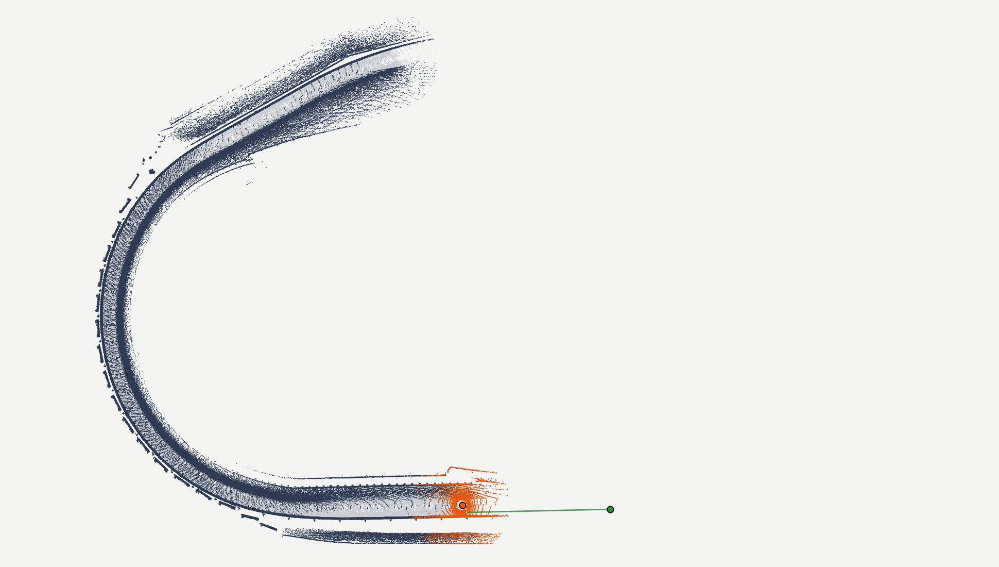

In [33]:
W, H, DPI, FPS = RENDER["W"], RENDER["H"], RENDER["DPI"], RENDER["FPS"]
fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor=BG)
ax = fig.add_axes([0, 0, 1, 1]); ax.set_facecolor(BG)
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("equal"); ax.axis("off")

road  = ax.scatter([], [], s=0.6, c=ROAD_C, alpha=0.6, linewidths=0)
wall  = ax.scatter([], [], s=0.8, c=WALL_C, alpha=0.8, linewidths=0)
fresh = ax.scatter([], [], s=1.4, c="#E8590C", alpha=0.9, linewidths=0)
kline, = ax.plot([], [], c="#2B8A3E", lw=2, alpha=0.8)
kdot,  = ax.plot([], [], "o", c="#2B8A3E", ms=9, mec="black", mew=1.2)
mdot,  = ax.plot([], [], "o", c="#E8590C", ms=9, mec="black", mew=1.2)
label  = ax.text(0.02, 0.96, "", transform=ax.transAxes, va="top", fontsize=11, color="#222")

n_frames = int((t1 - t0) / RENDER["SPEED"] * FPS) + 1
def draw(i):
    tf = t0 + i * RENDER["SPEED"] / FPS
    n = np.searchsorted(PT, tf, side="right")
    Pn, Sn = P[:n], S[:n]
    road.set_offsets(Pn[~Sn]); wall.set_offsets(Pn[Sn])
    fresh.set_offsets(P[PT == PT[n - 1]] if n else np.empty((0, 2)))
    tt = np.linspace(tf - RENDER["TRAIL_S"], tf, 60) + KAIST_DT
    trail = to_map(np.array([pos(u, tk, xk, yk) for u in tt]))
    kline.set_data(trail[:, 0], trail[:, 1]); kdot.set_data([trail[-1, 0]], [trail[-1, 1]])
    pm = to_map(pos(tf, tm, xm, ym))[0]; mdot.set_data([pm[0]], [pm[1]])

for k, frac in enumerate([0.02, 0.5, 1.0]):
    draw(int(frac * (n_frames - 1))); fig.savefig(VID / f"p1_still_{k}.png", facecolor=BG)
draw(int(0.5 * (n_frames - 1))); plt.show()
label  = ax.text(0.02, 0.04, "", transform=ax.transAxes, va="bottom", fontsize=11, color="#222",
                 bbox=dict(fc=BG, ec="none", alpha=0.85, pad=3))

**The video writer.** The function `write_frames()` draws each frame with the given drawing function, extracts the raw RGBA pixels from the figure and sends them through a pipe to `ffmpeg` (the binary supplied by `imageio-ffmpeg`), which encodes them as H.264. A check ensures that the buffer has exactly the expected size. The same function is used for all pieces. The last line renders Piece 1: 486 frames, 16.2 s.

In [34]:
def write_frames(path, draw_fn, n, fig_):
    """Render n frames with draw_fn(i), pipe raw pixels into ffmpeg, write an .mp4."""
    exe = imageio_ffmpeg.get_ffmpeg_exe()
    cmd = [exe, "-y", "-f", "rawvideo", "-pix_fmt", "rgba", "-s", f"{W}x{H}", "-r", str(FPS), "-i", "-",
           "-an", "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-crf", "20", str(path)]
    p = subprocess.Popen(cmd, stdin=subprocess.PIPE, stderr=subprocess.DEVNULL)
    for i in range(n):
        draw_fn(i)
        buf = io.BytesIO()
        fig_.savefig(buf, format="rgba", dpi=DPI, facecolor=BG)
        raw = buf.getvalue()
        assert len(raw) == W * H * 4, (len(raw), W * H * 4)
        p.stdin.write(raw)
    p.stdin.close(); p.wait()
    print(path, "| frames:", n, "| length:", round(n / FPS, 1), "s")

write_frames(VID / "p1_map_sweep.mp4", draw, n_frames, fig)

videos\p1_map_sweep.mp4 | frames: 486 | length: 16.2 s


### 6.2 Piece 2: the transition from the map to the cockpit view

**Settings.** The cockpit view has a frame height of 50 m (`R_COCK = 25` m radius), and the car is placed 35 % above the lower edge (`EGO_Y`), so that more road is visible ahead than behind. The transition lasts `T_TRANS = 3` s. With `HIST = 1` only the current LiDAR scan is shown in the cockpit.

**Heading and scans.** The heading of MIT-PITT-RW in the rotated map frame is computed from the pose quaternions (with the orientation fix) and unwrapped over time. For the time window of the cockpit view the scans are loaded at full density and converted to map coordinates, using the same procedure as for the map. In addition, every point receives a random rank so that the density can be raised gradually during the transition. Points classified as structure that lie within 2.5 m of the predicted position of KAIST are flagged as "KAIST points", so that the other car appears in a separate colour in the LiDAR view.

The printout reports 29 scans with 2,048,271 points (33 MB), at 2.0 scans per second.

In [35]:
R_COCK  = 25.0            # frame height = 2*R_COCK metres in the cockpit view
EGO_Y   = 0.35            # the car sits 35 % up from the bottom, so more road is visible ahead
T_TRANS = T_B - T_A       # transition length in seconds (3 s, real-time speed)
T_END   = T_PASS + 4.0    # last moment we load scans for
HIST    = 1               # number of most recent scans shown in the cockpit (1 = current scan only)

pw = poses.sort_values("t").reset_index(drop=True)

# --- heading of the MIT car in the rotated map frame, from the pose quaternions ---
alpha_t = pw["t"].to_numpy()
alpha_v = []
for _, p in pw.iterrows():
    f_g = (quat_to_rot(p["rotation"]) @ yaw_rot(YAW_FIX_DEG))[:2, 0]   # vehicle x-axis (forward) in global xy
    f_m = Rm @ f_g                                                    # ... in the rotated map frame
    alpha_v.append(np.arctan2(f_m[1], f_m[0]))
alpha_v = np.unwrap(alpha_v)
def heading(tt): return np.interp(tt, alpha_t, alpha_v)
def ego_map(tt): return to_map(pos(tt, tm, xm, ym))[0]

# --- full-density scans around the cockpit window, already in map coordinates ---
def load_scan(pose):
    smp = want.loc[want["filename"] == pose["filename"], "sample_token"].iloc[0]
    rows = want[(want["sample_token"] == smp) & want["channel"].str.startswith("LIDAR")]
    R_g = quat_to_rot(pose["rotation"]) @ yaw_rot(YAW_FIX_DEG)
    p_g = np.array(pose["translation"], float)
    veh = []
    for _, r in rows.iterrows():
        pts = np.fromfile(OUT / r["filename"], dtype=np.float32).reshape(-1, 5)[:, :3].astype(float)
        c = calib.loc[calib["token"] == r["calibrated_sensor_token"]].iloc[0]
        veh.append(pts @ quat_to_rot(c["rotation"]).T + np.array(c["translation"], float))
    veh = np.vstack(veh)
    rr = np.hypot(veh[:, 0], veh[:, 1]); veh = veh[(rr > 3) & (rr < 60)]
    near = veh[np.hypot(veh[:, 0], veh[:, 1]) < 20]
    st = veh[:, 2] > np.percentile(near[:, 2], 10) + 0.5              # structure = above local ground
    g = veh @ R_g.T + p_g
    return to_map(g[:, :2]), st

rng2 = np.random.default_rng(1)
scans = []
for _, pose in pw[(pw["t"] >= T_A - 1.5) & (pw["t"] <= T_END)].iterrows():
    xy, st = load_scan(pose)
    pk = to_map(pos(pose["t"] + KAIST_DT, tk, xk, yk))[0]             # where KAIST was at this scan's time
    kf = st & (np.hypot(xy[:, 0] - pk[0], xy[:, 1] - pk[1]) < 2.5)    # structure points within 2.5 m = the other car
    scans.append(dict(t=pose["t"], xy=xy, st=st, kf=kf, r=rng2.random(len(xy))))
scan_t = np.array([s["t"] for s in scans])
print(f"{len(scans)} scans loaded | {sum(len(s['xy']) for s in scans):,} points | "
      f"{sum(s['xy'].nbytes for s in scans)/1e6:.0f} MB | scans/s: {len(scans)/(T_END-(T_A-1.5)):.1f}")

29 scans loaded | 2,048,271 points | 33 MB | scans/s: 2.0


**The camera move.** The function `view(tf, e)` describes the virtual camera as a function of time `tf` and transition progress `e` (0 = map view, 1 = cockpit view). Four things change together: the zoom is interpolated geometrically, the centre pans from the middle of the map to the car (finishing slightly before the zoom ends), the view rotates by the angle that places the nose of the car at the top, and the position of the car on the screen moves from the centre to 35 % of the height. The function `smooth(u)`, equal to 3u² - 2u³, makes all movements start and end gently.

**The drawing function.** `draw_view(tf, e)` draws three layers: the earlier map points, which fade out while the camera zooms in; the newest scans, which change from orange (as in Piece 1) to the colours road, structure and other car; and the position markers, the trail of KAIST and two dashed range rings at 10 m and 20 m that fade in. The other car's points are drawn larger. The cell ends with six stills: the start, middle and end of the transition, and the cockpit view at 3 s before, at, and 2 s after the pass.

In [36]:
import matplotlib.colors as mcolors
from matplotlib.patches import Circle

# ---------- the camera: map view (e=0) -> cockpit view (e=1) ----------
k0 = W / (x1 - x0)                                   # map zoom, pixels per metre
c0 = np.array([(x0 + x1) / 2, (y0 + y1) / 2])        # map centre
k1 = H / (2 * R_COCK)                                # cockpit zoom
n_wrap = round((np.pi / 2 - heading(T_B)) / (2 * np.pi))
def phi1(tt): return np.pi / 2 - heading(tt) - 2 * np.pi * n_wrap   # rotation that puts the car's nose at the top
def smooth(u): u = np.clip(u, 0, 1); return u * u * (3 - 2 * u)

def view(tf, e):
    e_pan = smooth(e * 1.25)                         # the pan finishes a bit before the zoom
    c = (1 - e_pan) * c0 + e_pan * ego_map(tf)
    k = np.exp((1 - e) * np.log(k0) + e * np.log(k1))
    phi = e * phi1(tf)
    anchor = np.array([W / 2, (1 - e) * H / 2 + e * EGO_Y * H])
    return c, k, phi, anchor
def to_screen(M, v):
    c, k, phi, a = v
    R = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
    return a + k * (M - c) @ R.T

rgb = lambda h: np.array(mcolors.to_rgb(h))
C_ROAD, C_WALL, C_K, C_NEW = rgb("#AEB4C0"), rgb(WALL_C), rgb("#2B8A3E"), rgb("#E8590C")

fig2 = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor=BG)
ax2 = fig2.add_axes([0, 0, 1, 1]); ax2.set_facecolor(BG)
ax2.set_xlim(0, W); ax2.set_ylim(0, H); ax2.set_aspect("equal"); ax2.axis("off")
rings = [Circle((0, 0), 1, fill=False, ec="#8A8F99", lw=1, ls="--", alpha=0) for _ in (10, 20)]
for r_ in rings: ax2.add_patch(r_)
w_road = ax2.scatter([], [], s=0.6, c=ROAD_C, alpha=0.6, linewidths=0)
w_wall = ax2.scatter([], [], s=0.8, c=WALL_C, alpha=0.8, linewidths=0)
w_scan = ax2.scatter([], [], s=1.4, linewidths=0)
v_line, = ax2.plot([], [], c="#2B8A3E", lw=2, alpha=0.8)
v_kdot, = ax2.plot([], [], "o", c="#2B8A3E", ms=9, mec="black", mew=1.2)
v_mdot, = ax2.plot([], [], "o", c="#E8590C", ms=9, mec="black", mew=1.2)
v_text = ax2.text(0.02, 0.04, "", transform=ax2.transAxes, va="bottom", fontsize=11, color="#222",
                bbox=dict(fc=BG, ec="none", alpha=0.85, pad=3))
EMPTY = np.empty((0, 2))

def draw_view(tf, e):
    v = view(tf, e); k = v[1]
    # 1) the frozen LiDAR wake from Piece 1: fades out while we zoom in
    wa = 1 - smooth((e - 0.15) / 0.6)
    if wa > 0.01:
        n = np.searchsorted(PT, tf, side="right")
        Sc = to_screen(P[:n], v)
        ok = (Sc[:, 0] > -5) & (Sc[:, 0] < W + 5) & (Sc[:, 1] > -5) & (Sc[:, 1] < H + 5)
        Sc, st = Sc[ok], S[:n][ok]
        w_road.set_offsets(Sc[~st]); w_wall.set_offsets(Sc[st])
        grow = max(1.0, (k / k0) ** 0.7)
        w_road.set_sizes([0.6 * grow]); w_wall.set_sizes([0.8 * grow])
        w_road.set_alpha(0.6 * wa); w_wall.set_alpha(0.8 * wa)
    else:
        w_road.set_offsets(EMPTY); w_wall.set_offsets(EMPTY)
    # 2) the newest scan(s): orange at e=0 (as in Piece 1), road/wall/other-car colours at e=1
    j = np.searchsorted(scan_t, tf, side="right") - 1
    if j >= 0:
        use = scans[max(0, j - HIST + 1): j + 1]
        frac = 0.15 + 0.85 * smooth(e / 0.5)                         # thin at e=0 like Piece 1, full density later
        xy = np.vstack([s["xy"][s["r"] < frac] for s in use])
        stf = np.concatenate([s["st"][s["r"] < frac] for s in use])
        kf = np.concatenate([s["kf"][s["r"] < frac] for s in use])
        Sc = to_screen(xy, v)
        ok = (Sc[:, 0] > -5) & (Sc[:, 0] < W + 5) & (Sc[:, 1] > -5) & (Sc[:, 1] < H + 5)
        Sc, stf, kf = Sc[ok], stf[ok], kf[ok]
        col = np.where(kf[:, None], C_K, np.where(stf[:, None], C_WALL, C_ROAD))
        col = (1 - e) * C_NEW + e * col
        w_scan.set_offsets(Sc); w_scan.set_facecolor(np.c_[col, np.full(len(col), 0.9)])
        w_scan.set_sizes(np.where(kf, 1.4 + 14.0 * e, 1.4 + 3.0 * e))   # the other car's points are drawn bigger
    else:
        w_scan.set_offsets(EMPTY)
    # 3) cars: position-only markers, KAIST with a short trail
    mp = to_screen(ego_map(tf)[None], v)[0]
    tt = np.linspace(tf - (8.0 * (1 - e) + 1.5 * e), tf, 40) + KAIST_DT
    trail = to_screen(to_map(np.array([pos(u, tk, xk, yk) for u in tt])), v)
    v_line.set_data(trail[:, 0], trail[:, 1]); v_kdot.set_data([trail[-1, 0]], [trail[-1, 1]])
    v_mdot.set_data([mp[0]], [mp[1]])
    for r_, rad in zip(rings, (10, 20)):
        r_.set_center(mp); r_.set_radius(rad * k); r_.set_alpha(0.6 * e ** 3)
    v_text.set_text(f"{MIT} LiDAR sweep   |   t = {tf - t0:5.1f} s" if e < 0.5 else
                    f"{MIT} LiDAR, vehicle frame   |   t = {tf - T_PASS:+5.1f} s from the pass")

# ---- stills: start / middle / end of the transition, then the cockpit at -3, 0, +2 s from the pass ----
checks = [(T_A, 0.0), (T_A + 0.5 * T_TRANS, smooth(0.5)), (T_B, 1.0),
          (T_PASS - 3.0, 1.0), (T_PASS, 1.0), (T_PASS + 2.0, 1.0)]
mont = plt.figure(figsize=(18, 6.4))
for q, (tf, e) in enumerate(checks):
    draw_view(tf, e); fig2.savefig(VID / f"p2_still_{q}.png", facecolor=BG)
    a_ = mont.add_subplot(2, 3, q + 1); a_.imshow(plt.imread(VID / f"p2_still_{q}.png")); a_.axis("off")
mont.tight_layout(); plt.show()

Piece 2 is rendered with the progress `e = smooth(u)` over 3 s, which gives 91 frames.

In [37]:
n2 = int(T_TRANS * FPS) + 1
def draw_p2(i):
    u = i / (n2 - 1)
    draw_view(T_A + u * T_TRANS, smooth(u))
write_frames(VID / "p2_transition.mp4", draw_p2, n2, fig2)

videos\p2_transition.mp4 | frames: 91 | length: 3.0 s


### 6.3 Which camera, and when to cut? (Figure 14)

The question is in which camera KAIST is visible, and at which moment the video should switch from the LiDAR view to the real footage. The calibration and image size of all five camera channels are collected first. The ground level in the vehicle frame is found to be -0.24 m (10th percentile of z within 20 m). For every LiDAR keyframe from 8 s before to 8 s after the pass, the position of KAIST in the vehicle frame is projected into each camera. The apparent width of the car in pixels is estimated by assuming a car width of 2 m (`CAR_W`), as `CAR_W * fx / depth`.

The printed table and Figure 14 show that `CAMERA_FRONT_LEFT_CENTER` sees KAIST from -7.8 to -3.5 s, `CAMERA_FRONT_RIGHT` from -4.5 to -0.4 s (the apparent width grows from 83 to 380 px), and `CAMERA_REAR_RIGHT` from -0.4 s onward. `CAMERA_FRONT_LEFT` and `CAMERA_REAR_LEFT` never see it. The distance is 65 m at -7.8 s and reaches its minimum of 7.4 m around the pass. The front-right camera is used, because it covers the last seconds of the approach and the moment of passing. The camera `CAMERA_FRONT_LEFT_CENTER` has a larger focal length (a telephoto-like view), which makes KAIST appear about 2.3 times wider there than in the other cameras at the same distance.

ground z in the vehicle frame: -0.24 m
KAIST relative to MIT (fwd/left in m) and apparent width in px per camera (blank = outside the image):
   t   fwd  left  dist  FRONT_LEFT  FRONT_LEFT_CENTER  FRONT_RIGHT  REAR_LEFT  REAR_RIGHT
-7.8  65.3  -3.3  65.4                          107.6                                    
-7.4  62.0  -3.9  62.2                          113.5                                    
-6.8  57.1  -4.2  57.2                          123.8                                    
-6.5  53.7  -4.3  53.9                          132.0                                    
-5.9  48.6  -4.9  48.8                          146.5                                    
-5.5  45.2  -5.0  45.5                          158.1                                    
-4.9  40.0  -5.5  40.4                          179.9                                    
-4.5  36.5  -5.7  36.9                          198.2         82.6                       
-3.9  31.3  -6.1  31.9                          

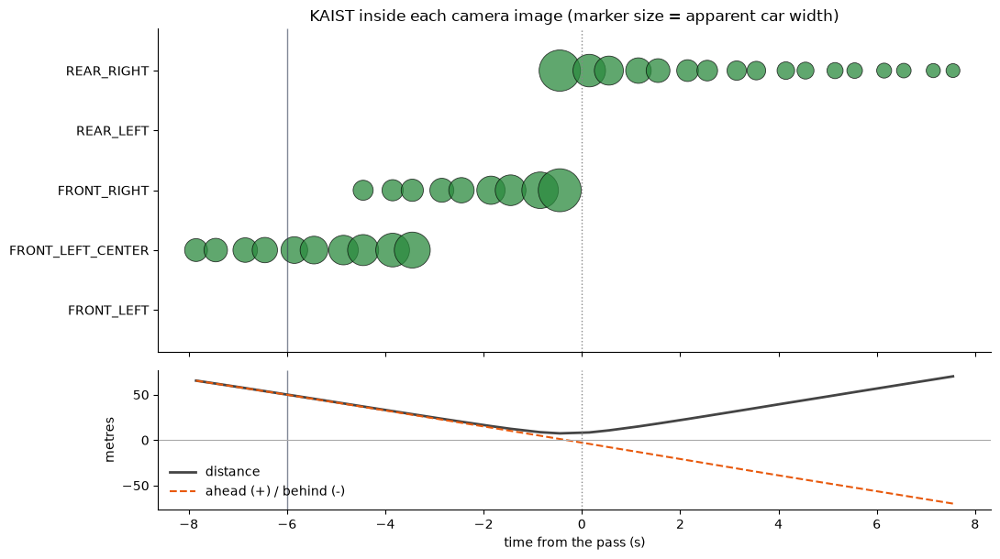

In [38]:
import pandas as pd
from matplotlib.image import imread

CAR_W = 2.0                     # assumed car width in metres, only used to estimate the size on screen

# --- the five cameras: calibration + image size ---
CAMS = sorted(c for c in want["channel"].unique() if c.startswith("CAMERA"))
cam_info = {}
for cn in CAMS:
    r0 = want[want["channel"] == cn].iloc[0]
    cc = calib.loc[calib["token"] == r0["calibrated_sensor_token"]].iloc[0]
    h_img, w_img = imread(OUT / r0["filename"]).shape[:2]
    cam_info[cn] = dict(R=quat_to_rot(cc["rotation"]), t=np.array(cc["translation"], float),
                        K=np.array(cc["camera_intrinsic"], float), W=w_img, H=h_img)

# --- ground height in the vehicle frame (10th percentile of LiDAR z near the car, as in Figure 13) ---
pg = pw.iloc[(pw["t"] - (T_PASS - 3)).abs().argmin()]
smp = want.loc[want["filename"] == pg["filename"], "sample_token"].iloc[0]
zs = []
for _, r in want[(want["sample_token"] == smp) & want["channel"].str.startswith("LIDAR")].iterrows():
    pts = np.fromfile(OUT / r["filename"], dtype=np.float32).reshape(-1, 5)[:, :3].astype(float)
    c = calib.loc[calib["token"] == r["calibrated_sensor_token"]].iloc[0]
    pts = pts @ quat_to_rot(c["rotation"]).T + np.array(c["translation"], float)
    zs.append(pts[np.hypot(pts[:, 0], pts[:, 1]) < 20, 2])
GZ = np.percentile(np.concatenate(zs), 10)
print(f"ground z in the vehicle frame: {GZ:.2f} m")

# --- KAIST in the MIT vehicle frame and in each camera, at every LiDAR keyframe from -8 s to +8 s ---
rows = []
for _, pose in pw[(pw["t"] >= T_PASS - 8) & (pw["t"] <= T_PASS + 8)].iterrows():
    R_g = quat_to_rot(pose["rotation"]) @ yaw_rot(YAW_FIX_DEG)
    p_e = np.array(pose["translation"], float)
    pk = np.r_[pos(pose["t"] + KAIST_DT_CAM, tk, xk, yk), p_e[2]]
    v = R_g.T @ (pk - p_e)                      # vehicle frame: x forward, y left
    v[2] = GZ + 0.6                             # roughly the middle of the car
    row = dict(t=pose["t"] - T_PASS, fwd=v[0], left=v[1], dist=np.hypot(v[0], v[1]))
    for cn, ci in cam_info.items():
        pc = (v - ci["t"]) @ ci["R"]
        px = np.nan
        if pc[2] > 0.5:
            uvw = ci["K"] @ pc
            u, vv = uvw[0] / uvw[2], uvw[1] / uvw[2]
            if 0 <= u < ci["W"] and 0 <= vv < ci["H"]:
                px = CAR_W * ci["K"][0, 0] / pc[2]      # apparent car width in pixels
        row[cn] = px
    rows.append(row)
diag = pd.DataFrame(rows)
show = diag.rename(columns={c: c.replace("CAMERA_", "") for c in CAMS})
print("KAIST relative to MIT (fwd/left in m) and apparent width in px per camera (blank = outside the image):")
print(show.round(1).to_string(index=False, na_rep=""))

# --- figure 14: when is KAIST visible, and in which camera? ---
fig3, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.3]))
for i, cn in enumerate(CAMS):
    m = diag[cn].notna()
    a1.scatter(diag.loc[m, "t"], np.full(m.sum(), i), s=diag.loc[m, cn] * 3, c="#2B8A3E", alpha=0.75, edgecolors="black", linewidths=0.6)
a1.set_yticks(range(len(CAMS))); a1.set_yticklabels([c.replace("CAMERA_", "") for c in CAMS])
a1.set_ylim(-0.7, len(CAMS) - 0.3); a1.set_title("KAIST inside each camera image (marker size = apparent car width)")
a2.plot(diag["t"], diag["dist"], c="#444", lw=2, label="distance")
a2.plot(diag["t"], diag["fwd"], c="#E8590C", lw=1.5, ls="--", label="ahead (+) / behind (-)")
a2.axhline(0, c="#aaa", lw=0.8); a2.set_xlabel("time from the pass (s)"); a2.set_ylabel("metres"); a2.legend(frameon=False)
for a_ in (a1, a2):
    a_.axvline(0, c="#888", lw=1, ls=":"); a_.axvspan(T_B - T_PASS, T_B - T_PASS + 0.01, color="#2F3B52", alpha=0.6)
    for sp in ("top", "right"): a_.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig("figures/14_kaist_in_cameras.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.4 Earlier render of Piece 3 (superseded)

This cell renders the cockpit view with a provisional cut time (`T_C = T_PASS - 2.0`, 4.0 s long), set before the decision based on Figure 14. The next cell sets the cut time to -3.5 s and Section 6.9 renders Piece 3 again with 2.5 s, overwriting the file `p3_cockpit.mp4`. Only that second version enters the final video.

In [39]:
T_C = T_PASS - 2.0              # <- cut time from the cockpit view to the real camera (decide after Figure 14)
n3 = int((T_C - T_B) * FPS) + 1
def draw_p3(i): draw_view(T_B + i / FPS, 1.0)
write_frames(VID / "p3_cockpit.mp4", draw_p3, n3, fig2)

videos\p3_cockpit.mp4 | frames: 121 | length: 4.0 s


### 6.5 The virtual camera and the timeline of Pieces 3 to 5

**Timeline.** The cockpit view ends at `T_C` (-3.5 s). The virtual-camera transition lasts `T_VC = 2` s until `T_D` (-1.5 s), at which the real photograph is fully visible. The video ends at `T_E` (+2.6 s), about three seconds after KAIST has left the image. The photographs of `CAMERA_FRONT_RIGHT` are collected, and the function `photo_at()` returns the one closest in time. There are 19 photographs between `T_D` and `T_E`, which is 4.6 photographs per second for a video of 30 frames per second.

**Output frame.** The photograph (2064 × 960 pixels) is wider than the 16:9 video frame. It is scaled by 0.930 to fill the width and is shown with bars of 93 px at the top and bottom. The intrinsics are scaled accordingly (`fx` becomes 929 px). The pose of the car at any time is obtained by interpolating the quaternion (normalised linear interpolation) and the translation, followed by the orientation fix.

**The virtual camera.** The idea is to let a camera fly from the top-down view to the position and orientation of the real camera. The start is a camera looking straight down, with its image up direction along the forward direction of the car (`R0`), at the height `H_v` at which the scale on the ground equals the scale of the cockpit view, so that the first virtual frame matches the last cockpit frame. The end is the pose of the real front-right camera in the vehicle frame. The orientation is interpolated with spherical linear interpolation (slerp), which turns the camera along the shortest path between the two orientations, and the position is interpolated linearly.

**3-D scans.** The scans of the transition window are loaded in three dimensions (not collapsed to the map plane), because the virtual camera sees them in perspective. The printout reports 8 scans with 561,491 points.

In [40]:
# ======== Pieces 3-5: timeline, data and virtual camera ========
from PIL import Image
from scipy.spatial.transform import Rotation as Rot, Slerp

T_C   = T_PASS - 3.5            # cockpit view ends, virtual-camera transition starts
T_VC  = 2.0                     # length of the virtual-camera transition (s)
T_D   = T_C + T_VC              # real photo fully on screen
T_E   = T_PASS + 2.6            # end of the video (about 3 s after KAIST leaves the FRONT_RIGHT image)
CAM   = "CAMERA_FRONT_RIGHT"
print(f"cockpit {T_B-T_PASS:+.1f}..{T_C-T_PASS:+.1f} s | virtual camera {T_C-T_PASS:+.1f}..{T_D-T_PASS:+.1f} s | "
      f"real photos {T_D-T_PASS:+.1f}..{T_E-T_PASS:+.1f} s")

# --- the photos of this camera (keyframes + sweeps) ---
ph = want[want["channel"] == CAM].sort_values("t").reset_index(drop=True)
ph_t = ph["t"].to_numpy()
n_in = ((ph_t >= T_D) & (ph_t <= T_E)).sum()
print(f"{CAM}: {n_in} photos between T_D and T_E = {n_in/(T_E-T_D):.1f} photos/s (the video runs at {FPS} fps)")
_img_cache = {}
def photo_at(tt):
    i = int(np.abs(ph_t - tt).argmin())
    fn = ph.loc[i, "filename"]
    if fn not in _img_cache:
        _img_cache[fn] = np.asarray(Image.open(OUT / fn).convert("RGB"))
    return _img_cache[fn]

# --- camera intrinsics, scaled to the output frame (letterboxed if the aspect ratio differs) ---
ci = cam_info[CAM]
Wi, Hi = ci["W"], ci["H"]
sc = min(W / Wi, H / Hi); offx, offy = (W - Wi * sc) / 2, (H - Hi * sc) / 2
fx, fy = ci["K"][0, 0] * sc, ci["K"][1, 1] * sc
cx_r, cy_r = ci["K"][0, 2] * sc + offx, ci["K"][1, 2] * sc + offy
print(f"photo {Wi}x{Hi} -> scale {sc:.3f}, offset ({offx:.0f},{offy:.0f}), fx={fx:.0f}px")

# --- ego pose at any time (quaternion nlerp + yaw fix, translation lerp) ---
pq = np.array(list(pw["rotation"]), float); pt_ = np.array(list(pw["translation"]), float)
def ego_pose(tt):
    i = int(np.clip(np.searchsorted(alpha_t, tt) - 1, 0, len(alpha_t) - 2))
    a = float(np.clip((tt - alpha_t[i]) / (alpha_t[i + 1] - alpha_t[i]), 0, 1))
    q0, q1 = pq[i], pq[i + 1]
    if q0 @ q1 < 0: q1 = -q1
    q = (1 - a) * q0 + a * q1; q /= np.linalg.norm(q)
    return quat_to_rot(q) @ yaw_rot(YAW_FIX_DEG), (1 - a) * pt_[i] + a * pt_[i + 1]

# --- the virtual camera: from a top-down view (matches the cockpit view) to the real camera pose ---
# start orientation: looking straight down, image-up = vehicle forward, image-right = vehicle right
R0 = np.array([[0, -1, 0], [-1, 0, 0], [0, 0, -1]], float)
R_end, t_end = ci["R"], ci["t"]                               # the real FRONT_RIGHT camera in the vehicle frame
slerp = Slerp([0, 1], Rot.from_matrix([R0, R_end]))           # same as R_cam @ Rx(theta), theta -90 -> 0, plus a yaw
H_v = fx / k1                                                 # height at which the ground scale equals the cockpit scale
d_fwd = (0.5 - EGO_Y) * H / k1                                # ego sits EGO_Y up from the bottom, so the camera hovers this far ahead
P0 = np.array([d_fwd, 0.0, GZ + H_v])                         # start position in the vehicle frame
def virt_pose(s, R_g, p_g):
    Rl = slerp([s]).as_matrix()[0]
    pl = (1 - s) * P0 + s * t_end
    return R_g @ Rl, p_g + R_g @ pl                           # world rotation (columns = camera axes), world position

# --- full 3-D scans (global frame) for the window around the transition ---
def load_scan3d(pose):
    smp = want.loc[want["filename"] == pose["filename"], "sample_token"].iloc[0]
    rows = want[(want["sample_token"] == smp) & want["channel"].str.startswith("LIDAR")]
    R_g = quat_to_rot(pose["rotation"]) @ yaw_rot(YAW_FIX_DEG)
    p_g = np.array(pose["translation"], float)
    veh = []
    for _, r in rows.iterrows():
        pts = np.fromfile(OUT / r["filename"], dtype=np.float32).reshape(-1, 5)[:, :3].astype(float)
        c = calib.loc[calib["token"] == r["calibrated_sensor_token"]].iloc[0]
        veh.append(pts @ quat_to_rot(c["rotation"]).T + np.array(c["translation"], float))
    veh = np.vstack(veh)
    rr = np.hypot(veh[:, 0], veh[:, 1]); veh = veh[(rr > 3) & (rr < 60)]
    near = veh[np.hypot(veh[:, 0], veh[:, 1]) < 20]
    st = veh[:, 2] > np.percentile(near[:, 2], 10) + 0.5
    return veh @ R_g.T + p_g, st

scans3 = []
for _, pose in pw[(pw["t"] >= T_C - 1.5) & (pw["t"] <= T_D + 0.3)].iterrows():
    g, st = load_scan3d(pose)
    pk = pos(pose["t"] + KAIST_DT, tk, xk, yk)
    kf = st & (np.hypot(g[:, 0] - pk[0], g[:, 1] - pk[1]) < 2.5)
    scans3.append(dict(t=pose["t"], g=g, st=st, kf=kf))
scan3_t = np.array([s["t"] for s in scans3])
print(f"{len(scans3)} 3-D scans | {sum(len(s['g']) for s in scans3):,} points")

cockpit -6.0..-3.5 s | virtual camera -3.5..-1.5 s | real photos -1.5..+2.6 s
CAMERA_FRONT_RIGHT: 19 photos between T_D and T_E = 4.6 photos/s (the video runs at 30 fps)
photo 2064x960 -> scale 0.930, offset (0,93), fx=929px
8 3-D scans | 561,491 points


### 6.6 Smoothing the photograph stream

With 4.6 photographs per second, showing the nearest photograph in each frame would make the footage jerky, and the gaps between photographs are irregular (from 0.03 to 0.72 s). Intermediate frames are therefore synthesised between two real photographs by motion-compensated interpolation. The dense optical flow between two consecutive photographs is computed in both directions with the DIS algorithm of OpenCV, which copes with the large displacements at this speed (the Farneback method failed above about 40 px). Both photographs are then warped part of the way along the flow and blended.

Flow errors would create ghost images, for example a double car, so each pixel is checked with a forward-backward consistency test. A pixel that is moved along the forward flow and then back along the backward flow should return to its starting point, and the distance by which it misses is the error. Pixels with an error larger than `FB_THR = 1.5` px are not trusted and are taken from the nearest real photograph instead.

The printed table gives for each pair of photographs the time gap and the share of pixels with a round-trip error below 2 px (between 0.19 and 0.47). These shares are modest because the other car, thin fence wires and the rapidly changing scene at this speed cannot be tracked reliably. The mask makes sure that these regions are not distorted. The function `photo_at()` is redefined here and from now on returns the interpolated image.

In [41]:
# ======== Cell 34b: smooth photo stream (motion-compensated interpolation between the real camera frames) ========
import cv2

VW, VH = int(round(Wi * sc)), int(round(Hi * sc))             # size of the photo inside the output frame
_small, _flow = {}, {}
_dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)   # handles large motion (Farneback fails above ~40 px)
gx, gy = np.meshgrid(np.arange(VW, dtype=np.float32), np.arange(VH, dtype=np.float32))
FB_THR = 1.5                                                   # px: a pixel whose motion fails the round-trip check by more than this is not trusted

def _frame(i):                                                 # photo i, resized to the display size
    if i not in _small:
        a = np.asarray(Image.open(OUT / ph.loc[i, "filename"]).convert("RGB"))
        _small[i] = cv2.resize(a, (VW, VH), interpolation=cv2.INTER_AREA)
    return _small[i]

def _fb_err(Fa, Fb):
    """Walk forward along Fa, then back along Fb: a trustworthy motion comes back to the start. Returns the miss distance in px."""
    back = cv2.remap(Fb, (gx + Fa[..., 0]).astype(np.float32), (gy + Fa[..., 1]).astype(np.float32),
                     cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return np.hypot(*(Fa + back).transpose(2, 0, 1))

def _flows(i):
    """Motion A->B and B->A between photo i and i+1 (computed once) and, per pixel, how much we trust it (1 = sure, 0 = no)."""
    if i not in _flow:
        gA, gB = (cv2.cvtColor(_frame(k), cv2.COLOR_RGB2GRAY) for k in (i, i + 1))
        F_AB, F_BA = _dis.calc(gA, gB, None), _dis.calc(gB, gA, None)
        eA, eB = _fb_err(F_AB, F_BA), _fb_err(F_BA, F_AB)
        mA = np.exp(-(eA / FB_THR) ** 2).astype(np.float32); mB = np.exp(-(eB / FB_THR) ** 2).astype(np.float32)
        _flow[i] = (F_AB, F_BA, float((eA < 2.0).mean()), mA, mB)
    return _flow[i]

def _warp(img, flow, k):                                       # I(y) = img(y - k * flow(y))
    k = np.float32(k)                                          # OpenCV wants float32 maps (NumPy 2 would promote to float64)
    return cv2.remap(img, (gx - k * flow[..., 0]).astype(np.float32), (gy - k * flow[..., 1]).astype(np.float32),
                     cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

def photo_at(tt):                                              # replaces the old photo_at from Cell 34
    i = int(np.searchsorted(ph_t, tt, side="right") - 1)
    if i < 0: return _frame(0)
    if i >= len(ph_t) - 1: return _frame(len(ph_t) - 1)
    a = (tt - ph_t[i]) / (ph_t[i + 1] - ph_t[i])               # how far we are from photo i to photo i+1 (0..1)
    if a < 0.02: return _frame(i)
    A, B = _frame(i), _frame(i + 1)
    F_AB, F_BA, _, mA, mB = _flows(i)
    wa, wb = _warp(A, F_AB, a), _warp(B, F_BA, 1 - a)          # photo i moved forward by a, photo i+1 moved back by (1-a)
    wA = (1 - a) * _warp(mA, F_AB, a)                          # weight of each moved photo = time weight x per-pixel trust
    wB = a * _warp(mB, F_BA, 1 - a)
    nearest = (A if a < 0.5 else B).astype(np.float32)         # where neither motion is trusted (the other car, thin wires): keep the nearest REAL photo
    eps = 0.05
    out = (wA[..., None] * wa + wB[..., None] * wb + eps * nearest) / (wA + wB + eps)[..., None]
    return out.astype(np.uint8)

# --- report: gap between photos and the share of pixels whose motion passes the round-trip check, for every pair in the clip ---
lo = max(0, int(np.searchsorted(ph_t, T_D, side="right")) - 1); hi = min(len(ph_t) - 1, int(np.searchsorted(ph_t, T_E)) + 1)
print("pair | gap (s) | share of trusted pixels")
for i in range(lo, hi):
    print(f"{i - lo:4d} | {ph_t[i+1]-ph_t[i]:6.2f}  | {_flows(i)[2]:.2f}")

pair | gap (s) | share of trusted pixels
   0 |   0.55  | 0.27
   1 |   0.72  | 0.22
   2 |   0.04  | 0.44
   3 |   0.13  | 0.46
   4 |   0.21  | 0.34
   5 |   0.21  | 0.33
   6 |   0.03  | 0.47
   7 |   0.10  | 0.33
   8 |   0.04  | 0.42
   9 |   0.21  | 0.31
  10 |   0.07  | 0.24
  11 |   0.22  | 0.19
  12 |   0.04  | 0.47
  13 |   0.63  | 0.21
  14 |   0.46  | 0.23
  15 |   0.21  | 0.35
  16 |   0.13  | 0.36
  17 |   0.17  | 0.28
  18 |   0.04  | 0.42
  19 |   0.08  | 0.39
  20 |   0.13  | 0.43


### 6.7 Visual check of the interpolation (Figure 15)

The interpolation is inspected on the three pairs of photographs with the lowest share of trusted pixels, which are the hardest cases. Each row shows the first photograph, the interpolated image halfway between them, and the second photograph. The points to check are that no double image of the car appears, that fence wires stay intact, and that the background does not wobble.

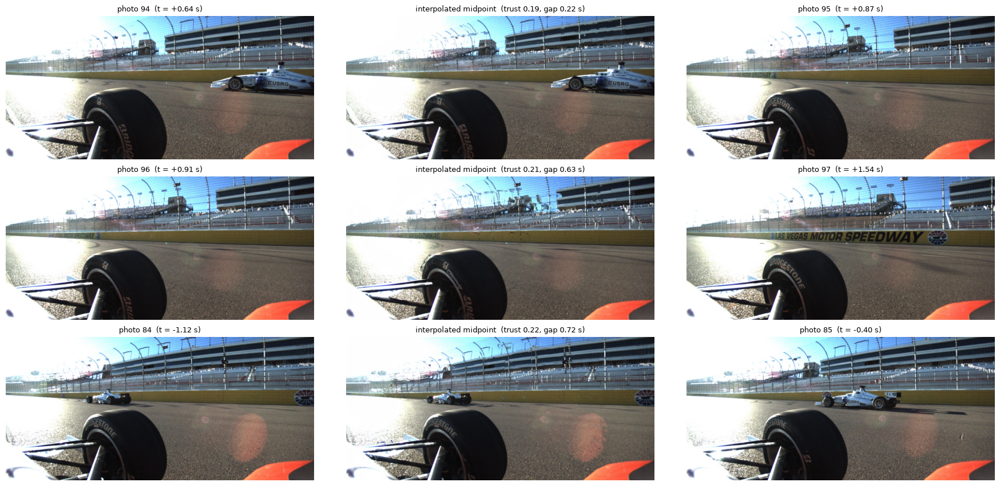

In [42]:
# ======== Cell 34c: eyeball check of the interpolation on the 3 hardest pairs ========
pairs = sorted(range(lo, hi), key=lambda i: _flows(i)[2])[:3]       # the pairs with the lowest trust
fig_, axs_ = plt.subplots(3, 3, figsize=(18, 8.6))
for r, i in enumerate(pairs):
    tmid = 0.5 * (ph_t[i] + ph_t[i + 1])
    shots = [(_frame(i), f"photo {i}  (t = {ph_t[i] - T_PASS:+.2f} s)"),
             (photo_at(tmid), f"interpolated midpoint  (trust {_flows(i)[2]:.2f}, gap {ph_t[i+1]-ph_t[i]:.2f} s)"),
             (_frame(i + 1), f"photo {i+1}  (t = {ph_t[i+1] - T_PASS:+.2f} s)")]
    for c, (im, ttl) in enumerate(shots):
        axs_[r, c].imshow(im); axs_[r, c].set_title(ttl, fontsize=9); axs_[r, c].axis("off")
plt.tight_layout(); plt.savefig("figures/15_interpolation_check.png", dpi=120, bbox_inches="tight"); plt.show()

### 6.8 Piece 4: drawing the virtual camera, and the checks at the seam

The function `project3()` applies the pinhole model of Section 5.5 to the virtual camera. Its principal point moves from the middle of the frame to that of the real camera. The function `draw_virtual(tf)` projects the 3-D scans into the virtual camera and draws them with the same colours as in the cockpit view (road, structure, KAIST in green). The point size depends on the distance. Over the last third of the transition the real photograph is blended in with increasing opacity, while the range rings and the markers fade out. The function `draw_photo(tf)` draws the photograph only, for Piece 5.

Two checks are made. The numerical check compares the pixel position of the car at the start of the virtual camera with its position in the cockpit view: both are (960, 702), so the two views match. The six stills show, in order, the last cockpit frame, the first virtual frame, the virtual camera at 25 % and 60 %, the end of the transition, and the first frame of the real footage.

**The marker of KAIST.** The marker is drawn at the position of KAIST at time `tf` plus a clock offset that changes gradually with the opacity `ap` of the photograph: it is `KAIST_DT_LIDAR` while the LiDAR points dominate and `KAIST_DT_CAM` once the photograph is fully visible. The marker therefore sits on the green points at the start of the transition and on the car in the photograph at its end.

ego at s=0: pixel (960, 702) | cockpit view has it at (960, 702)


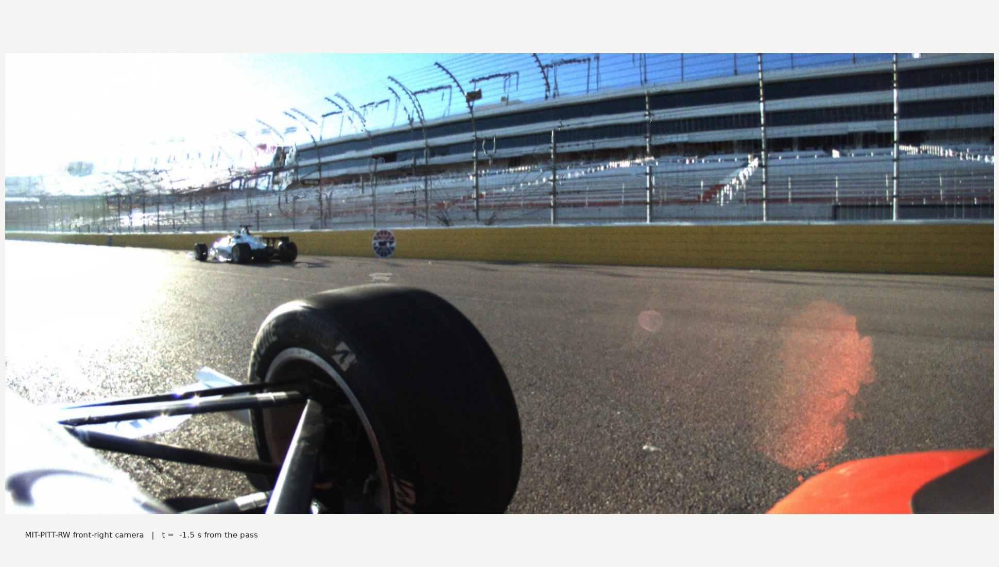

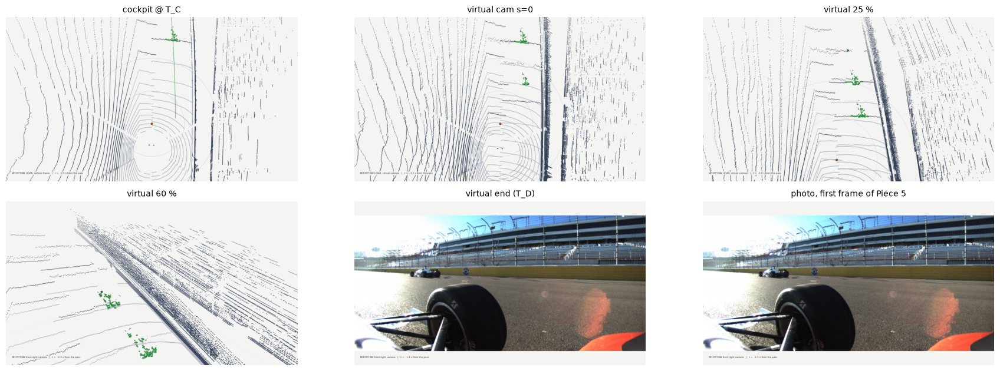

In [63]:
# ======== Piece 4 drawing + stills (seam checks) ========
fig4 = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor=BG)
ax4 = fig4.add_axes([0, 0, 1, 1]); ax4.set_facecolor(BG); ax4.axis("off")
v_pts = ax4.scatter([], [], linewidths=0, zorder=2)
v_img = ax4.imshow(np.zeros((2, 2, 3), np.uint8), extent=(offx, offx + Wi * sc, offy + Hi * sc, offy),
                   alpha=0, zorder=3, interpolation="bilinear")
ax4.set_xlim(0, W); ax4.set_ylim(H, 0); ax4.set_aspect("auto")
r_lines = [ax4.plot([], [], c="#8A8F99", lw=1, ls="--", zorder=4)[0] for _ in (10, 20)]
k4, = ax4.plot([], [], "o", c="#2B8A3E", ms=9, mec="black", mew=1.2, zorder=5)
m4, = ax4.plot([], [], "o", c="#E8590C", ms=9, mec="black", mew=1.2, zorder=5)
t4 = ax4.text(0.02, 0.04, "", transform=ax4.transAxes, va="bottom", fontsize=11, color="#222", zorder=6,
              bbox=dict(fc=BG, ec="none", alpha=0.85, pad=3))
ang = np.linspace(0, 2 * np.pi, 120)

def project3(X, Rw, pw_, s):
    pc = (np.atleast_2d(X) - pw_) @ Rw                        # world -> camera, same formula as Figure 13
    d = pc[:, 2]
    cx = (1 - s) * W / 2 + s * cx_r; cy = (1 - s) * H / 2 + s * cy_r
    with np.errstate(divide="ignore", invalid="ignore"):
        u = fx * pc[:, 0] / d + cx; v = fy * pc[:, 1] / d + cy
    return u, v, d

def draw_virtual(tf):
    s = float(smooth((tf - T_C) / T_VC))
    R_g, p_g = ego_pose(tf)
    Rw, pw_ = virt_pose(s, R_g, p_g)
    ap = float(smooth((s - 0.65) / 0.35))                     # photo opacity (crossfade over the last third)
    # LiDAR: the two newest scans
    j = np.searchsorted(scan3_t, tf, side="right") - 1
    use = scans3[max(0, j - 1): j + 1]
    X = np.vstack([q["g"] for q in use]); st = np.concatenate([q["st"] for q in use]); kf = np.concatenate([q["kf"] for q in use])
    u, v, d = project3(X, Rw, pw_, s)
    ok = (d > 0.5) & (u > -5) & (u < W + 5) & (v > -5) & (v < H + 5)
    u, v, d, st, kf = u[ok], v[ok], d[ok], st[ok], kf[ok]
    col = np.where(kf[:, None], C_K, np.where(st[:, None], C_WALL, C_ROAD))
    size = np.clip(4.4 * (H_v / d) ** 0.9, 1.0, 30.0) * np.where(kf, 4.0, 1.0)
    v_pts.set_offsets(np.c_[u, v]); v_pts.set_facecolor(np.c_[col, np.full(len(col), 0.9 * (1 - ap))]); v_pts.set_sizes(size)
    # photo
    if ap > 0.003:
        v_img.set_data(photo_at(tf)); v_img.set_alpha(ap)
    else:
        v_img.set_alpha(0)
    # rings, ego and KAIST markers (fade out as the photo comes in)
    fade = 1 - ap
    for ln, rad in zip(r_lines, (10, 20)):
        P_ = (R_g @ np.c_[rad * np.cos(ang), rad * np.sin(ang), np.full_like(ang, GZ)].T).T + p_g
        uu, vv, dd = project3(P_, Rw, pw_, s); m = dd > 0.5
        ln.set_data(np.where(m, uu, np.nan), np.where(m, vv, np.nan)); ln.set_alpha(0.6 * (1 - s) ** 2)
    eg = p_g + R_g @ np.array([0, 0, GZ]); ue, ve, de = project3(eg, Rw, pw_, s)
    m4.set_data([ue[0]] if de[0] > 0.5 else [], [ve[0]] if de[0] > 0.5 else []); m4.set_alpha(fade)
    kp = pos(tf + (1 - ap) * KAIST_DT_LIDAR + ap * KAIST_DT_CAM, tk, xk, yk); pk = np.r_[kp, p_g[2]] + R_g[:, 2] * (GZ + 0.6)
    uk, vk, dk = project3(pk, Rw, pw_, s)
    k4.set_data([uk[0]] if dk[0] > 0.5 else [], [vk[0]] if dk[0] > 0.5 else []); k4.set_alpha(fade)
    t4.set_text(f"{MIT} LiDAR, virtual camera   |   t = {tf - T_PASS:+5.1f} s from the pass" if s < 0.5 else
                f"{MIT} front-right camera   |   t = {tf - T_PASS:+5.1f} s from the pass")

def draw_photo(tf):                                            # Piece 5: the real photo only
    v_pts.set_offsets(np.empty((0, 2))); k4.set_data([], []); m4.set_data([], [])
    for ln in r_lines: ln.set_data([], [])
    v_img.set_data(photo_at(tf)); v_img.set_alpha(1.0)
    t4.set_text(f"{MIT} front-right camera   |   t = {tf - T_PASS:+5.1f} s from the pass")

# ---- numerical self-check of the virtual camera at its start (should match the cockpit view) ----
R_g, p_g = ego_pose(T_C); Rw, pw_ = virt_pose(0.0, R_g, p_g)
ue, ve, de = project3(p_g + R_g @ np.array([0, 0, GZ]), Rw, pw_, 0.0)
print(f"ego at s=0: pixel ({ue[0]:.0f}, {ve[0]:.0f}) | cockpit view has it at ({W/2:.0f}, {(1-EGO_Y)*H:.0f})")

# ---- stills: cockpit end | virtual start | 25 % | 60 % | photo-blended end | first real-photo frame ----
mont = plt.figure(figsize=(18, 6.4))
frames = [("cockpit @ T_C", lambda: draw_view(T_C, 1.0), fig2),
          ("virtual cam s=0", lambda: draw_virtual(T_C), fig4),
          ("virtual 25 %", lambda: draw_virtual(T_C + 0.25 * T_VC), fig4),
          ("virtual 60 %", lambda: draw_virtual(T_C + 0.60 * T_VC), fig4),
          ("virtual end (T_D)", lambda: draw_virtual(T_D), fig4),
          ("photo, first frame of Piece 5", lambda: draw_photo(T_D + 1 / FPS), fig4)]
for q, (name, fn, fg) in enumerate(frames):
    fn(); fg.savefig(VID / f"p4_still_{q}.png", facecolor=BG)
    a_ = mont.add_subplot(2, 3, q + 1); a_.imshow(plt.imread(VID / f"p4_still_{q}.png")); a_.axis("off"); a_.set_title(name, fontsize=10)
mont.tight_layout(); plt.show()

### 6.9 Rendering Pieces 3, 4 and 5

The three remaining pieces are rendered with the helper from Section 6.1. Piece 3 (cockpit view) has 76 frames, Piece 4 (virtual camera) has 61 frames and Piece 5 (real photographs, with interpolation) has 122 frames. Piece 5 starts one frame after `T_D`, because its first frame would otherwise repeat the last frame of Piece 4.

In [ ]:
# ======== render Pieces 3, 4 and 5 ========
n3 = int((T_C - T_B) * FPS) + 1
write_frames(VID / "p3_cockpit.mp4", lambda i: draw_view(T_B + i / FPS, 1.0), n3, fig2)

n4 = int(T_VC * FPS) + 1
write_frames(VID / "p4_virtual_camera.mp4", lambda i: draw_virtual(T_C + i / FPS), n4, fig4)

n5 = int((T_E - T_D) * FPS)
write_frames(VID / "p5_camera.mp4", lambda i: draw_photo(T_D + (i + 1) / FPS), n5, fig4)

### 6.10 Joining the pieces and checking the seams (Figure 16)

All pieces must have the same resolution and frame rate, which the cell asserts. Pieces 2, 3 and 4 begin with a frame that repeats the last frame of the previous piece, and this frame is dropped (`DROP_FIRST`). The five files are then concatenated in a single `ffmpeg` call with one re-encoding step, so that every cut falls exactly between two frames. The expected number of frames is computed beforehand and compared with the result.

A seam is judged by comparing the change across the cut with the change between ordinary consecutive frames. The measure is the mean absolute pixel difference, and the ratio is the change at the seam divided by the average of four neighbouring changes. A ratio close to 1 means that the cut is as smooth as any normal frame step. Figure 16 shows the last frame before and the first frame after each of the four seams.

p1_map_sweep.mp4         size (1920, 1080)  fps 30.00  frames 486  (16.2 s)
p2_transition.mp4        size (1920, 1080)  fps 30.00  frames 91  (3.0 s)
p3_cockpit.mp4           size (1920, 1080)  fps 30.00  frames 76  (2.5 s)
p4_virtual_camera.mp4    size (1920, 1080)  fps 30.00  frames 61  (2.0 s)
p5_camera.mp4            size (1920, 1080)  fps 30.00  frames 122  (4.1 s)

overtake_1920x1080_30fps.mp4: 833 frames, 27.8 s (expected 833 frames)
seam 1 (map -> transition 1): jump   5.3 vs normal   4.7  ->  ratio 1.1
seam 2 (transition 1 -> cockpit): jump  11.7 vs normal  11.6  ->  ratio 1.0
seam 3 (cockpit -> virtual camera): jump  19.1 vs normal  16.1  ->  ratio 1.2
seam 4 (virtual camera -> real photo): jump   2.1 vs normal   1.2  ->  ratio 1.7


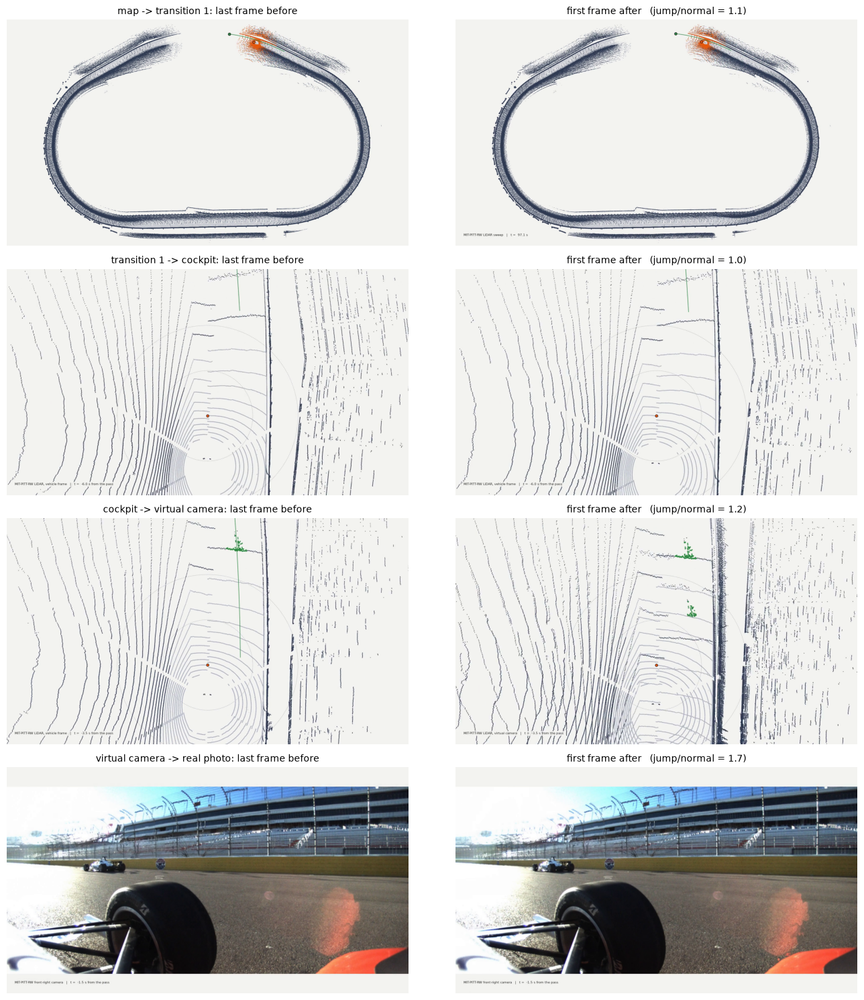

In [65]:
# ======== Phase 5: join the five pieces and check the four seams ========
pieces = ["p1_map_sweep", "p2_transition", "p3_cockpit", "p4_virtual_camera", "p5_camera"]
paths  = [VID / f"{p}.mp4" for p in pieces]
DROP_FIRST = [0, 1, 1, 1, 0]       # pieces 2-4 start with a frame that repeats the end of the previous piece: drop it

# --- 1) all pieces must share size and frame rate ---
info = []
for p in paths:
    g = imageio_ffmpeg.read_frames(str(p)); meta = next(g); g.close()
    n, secs = imageio_ffmpeg.count_frames_and_secs(str(p))
    info.append((meta["size"], round(meta["fps"], 2), n))
    print(f"{p.name:24s} size {meta['size']}  fps {meta['fps']:.2f}  frames {n}  ({secs:.1f} s)")
assert len({(i[0], i[1]) for i in info}) == 1, "pieces differ in size or frame rate, re-render them with the same RENDER settings"

# --- 2) join: drop the repeated frames, then concatenate (re-encoded once, so every cut is frame-exact) ---
final = VID / f"overtake_{W}x{H}_{FPS}fps.mp4"
parts = [f"[{i}:v]" + (f"trim=start_frame={d},setpts=PTS-STARTPTS" if d else "setpts=PTS-STARTPTS") + f"[v{i}]" for i, d in enumerate(DROP_FIRST)]
fg = ";".join(parts) + ";" + "".join(f"[v{i}]" for i in range(len(paths))) + f"concat=n={len(paths)}:v=1:a=0[out]"
cmd = [imageio_ffmpeg.get_ffmpeg_exe(), "-y"] + [x for p in paths for x in ("-i", str(p))] + \
      ["-filter_complex", fg, "-map", "[out]", "-c:v", "libx264", "-crf", "18", "-pix_fmt", "yuv420p", "-r", str(FPS), str(final)]
subprocess.run(cmd, check=True, stderr=subprocess.DEVNULL)
n_final, s_final = imageio_ffmpeg.count_frames_and_secs(str(final))
expect = sum(i[2] - d for i, d in zip(info, DROP_FIRST))
print(f"\n{final.name}: {n_final} frames, {s_final:.1f} s (expected {expect} frames)")

# --- 3) the four seams: last frame before / first frame after, and how big the jump is compared with the normal frame-to-frame change ---
bounds = np.cumsum([i[2] - d for i, d in zip(info, DROP_FIRST)])[:-1]          # index of the first frame after each seam
want_idx = sorted({b + k for b in bounds for k in range(-3, 3)})
keep = {}
gen = imageio_ffmpeg.read_frames(str(final)); meta = next(gen)
for idx, raw in enumerate(gen):
    if idx in want_idx: keep[idx] = np.frombuffer(raw, np.uint8).reshape(meta["size"][1], meta["size"][0], 3)
    if idx > max(want_idx): break
gen.close()
names = ["map -> transition 1", "transition 1 -> cockpit", "cockpit -> virtual camera", "virtual camera -> real photo"]
fig5, axs5 = plt.subplots(4, 2, figsize=(14, 15))
for r, (b, nm) in enumerate(zip(bounds, names)):
    d = [np.abs(keep[b + k + 1].astype(float) - keep[b + k].astype(float)).mean() for k in range(-3, 2)]   # 5 consecutive frame-to-frame changes
    seam, normal = d[2], np.mean([d[0], d[1], d[3], d[4]])
    print(f"seam {r+1} ({nm}): jump {seam:5.1f} vs normal {normal:5.1f}  ->  ratio {seam / max(normal, 1e-6):.1f}")
    axs5[r, 0].imshow(keep[b - 1]); axs5[r, 0].set_title(f"{nm}: last frame before", fontsize=10)
    axs5[r, 1].imshow(keep[b]);     axs5[r, 1].set_title(f"first frame after   (jump/normal = {seam / max(normal, 1e-6):.1f})", fontsize=10)
    axs5[r, 0].axis("off"); axs5[r, 1].axis("off")
plt.tight_layout(); plt.savefig("figures/16_seams.png", dpi=110, bbox_inches="tight"); plt.show()

The final video, `overtake_1920x1080_30fps.mp4`, has 833 frames (27.8 s) and matches the expected number. The ratios at the four seams are 1.1, 1.0, 1.2 and 1.7, so none of the cuts is conspicuous. The highest value, at the transition from the virtual camera to the real photograph, is partly a consequence of the small normal change between consecutive photographs, which lowers the denominator. In absolute terms, the jump at this seam (2.1) is the smallest of the four (5.3, 11.7, 19.1 and 2.1).

## 7. Extension: finding the passing car without being told where it is

### Motivation and idea

Sections 1 to 6 located KAIST with the help of its own log: the position of the car was known, and the LiDAR points near that position were simply labelled as the car. A natural question is whether a program could discover such a car **without** that information. This section tests that idea on the same recording. It is an extension and not a requirement of the video; Sections 1 to 6 do not depend on it.

The idea rests on one observation. MIT-PITT-RW drives the same track for many laps. The walls, fences and stands are at the same place in every lap, whereas another car is at a given place in one lap at most. A map that records how often each place was occupied therefore separates the permanent **background** from the **foreground** that moves. This is the principle of self-training from repeated traversals, which has been used for object detection on public roads (see, for example, the MODEST and OYSTER papers, arXiv 2203.15882 and 2311.02007).

The extension has two stages:

| Stage | What happens | Labels used |
|---|---|---|
| 1 | A persistence map over all laps gives the background. The foreground points are clustered, and clusters of the size of a race car are kept. | none |
| 2 | A small convolutional neural network is trained on bird's-eye-view images of the scans, with the detections of Stage 1 as the only training labels. | the output of Stage 1 |

The log of KAIST is used for **scoring only**: it is never used to find an object and never used to train the network.

### Prerequisites

The cells must be run in the same kernel as Sections 1 to 6, because they use the variables `w`, `OUT`, `s3`, `KEY`, `T_PASS`, `ego`, `calib`, `traj`, `quat_to_rot`, `yaw_rot`, `YAW_FIX_DEG`, `KAIST_DT_CAM`, `KAIST_DT_LIDAR` and `DATA`. Two further packages are needed: `scikit-learn` (clustering) and `torch` (the network). If they are missing, they can be installed with `pip install scikit-learn torch` (the CPU version of PyTorch is sufficient; no graphics card is needed). All new variable names end in `8`, so that they cannot overwrite earlier variables.

### 7.1 Downloading the LiDAR scans of the whole log

Until now only the files around the pass were extracted. For a persistence map, the scans of all laps are needed, which are about 4,200 LiDAR keyframe files (three LiDARs, keyframes only). The cell streams the archive once, as in Section 3, and writes only these files. It can be interrupted and started again: files that are already on disk are skipped. The download is the slowest part of this section and may take about half an hour.

In the run documented here the log contains 4,197 LiDAR keyframe files, from 131 s before to 569 s after the pass of the video.

In [66]:
# ======== 7.1 Download the LiDAR keyframes of the whole log (resumable streaming extraction) ========
import re, time, tarfile

LID_CH = ["LIDAR_FRONT", "LIDAR_LEFT", "LIDAR_RIGHT"]
# The table `w` of Section 3.5 was overwritten later in the notebook (Section 5.8 uses `w` for a width), so it is rebuilt here
ch8 = (calib[["token", "sensor_token"]].rename(columns={"token": "calibrated_sensor_token"})
         .merge(sensor[["token", "channel"]].rename(columns={"token": "sensor_token"}), on="sensor_token"))
w8 = (sd.merge(sample[["token", "scene_token"]].rename(columns={"token": "sample_token"}), on="sample_token")
        .merge(ch8[["calibrated_sensor_token", "channel"]], on="calibrated_sensor_token"))
w8 = w8[w8["scene_token"] == mit_scene].copy()
_ts = w8["timestamp"].astype("float64")
w8["t"] = _ts / 10.0 ** ((np.floor(np.log10(_ts)) + 1).astype(int) - 10)       # same per-value normalisation as before
lid = (w8[w8["channel"].isin(LID_CH) & w8["is_key_frame"]]
         .sort_values("t").reset_index(drop=True))               # every LiDAR keyframe of the MIT-PITT-RW log
todo = lid[~lid["filename"].map(lambda f: (OUT / f).exists())]   # files that are not on disk yet
print(f"{len(lid)} LiDAR keyframe files in the whole log "
      f"({lid['t'].min() - T_PASS:+.0f} s to {lid['t'].max() - T_PASS:+.0f} s from the pass) | {len(todo)} still to download")

def _sec_of(name8):                                                # first 10 digits of the file name = whole seconds
    m8 = re.search(r"__(\d{10})\d*\.", name8)
    return int(m8.group(1)) if m8 else None

if len(todo):
    wanted8 = set(todo["filename"])
    stop_sec8 = int(todo["t"].max()) + 30                         # give up if we read 30 s past the last wanted file
    found8, seen8, t_start8 = set(), 0, time.time()
    obj8 = s3.get_object(Bucket="racecar-dataset", Key=KEY)
    total_gb = obj8.get("ContentLength", 0) / 1e9
    try:
        with tarfile.open(fileobj=obj8["Body"], mode="r|") as tf8:  # sequential streaming, as in Section 4.3
            for m8 in tf8:
                seen8 += 1
                if m8.name in wanted8:
                    tf8.extract(m8, OUT, filter="data")
                    found8.add(m8.name)
                    if len(found8) == len(wanted8):
                        break                                      # got everything
                elif (s8 := _sec_of(m8.name)) is not None and s8 > stop_sec8:
                    break                                          # past the window
                if seen8 % 5000 == 0:
                    print(f"{tf8.offset / 1e9:5.1f} / {total_gb:.1f} GB read | {len(found8)}/{len(wanted8)} found | {time.time() - t_start8:5.0f} s")
    finally:
        obj8["Body"].close()
    print(f"{len(found8)}/{len(wanted8)} found, {len(wanted8) - len(found8)} missing, {time.time() - t_start8:.0f} s")

on_disk = lid["filename"].map(lambda f: (OUT / f).exists())
print(f"{on_disk.sum()}/{len(lid)} LiDAR keyframe files on disk")

4197 LiDAR keyframe files in the whole log (-131 s to +569 s from the pass) | 0 still to download
4197/4197 LiDAR keyframe files on disk


### 7.2 Loading the scans and estimating the local ground

Each scan is transformed into the vehicle frame with the same calibration and the same orientation correction (`YAW_FIX_DEG`) as before. Points between 3 m and 60 m from the car are kept. A **height above the local ground** is then computed for every point: the lowest return in each 1.5 m cell is taken as the ground, empty cells are filled from the nearest cell, and the result is smoothed. A local model is necessary because the track is banked, so a single flat plane would turn parts of the road into apparent obstacles. The positions of KAIST from its log are attached to each scan (`gt`, `gt_d`) for the evaluation only.

In the documented run, 1,399 scans with 95.5 million points were loaded (1.9 GB in memory), and KAIST is within 60 m of the car in 12% of the scans. For the first evaluation the position of KAIST is computed with the clock offset of the camera (`KAIST_DT_CAM`, -0.12 s).

In [67]:
# ======== 7.2 Load every scan: points in the vehicle frame, height above the local ground, and the pose ========
import time
from scipy.ndimage import distance_transform_edt, median_filter

R_MIN, R_MAX = 3.0, 60.0           # keep points between 3 m and 60 m from the car (as in Section 6.1)
G_CELL = 1.5                       # cell size (m) of the local ground model

def ground_height(x, y8, z, R=R_MAX + 4.0, cell=G_CELL):
    """Ground height below every point: lowest return per cell (vehicle frame), empty cells filled from the nearest cell, then smoothed."""
    n = int(2 * R / cell)
    ix = np.clip(((x + R) / cell).astype(int), 0, n - 1); iy = np.clip(((y8 + R) / cell).astype(int), 0, n - 1)
    g8 = np.full((n, n), np.inf); np.minimum.at(g8, (ix, iy), z)
    empty = np.isinf(g8)
    if empty.all():
        return np.full(len(z), np.nan)
    idx8 = distance_transform_edt(empty, return_distances=False, return_indices=True)
    g8 = median_filter(g8[tuple(idx8)], size=3)           # the median removes isolated cells that are too high or too low
    return g8[ix, iy]

poses8 = (lid[lid["channel"] == "LIDAR_FRONT"][["sample_token", "t", "ego_pose_token"]]
          .merge(ego[["token", "translation", "rotation"]].rename(columns={"token": "ego_pose_token"}), on="ego_pose_token")
          .sort_values("t").reset_index(drop=True))
by_sample = {k8: g8 for k8, g8 in lid.groupby("sample_token")}
cal_by_tok = {r["token"]: (quat_to_rot(r["rotation"]), np.array(r["translation"], float)) for _, r in calib.iterrows()}

def load_scan8(i8):
    pr = poses8.iloc[i8]
    parts = []
    for _, r in by_sample[pr["sample_token"]].iterrows():          # the three LiDARs of this keyframe
        pts = np.fromfile(OUT / r["filename"], dtype=np.float32).reshape(-1, 5)
        Rc, tc = cal_by_tok[r["calibrated_sensor_token"]]
        parts.append(np.c_[pts[:, :3].astype(float) @ Rc.T + tc, pts[:, 3]])    # sensor frame -> vehicle frame; x, y, z, intensity
    P8 = np.vstack(parts)
    rr = np.hypot(P8[:, 0], P8[:, 1]); P8 = P8[(rr > R_MIN) & (rr < R_MAX)]
    h = P8[:, 2] - ground_height(P8[:, 0], P8[:, 1], P8[:, 2])          # height above the local ground
    R_g = quat_to_rot(pr["rotation"]) @ yaw_rot(YAW_FIX_DEG)        # vehicle -> global, with the orientation fix of Section 5.2
    return dict(t=float(pr["t"]), R=R_g, p=np.array(pr["translation"], float),
                P=np.c_[P8[:, 0], P8[:, 1], P8[:, 2], h, P8[:, 3]].astype(np.float32))   # columns: x, y, z, height above ground, intensity

t_start8 = time.time(); scans8 = []
for i8 in range(len(poses8)):
    scans8.append(load_scan8(i8))
    if (i8 + 1) % 200 == 0:
        print(f"{i8 + 1}/{len(poses8)} scans | {time.time() - t_start8:4.0f} s")

# --- ground truth for the evaluation only: where KAIST is in the vehicle frame (position from its own log, camera clock offset from Section 5.5, corrected in Section 7.5a)
kai = traj[traj["vehicle"] == "KAIST"].sort_values("t")
for sc8 in scans8:
    pk8 = np.array([np.interp(sc8["t"] + KAIST_DT_CAM, kai["t"], kai["x"]), np.interp(sc8["t"] + KAIST_DT_CAM, kai["t"], kai["y"]), sc8["p"][2]])
    sc8["gt"] = (sc8["R"].T @ (pk8 - sc8["p"]))[:2]
    sc8["gt_d"] = float(np.hypot(*sc8["gt"]))

n_pts = sum(len(s8["P"]) for s8 in scans8)
print(f"{len(scans8)} scans | {n_pts / 1e6:.1f} million points | {n_pts * 20 / 1e9:.1f} GB in memory | {time.time() - t_start8:.0f} s")
print(f"KAIST is within {R_MAX:.0f} m in {np.mean([s8['gt_d'] < R_MAX for s8 in scans8]):.0%} of the scans")

200/1399 scans |    1 s
400/1399 scans |    3 s
600/1399 scans |    4 s
800/1399 scans |    5 s
1000/1399 scans |    6 s
1200/1399 scans |    8 s
1399 scans | 95.5 million points | 1.9 GB in memory | 9 s
KAIST is within 60 m in 12% of the scans


### 7.3 Laps and the persistence map (Figure 17)

The laps are separated at the moments at which the car returns to its starting place, as in Section 3.4. For each lap, a grid of 1 m cells records which cells contained **structure** (points more than 0.4 m above the ground) and which cells were **observed** (the car came within 40 m). The **persistence** of a cell is the share of the observing laps in which it was occupied. A cell belongs to the background if its persistence is at least 0.5 and it was observed in at least three laps. In each scan, the structure points that fall outside the background are the **foreground**.

Figure 17 shows the resulting map. If the method works, the walls and fences should appear as a closed outline of the track, and the foreground should consist of few, isolated points.

In the documented run the algorithm finds 8 laps (lap times from 79 to 108 s) and a persistence map of 897 x 852 cells with 53,035 background cells. Only 0.2% of the 23.9 million structure points are not explained by the map; these are the foreground candidates.

8 laps (lap times in s): [108, 101, 108, 97, 94, 89, 79] + the remainder
8 laps | map 897 x 852 cells | background cells: 53,035 | 0.2% of the 23.9 million structure points are not explained by the map


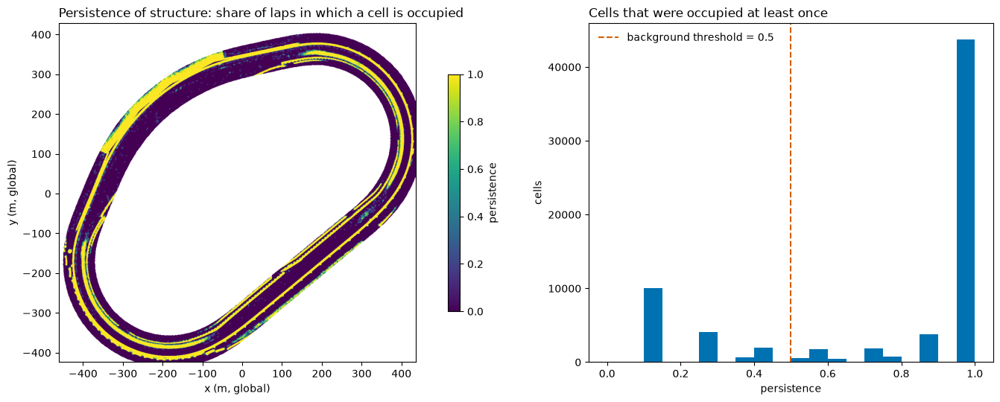

In [68]:
# ======== 7.3 Laps and the persistence map: which places are always occupied? ========
from scipy.ndimage import maximum_filter

H_STRUCT = 0.4      # points more than 0.4 m above the local ground count as "structure" (walls, fences, cars)
C_MAP    = 1.0      # cell size of the persistence map (m)
R_OBS    = 40.0     # a cell was "observed" in a lap if the car came within this distance (m)
P_BG     = 0.5      # background = occupied in at least this share of the laps that observed the cell ...
N_MIN    = 3        # ... and observed in at least this many laps

t8 = np.array([s8["t"] for s8 in scans8]); p8 = np.array([s8["p"][:2] for s8 in scans8])

# --- laps: the moments at which the car is back at its starting place (the same idea as visits() in Section 3.4)
d0 = np.hypot(*(p8 - p8[0]).T)
near8 = np.where(d0 < 25.0)[0]
groups = np.split(near8, np.where(np.diff(t8[near8]) > 30.0)[0] + 1)
bounds8 = np.array([t8[g8[np.argmin(d0[g8])]] for g8 in groups if len(g8)])
seg = np.searchsorted(bounds8[1:], t8, side="right")          # lap number of every scan (0 = first lap)
n_seg = int(seg.max()) + 1
print(f"{n_seg} laps (lap times in s):", np.round(np.diff(bounds8)).astype(int).tolist(), "+ the remainder")

# --- global x, y of the structure points of every scan, and the grid of the map
def glob_xy(sc8, mask):
    return (sc8["P"][mask, :3].astype(float) @ sc8["R"].T + sc8["p"])[:, :2]
Gs = [glob_xy(sc8, sc8["P"][:, 3] > H_STRUCT) for sc8 in scans8]
allg = np.vstack(Gs); x_lo, y_lo = allg.min(0) - 5; x_hi, y_hi = allg.max(0) + 5
nx, ny = int((x_hi - x_lo) / C_MAP) + 1, int((y_hi - y_lo) / C_MAP) + 1
def cell_of(xy):
    return (np.clip(((xy[:, 0] - x_lo) / C_MAP).astype(int), 0, nx - 1),
            np.clip(((xy[:, 1] - y_lo) / C_MAP).astype(int), 0, ny - 1))

# --- for every lap: which cells contain structure, and which cells did the car see?
occ = np.zeros((n_seg, nx, ny), bool); obs = np.zeros((n_seg, nx, ny), bool)
for s_ in range(n_seg):
    idx8 = np.where(seg == s_)[0]
    ix, iy = cell_of(np.vstack([Gs[i8] for i8 in idx8]))
    cnt = np.bincount(ix * ny + iy, minlength=nx * ny).reshape(nx, ny)
    occ[s_] = maximum_filter(cnt >= 1, size=3)                    # 1-cell tolerance for small pose errors between laps
    ex, ey = cell_of(p8[idx8]); ras = np.ones((nx, ny), bool); ras[ex, ey] = False
    obs[s_] = distance_transform_edt(ras) * C_MAP <= R_OBS
n_obs = obs.sum(0); n_occ = (occ & obs).sum(0)
pers = n_occ / np.maximum(n_obs, 1)                                # persistence = occupied in how many of the laps that saw the cell
bg = (n_obs >= N_MIN) & (pers >= P_BG)                             # background (the track itself)
d_bg = distance_transform_edt(~bg) * C_MAP                         # distance of every cell to the nearest background cell

# --- foreground = structure points in cells that were observed often enough and are NOT background
for sc8, g8 in zip(scans8, Gs):
    m8 = sc8["P"][:, 3] > H_STRUCT
    ix, iy = cell_of(g8)
    fg8 = np.zeros(len(sc8["P"]), bool)
    fg8[np.where(m8)[0]] = (n_obs[ix, iy] >= N_MIN) & ~bg[ix, iy]
    sc8["fg"] = fg8
    sc8["struct"] = m8
tot_s = sum(s8["struct"].sum() for s8 in scans8); tot_f = sum(s8["fg"].sum() for s8 in scans8)
print(f"{n_seg} laps | map {nx} x {ny} cells | background cells: {bg.sum():,} | "
      f"{tot_f / tot_s:.1%} of the {tot_s / 1e6:.1f} million structure points are not explained by the map")

# --- Figure 17: the persistence map
fig8, axs8 = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
ext = (x_lo, x_lo + nx * C_MAP, y_lo, y_lo + ny * C_MAP)
im8 = axs8[0].imshow(np.where(n_obs >= 1, pers, np.nan).T, origin="lower", extent=ext, cmap="viridis", vmin=0, vmax=1)
axs8[0].set_aspect("equal"); axs8[0].set_title("Persistence of structure: share of laps in which a cell is occupied", loc="left")
axs8[0].set_xlabel("x (m, global)"); axs8[0].set_ylabel("y (m, global)"); fig8.colorbar(im8, ax=axs8[0], shrink=0.7, label="persistence")
vals = pers[(n_obs >= N_MIN) & (n_occ > 0)]
axs8[1].hist(vals, bins=np.linspace(0, 1, 21), color="#0072B2"); axs8[1].axvline(P_BG, color="#D55E00", ls="--", label=f"background threshold = {P_BG}")
axs8[1].set_xlabel("persistence"); axs8[1].set_ylabel("cells"); axs8[1].set_title("Cells that were occupied at least once", loc="left"); axs8[1].legend(frameon=False)
fig8.tight_layout(); fig8.savefig("figures/17_persistence_map.png", dpi=150, bbox_inches="tight"); plt.show()

### 7.4 Stage 1: clustering the foreground

The foreground points of each scan are grouped with DBSCAN, which joins points that lie close together. Because the LiDAR points become sparser with the distance, the neighbour distance grows with the range beyond 20 m. For each cluster, the length, width and height are computed from the principal axes of its footprint. A cluster is accepted as a car if it is 2.0 to 7.5 m long, 0.8 to 3.2 m wide and 0.4 to 2.2 m high, and if its distance to the persistent structure is at least 2 m, so that parts of a wall are not accepted. These limits are plausible values for a race car and can be changed at the top of the cell.

In the documented run, 446 clusters were found in the 1,399 scans and 124 of them were accepted as car-like (0.09 per scan).

In [69]:
# ======== 7.4 Stage 1: cluster the foreground and keep what looks like a car ========
from sklearn.cluster import DBSCAN

EPS, MIN_PTS = 1.0, 4                                    # DBSCAN: points within 1 m (near the car) are neighbours; a cluster needs at least 4 points
R_SCALE = 20.0                                           # beyond 20 m the neighbour distance grows with the range (the LiDAR points get sparser), up to 3 times
L_OK, W_OK, H_OK = (2.0, 7.5), (0.8, 3.2), (0.4, 2.2)    # plausible length, width and height of a race car (m)
D_FREE = 2.0                                             # the object must stand at least 2 m away from the persistent structure (walls)

def stage1(sc8):
    """Clusters of foreground points in one scan, each with its size; 'ok' = the size looks like a car and it is not part of a wall."""
    P8 = sc8["P"]; idx8 = np.where(sc8["fg"])[0]
    if len(idx8) < MIN_PTS:
        return []
    r = np.hypot(P8[idx8, 0], P8[idx8, 1])
    lab = DBSCAN(eps=EPS, min_samples=MIN_PTS).fit_predict(P8[idx8, :2] / np.clip(r / R_SCALE, 1.0, 3.0)[:, None])   # range-dependent neighbour distance
    out = []
    for k8 in range(lab.max() + 1):
        q = P8[idx8[lab == k8]]
        c8 = q[:, :2].mean(0)
        _, _, vt = np.linalg.svd(q[:, :2] - c8, full_matrices=False)
        proj = (q[:, :2] - c8) @ vt.T                                       # footprint along its two principal axes
        ext = np.sort(proj.max(0) - proj.min(0))[::-1]                     # ext[0] = length, ext[1] = width
        g_xy = (np.r_[c8, q[:, 2].mean()] @ sc8["R"].T + sc8["p"])[:2]
        ix, iy = cell_of(g_xy[None])
        d_free = float(d_bg[ix[0], iy[0]]); hmax = float(q[:, 3].max())
        ok = (L_OK[0] <= ext[0] <= L_OK[1]) and (W_OK[0] <= ext[1] <= W_OK[1]) and (H_OK[0] <= hmax <= H_OK[1]) and d_free >= D_FREE
        out.append(dict(c=c8, n=len(q), L=float(ext[0]), W=float(ext[1]), h=hmax, d_free=d_free, ok=bool(ok)))
    return out

t_beg8 = time.time(); clusters1 = []
for i8, sc8 in enumerate(scans8):
    clusters1.append(stage1(sc8))
    if (i8 + 1) % 400 == 0:
        print(f"{i8 + 1}/{len(scans8)} scans | {time.time() - t_beg8:3.0f} s")
dets1 = [[cl["c"] for cl in cls if cl["ok"]] for cls in clusters1]          # Stage 1 detections: centre of every accepted cluster, vehicle frame
n_cl = sum(len(c8) for c8 in clusters1); n_ok = sum(len(d8) for d8 in dets1)
print(f"{n_cl} clusters found, {n_ok} accepted as car-like ({n_ok / len(scans8):.2f} per scan) | {time.time() - t_beg8:.0f} s")

400/1399 scans |   0 s
800/1399 scans |   0 s
1200/1399 scans |   1 s
446 clusters found, 124 accepted as car-like (0.09 per scan) | 1 s


### 7.5 Evaluation against the trajectory of KAIST (Figure 18)

A detection counts as a hit if its centre lies within 3 m of the logged position of KAIST. The **recall** is the share of scans with KAIST in range in which it was detected; it is reported per distance bin, because distant objects are covered by few LiDAR points. The **precision** is the share of detections that are hits. This value has to be read with care: a detection that does not match KAIST may be a real object that the log does not contain, for instance a third car or a vehicle on the pit lane, so the precision is a lower bound. The cell also counts why KAIST was missed (no cluster, wrong size, or too close to a wall), which indicates which parameter of Section 7.4 to adjust.

**Result of the first evaluation.** With the clock offset of the camera (-0.12 s), recall and precision are both 0%: none of the 124 detections lies within 3 m of KAIST. The lower panels of the figure show why this is surprising. The detections (blue circles) lie on a car, but a few metres ahead of the logged position (green square), at the correct lateral distance. The error is therefore systematic and not random, and the next section investigates it.

KAIST in range in 164 of 1399 scans | recall 0% | precision 0% (0 of 124 detections are within 3 m of KAIST)
recall per distance bin (m): {'0-10': '0/18', '10-20': '0/32', '20-30': '0/30', '30-40': '0/27', '40-50': '0/29', '50-60': '0/28'}
misses by reason: {'no foreground cluster near KAIST': 162, 'cluster rejected: size': 2, 'cluster rejected: touches a wall': 0}


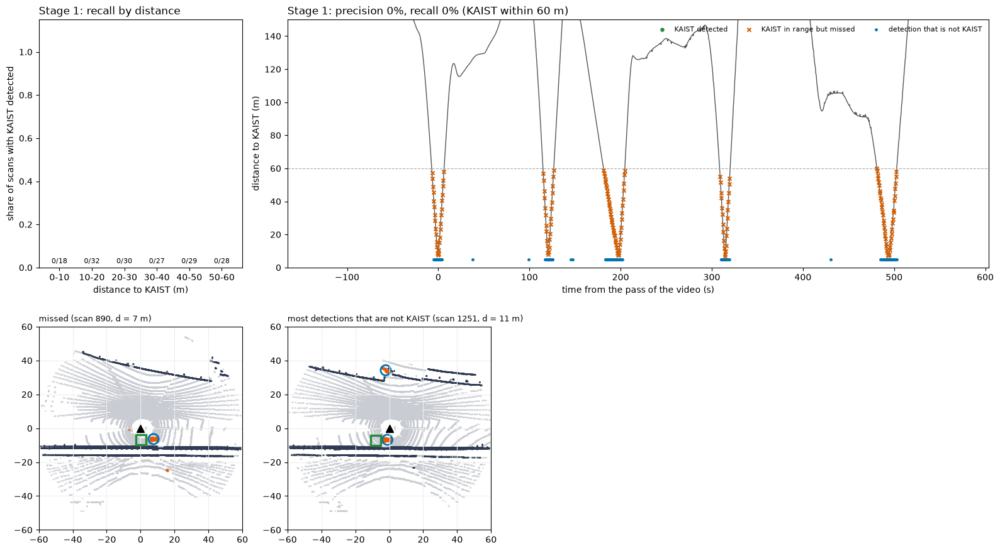

In [70]:
# ======== 7.5 Evaluation against KAIST's own trajectory ========
MATCH_R = 3.0                                    # a detection counts as KAIST if its centre is within 3 m of KAIST's logged position
BINS = np.array([0, 10, 20, 30, 40, 50, 60])     # distance bins (m)
gt_d = np.array([s8["gt_d"] for s8 in scans8]); gt_xy = np.array([s8["gt"] for s8 in scans8])

def evaluate(dets, sel=None):
    """dets[i] = list of (x, y) detections of scan i in the vehicle frame; sel = which scans to score (default all).
    KAIST's trajectory is used here for scoring only, never for finding or training."""
    sel = np.ones(len(scans8), bool) if sel is None else sel
    hit = np.zeros(len(scans8), bool); n_det = n_tp = 0; unmatched = np.zeros(len(scans8), int)
    for i8 in np.where(sel)[0]:
        sc8 = scans8[i8]
        D = np.array(dets[i8], float).reshape(-1, 2); n_det += len(D)
        close = np.hypot(*(D - sc8["gt"]).T) <= MATCH_R if len(D) else np.zeros(0, bool)
        in_range = sc8["gt_d"] < R_MAX
        hit[i8] = in_range and close.any()
        n_tp += int(close.sum()) if in_range else 0
        unmatched[i8] = len(D) - (int(close.sum()) if in_range else 0)
    b = np.digitize(gt_d, BINS) - 1
    tot = np.array([((b == k8) & sel).sum() for k8 in range(len(BINS) - 1)]); got = np.array([(hit & (b == k8)).sum() for k8 in range(len(BINS) - 1)])
    return dict(hit=hit, unmatched=unmatched, tot=tot, got=got, recall=got / np.maximum(tot, 1), sel=sel,
                precision=n_tp / max(n_det, 1), n_det=n_det, n_tp=n_tp)

ev1 = evaluate(dets1)
inr = gt_d < R_MAX
print(f"KAIST in range in {inr.sum()} of {len(scans8)} scans | recall {ev1['hit'].sum() / max(inr.sum(), 1):.0%} | "
      f"precision {ev1['precision']:.0%} ({ev1['n_tp']} of {ev1['n_det']} detections are within {MATCH_R:.0f} m of KAIST)")
print("recall per distance bin (m):", {f"{BINS[k8]}-{BINS[k8+1]}": f"{ev1['got'][k8]}/{ev1['tot'][k8]}" for k8 in range(len(BINS) - 1)})

# --- why was KAIST missed? Look at ALL clusters near KAIST's true position, including the rejected ones
def miss_reasons(clusters, ev):
    reasons = {"no foreground cluster near KAIST": 0, "cluster rejected: size": 0, "cluster rejected: touches a wall": 0}
    for i8 in np.where(inr & ev["sel"] & ~ev["hit"])[0]:
        near_cl = [cl for cl in clusters[i8] if np.hypot(*(cl["c"] - scans8[i8]["gt"])) <= MATCH_R]
        if not near_cl: reasons["no foreground cluster near KAIST"] += 1
        elif all(cl["d_free"] < D_FREE for cl in near_cl): reasons["cluster rejected: touches a wall"] += 1
        else: reasons["cluster rejected: size"] += 1
    return reasons
print("misses by reason:", miss_reasons(clusters1, ev1))

def bev_panel(ax8, i8, dets, title):
    sc8 = scans8[i8]; P8 = sc8["P"]
    ax8.scatter(P8[~sc8["struct"], 0], P8[~sc8["struct"], 1], s=0.3, c="#C9CCD2")
    ax8.scatter(P8[sc8["struct"] & ~sc8["fg"], 0], P8[sc8["struct"] & ~sc8["fg"], 1], s=0.5, c="#2F3B52")
    ax8.scatter(P8[sc8["fg"], 0], P8[sc8["fg"], 1], s=4, c="#E8590C")
    for d8 in dets:
        ax8.add_patch(plt.Circle(d8, MATCH_R, fill=False, ec="#0072B2", lw=2))
    if sc8["gt_d"] < R_MAX:
        ax8.plot(*sc8["gt"], "s", ms=11, mfc="none", mec="#2B8A3E", mew=2.5)
    ax8.plot(0, 0, "^", c="k", ms=9); ax8.set_xlim(-R_MAX, R_MAX); ax8.set_ylim(-R_MAX, R_MAX); ax8.set_aspect("equal")
    ax8.set_title(title, loc="left", fontsize=9); ax8.grid(color="#eee")

def figure_eval(dets, ev, name8, fname):
    t_rel = t8 - T_PASS
    fig8 = plt.figure(figsize=(16, 9)); gs = fig8.add_gridspec(2, 4)
    a8 = fig8.add_subplot(gs[0, 0])
    a8.bar(range(len(BINS) - 1), ev["recall"], color="#0072B2", width=0.7)
    for k8 in range(len(BINS) - 1): a8.text(k8, ev["recall"][k8] + 0.02, f"{ev['got'][k8]}/{ev['tot'][k8]}", ha="center", fontsize=8)
    a8.set_xticks(range(len(BINS) - 1)); a8.set_xticklabels([f"{BINS[k8]}-{BINS[k8+1]}" for k8 in range(len(BINS) - 1)])
    a8.set_ylim(0, 1.15); a8.set_xlabel("distance to KAIST (m)"); a8.set_ylabel("share of scans with KAIST detected"); a8.set_title(f"{name8}: recall by distance", loc="left")
    a8 = fig8.add_subplot(gs[0, 1:]); a8.plot(t_rel, gt_d, c="#555", lw=1); a8.axhline(R_MAX, c="#aaa", ls="--", lw=0.8)
    hit_ = ev["hit"]; miss_ = inr & ev["sel"] & ~hit_
    a8.scatter(t_rel[hit_], gt_d[hit_], s=14, c="#2B8A3E", label="KAIST detected", zorder=3)
    a8.scatter(t_rel[miss_], gt_d[miss_], s=18, c="#D55E00", marker="x", label="KAIST in range but missed", zorder=3)
    a8.scatter(t_rel[ev["unmatched"] > 0], np.full((ev["unmatched"] > 0).sum(), 5), s=6, c="#0072B2", label="detection that is not KAIST", zorder=2)
    if not ev["sel"].all(): a8.scatter(t_rel[ev["sel"]], np.full(ev["sel"].sum(), 148), s=3, c="#999", marker="|", label="scans scored", zorder=1)
    a8.set_ylim(0, 150); a8.set_xlabel("time from the pass of the video (s)"); a8.set_ylabel("distance to KAIST (m)"); a8.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
    a8.set_title(f"{name8}: precision {ev['precision']:.0%}, recall {hit_.sum() / max((inr & ev['sel']).sum(), 1):.0%} (KAIST within {R_MAX:.0f} m)", loc="left")
    ids = []
    near_hit = np.where(hit_ & (gt_d < 25))[0]; far_hit = np.where(hit_ & (gt_d > 40))[0]
    ids += [("detected, close", near_hit[len(near_hit) // 2]) if len(near_hit) else None]
    ids += [("detected, far", far_hit[len(far_hit) // 2]) if len(far_hit) else None]
    mi = np.where(miss_)[0]; ids += [("missed", mi[np.argmin(gt_d[mi])]) if len(mi) else None]
    fpi = np.argsort(-ev["unmatched"])[0]; ids += [("most detections that are not KAIST", fpi) if ev["unmatched"][fpi] > 0 else None]
    for k8, it in enumerate([x for x in ids if x]):
        a8 = fig8.add_subplot(gs[1, k8]); bev_panel(a8, it[1], dets[it[1]], f"{it[0]} (scan {it[1]}, d = {gt_d[it[1]]:.0f} m)")
    fig8.tight_layout(); fig8.savefig(fname, dpi=130, bbox_inches="tight"); plt.show()

figure_eval(dets1, ev1, "Stage 1", "figures/18_stage1_evaluation.png")

### 7.5a Checking the alignment of KAIST's logged position with the LiDAR

The first evaluation failed in a systematic way: recall and precision were both 0%, although the detections lie on a car. They are consistently a few metres ahead of the logged position of KAIST, at the correct lateral distance. A real car and a real trajectory can only disagree in this way if they are shifted against each other, either in space (the logged point is not the centre of the car) or in time (the clocks differ, so that the log refers to a slightly different moment). A time error moves the logged position along the path of KAIST by its speed multiplied by the error. KAIST drives at about 24 m/s here, so an error of 0.2 s corresponds to about 5 m.

The following cell recomputes the position of KAIST for many clock offsets `dt` and compares it with the nearest Stage 1 detection. Each row of the table gives the number of scans in which a detection lies within 15 m of the logged position, the median residual (detection minus logged position, in the vehicle frame), the number of scans within 3 m of the log, and the number of scans whose residual lies within 2 m of the median ("agree"). A clock error shows up as a best `dt` that differs from the camera value; a fixed mounting offset would show up as a constant residual at the best `dt`. The best value is then used for the scoring. The constants of the video cells are not changed by this cell.

**Result.** The table has one sharp maximum at **dt = +0.10 s**. At this value all 117 scans in which a detection lies near KAIST are within 3 m of the log, and the median residual is only 0.27 m forward and 0.04 m sideways. A step of 0.1 s in either direction removes most of the agreement (1 and 87 scans within 3 m), and the residual changes by about 2.4 m per 0.1 s, which is the speed of KAIST. The remaining residual is too small to indicate a mounting offset, so the discrepancy is a **clock difference of about 0.22 s** between the value fitted on the camera photograph (-0.12 s) and the value that fits the LiDAR (+0.10 s). A possible reason is that the camera and the LiDAR are timestamped in different ways; this was not tested.

In [71]:
# ======== 7.5a Diagnostic: is the logged position of KAIST offset from what the LiDAR sees? ========
# For many clock offsets dt, KAIST's logged position is recomputed and compared with the nearest Stage 1 detection.
# 'agree' = number of scans whose residual lies within 2 m of the median residual (the more scans agree on one offset, the better the dt).
# A clock error shows up as a best dt different from KAIST_DT; a fixed mounting offset shows up as a constant residual (dx, dy) at the best dt.
kai8 = traj[traj["vehicle"] == "KAIST"].sort_values("t")
kt8, kx8, ky8 = kai8["t"].to_numpy(), kai8["x"].to_numpy(), kai8["y"].to_numpy()
s_t = np.array([s8["t"] for s8 in scans8]); s_p = np.array([s8["p"] for s8 in scans8]); s_R = np.array([s8["R"] for s8 in scans8])

def gt_at(dt):
    pk = np.c_[np.interp(s_t + dt, kt8, kx8), np.interp(s_t + dt, kt8, ky8), s_p[:, 2]]
    return np.einsum("nji,nj->ni", s_R, pk - s_p)[:, :2]                      # R^T (pk - p) for every scan; vehicle frame

def residuals(dt, radius=15.0):
    g8 = gt_at(dt); res = []
    for i8, d8 in enumerate(dets1):
        if len(d8) == 0 or np.hypot(*g8[i8]) > 60: continue
        dd = np.asarray(d8) - g8[i8]; j8 = np.argmin(np.hypot(dd[:, 0], dd[:, 1]))
        if np.hypot(*dd[j8]) < radius: res.append(dd[j8])
    return np.array(res).reshape(-1, 2)

print(f"{'dt (s)':>7} | {'scans':>5} | {'median dx':>9} | {'median dy':>9} | {'hits<3 m':>8} | {'agree':>5}")
best = None
for dt8 in np.round(np.arange(-2.0, 2.01, 0.1), 2):
    r8 = residuals(dt8)
    if len(r8) < 10:
        print(f"{dt8:7.2f} | {len(r8):5d} |"); continue
    med = np.median(r8, 0); agree = int((np.hypot(*(r8 - med).T) < 2.0).sum()); hits = int((np.hypot(r8[:, 0], r8[:, 1]) < MATCH_R).sum())
    print(f"{dt8:7.2f} | {len(r8):5d} | {med[0]:+9.2f} | {med[1]:+9.2f} | {hits:8d} | {agree:5d}")
    if best is None or agree > best[1]: best = (dt8, agree, med, len(r8))
if best:
    print(f"\nmost scans agree at dt = {best[0]:+.2f} s (KAIST_DT_CAM = {KAIST_DT_CAM:+.2f} s); residual of the detections relative to the log there: "
          f"dx = {best[2][0]:+.2f} m (forward), dy = {best[2][1]:+.2f} m (left)")

# --- use the best dt for the scoring of Section 7 only (the video cells keep their own constants)
KAIST_DT_LIDAR = float(best[0]) if best else KAIST_DT_LIDAR
g8 = gt_at(KAIST_DT_LIDAR)
for i8, s8 in enumerate(scans8):
    s8["gt"] = g8[i8]; s8["gt_d"] = float(np.hypot(*g8[i8]))
print(f"KAIST's position for the scoring now uses dt = {KAIST_DT_LIDAR:+.2f} s. The next cell scores the detections again.")

 dt (s) | scans | median dx | median dy | hits<3 m | agree
  -2.00 |     0 |
  -1.90 |     0 |
  -1.80 |     0 |
  -1.70 |     0 |
  -1.60 |     0 |
  -1.50 |     0 |
  -1.40 |     0 |
  -1.30 |     0 |
  -1.20 |     0 |
  -1.10 |     0 |
  -1.00 |     0 |
  -0.90 |     0 |
  -0.80 |     0 |
  -0.70 |     1 |
  -0.60 |    38 |    +13.76 |     +0.41 |        0 |    38
  -0.50 |    57 |    +12.20 |     +0.24 |        0 |    54
  -0.40 |    80 |    +10.84 |     +0.22 |        0 |    56
  -0.30 |   113 |     +9.93 |     +0.14 |        0 |    59
  -0.20 |   115 |     +7.79 |     +0.04 |        0 |    90
  -0.10 |   116 |     +5.47 |     -0.03 |        1 |   110
   0.00 |   116 |     +2.68 |     -0.09 |       69 |   110
   0.10 |   117 |     +0.27 |     -0.04 |      117 |   114
   0.20 |   116 |     -2.00 |     +0.01 |       87 |    98
   0.30 |   113 |     -4.19 |     +0.07 |       10 |    78
   0.40 |   111 |     -6.37 |     +0.08 |        0 |    68
   0.50 |   105 |     -8.53 |     +0.09 

### 7.5b Evaluation with the corrected clock offset (Figure 18, second version)

The evaluation of Section 7.5 is repeated with the value found above. The saved file `figures/18_stage1_evaluation.png` holds this second version.

**Result.** KAIST is within 60 m in 161 of the 1,399 scans, and Stage 1 detects it in 73% of them (117 scans). Of the 124 detections, 117 lie within 3 m of KAIST, which gives a precision of 94%. The other 7 detections were not inspected; they may be real objects that are missing from the log or false detections. The recall by distance is 16 of 17 scans at 0 to 10 m, 29 of 33 at 10 to 20 m, 28 of 30 at 20 to 30 m, 22 of 27 at 30 to 40 m, 12 of 26 at 40 to 50 m and 10 of 28 at 50 to 60 m. Of the 44 misses, 13 had no foreground cluster near KAIST (typically at long range, where few LiDAR points hit the car), 21 were rejected because of their size and 10 because the cluster touches a wall. The size limits therefore remove more true detections than any other step, and they are the first parameter to relax in a continuation of this work.

KAIST in range in 161 of 1399 scans | recall 73% | precision 94% (117 of 124 detections are within 3 m of KAIST)
recall per distance bin (m): {'0-10': '16/17', '10-20': '29/33', '20-30': '28/30', '30-40': '22/27', '40-50': '12/26', '50-60': '10/28'}
misses by reason: {'no foreground cluster near KAIST': 13, 'cluster rejected: size': 21, 'cluster rejected: touches a wall': 10}


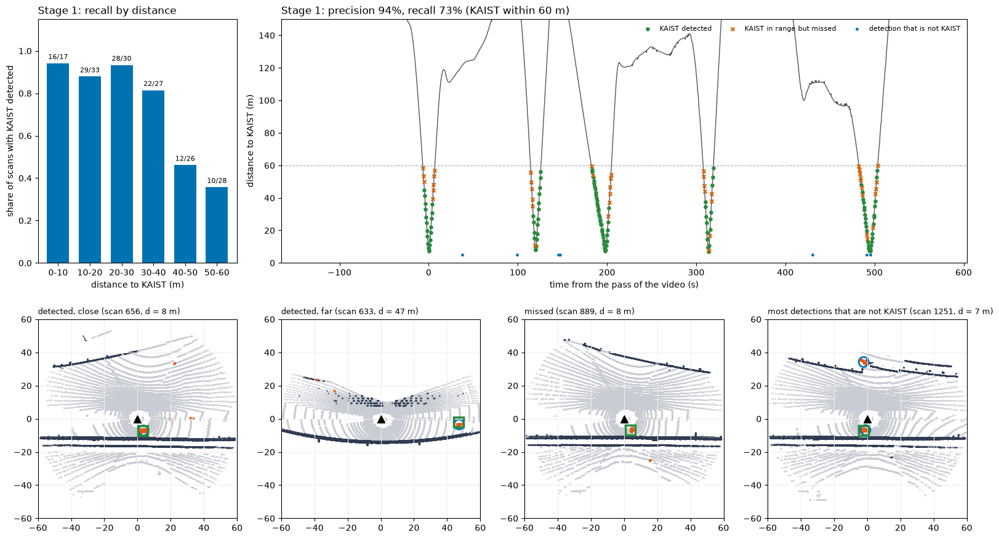

In [70]:
# ======== 7.5b The same evaluation again, now with the clock offset of the LiDAR (Figure 18, second version) ========
MATCH_R = 3.0                                    # a detection counts as KAIST if its centre is within 3 m of KAIST's logged position
BINS = np.array([0, 10, 20, 30, 40, 50, 60])     # distance bins (m)
gt_d = np.array([s8["gt_d"] for s8 in scans8]); gt_xy = np.array([s8["gt"] for s8 in scans8])

def evaluate(dets, sel=None):
    """dets[i] = list of (x, y) detections of scan i in the vehicle frame; sel = which scans to score (default all).
    KAIST's trajectory is used here for scoring only, never for finding or training."""
    sel = np.ones(len(scans8), bool) if sel is None else sel
    hit = np.zeros(len(scans8), bool); n_det = n_tp = 0; unmatched = np.zeros(len(scans8), int)
    for i8 in np.where(sel)[0]:
        sc8 = scans8[i8]
        D = np.array(dets[i8], float).reshape(-1, 2); n_det += len(D)
        close = np.hypot(*(D - sc8["gt"]).T) <= MATCH_R if len(D) else np.zeros(0, bool)
        in_range = sc8["gt_d"] < R_MAX
        hit[i8] = in_range and close.any()
        n_tp += int(close.sum()) if in_range else 0
        unmatched[i8] = len(D) - (int(close.sum()) if in_range else 0)
    b = np.digitize(gt_d, BINS) - 1
    tot = np.array([((b == k8) & sel).sum() for k8 in range(len(BINS) - 1)]); got = np.array([(hit & (b == k8)).sum() for k8 in range(len(BINS) - 1)])
    return dict(hit=hit, unmatched=unmatched, tot=tot, got=got, recall=got / np.maximum(tot, 1), sel=sel,
                precision=n_tp / max(n_det, 1), n_det=n_det, n_tp=n_tp)

ev1 = evaluate(dets1)
inr = gt_d < R_MAX
print(f"KAIST in range in {inr.sum()} of {len(scans8)} scans | recall {ev1['hit'].sum() / max(inr.sum(), 1):.0%} | "
      f"precision {ev1['precision']:.0%} ({ev1['n_tp']} of {ev1['n_det']} detections are within {MATCH_R:.0f} m of KAIST)")
print("recall per distance bin (m):", {f"{BINS[k8]}-{BINS[k8+1]}": f"{ev1['got'][k8]}/{ev1['tot'][k8]}" for k8 in range(len(BINS) - 1)})

# --- why was KAIST missed? Look at ALL clusters near KAIST's true position, including the rejected ones
def miss_reasons(clusters, ev):
    reasons = {"no foreground cluster near KAIST": 0, "cluster rejected: size": 0, "cluster rejected: touches a wall": 0}
    for i8 in np.where(inr & ev["sel"] & ~ev["hit"])[0]:
        near_cl = [cl for cl in clusters[i8] if np.hypot(*(cl["c"] - scans8[i8]["gt"])) <= MATCH_R]
        if not near_cl: reasons["no foreground cluster near KAIST"] += 1
        elif all(cl["d_free"] < D_FREE for cl in near_cl): reasons["cluster rejected: touches a wall"] += 1
        else: reasons["cluster rejected: size"] += 1
    return reasons
print("misses by reason:", miss_reasons(clusters1, ev1))

def bev_panel(ax8, i8, dets, title):
    sc8 = scans8[i8]; P8 = sc8["P"]
    ax8.scatter(P8[~sc8["struct"], 0], P8[~sc8["struct"], 1], s=0.3, c="#C9CCD2")
    ax8.scatter(P8[sc8["struct"] & ~sc8["fg"], 0], P8[sc8["struct"] & ~sc8["fg"], 1], s=0.5, c="#2F3B52")
    ax8.scatter(P8[sc8["fg"], 0], P8[sc8["fg"], 1], s=4, c="#E8590C")
    for d8 in dets:
        ax8.add_patch(plt.Circle(d8, MATCH_R, fill=False, ec="#0072B2", lw=2))
    if sc8["gt_d"] < R_MAX:
        ax8.plot(*sc8["gt"], "s", ms=11, mfc="none", mec="#2B8A3E", mew=2.5)
    ax8.plot(0, 0, "^", c="k", ms=9); ax8.set_xlim(-R_MAX, R_MAX); ax8.set_ylim(-R_MAX, R_MAX); ax8.set_aspect("equal")
    ax8.set_title(title, loc="left", fontsize=9); ax8.grid(color="#eee")

def figure_eval(dets, ev, name8, fname):
    t_rel = t8 - T_PASS
    fig8 = plt.figure(figsize=(16, 9)); gs = fig8.add_gridspec(2, 4)
    a8 = fig8.add_subplot(gs[0, 0])
    a8.bar(range(len(BINS) - 1), ev["recall"], color="#0072B2", width=0.7)
    for k8 in range(len(BINS) - 1): a8.text(k8, ev["recall"][k8] + 0.02, f"{ev['got'][k8]}/{ev['tot'][k8]}", ha="center", fontsize=8)
    a8.set_xticks(range(len(BINS) - 1)); a8.set_xticklabels([f"{BINS[k8]}-{BINS[k8+1]}" for k8 in range(len(BINS) - 1)])
    a8.set_ylim(0, 1.15); a8.set_xlabel("distance to KAIST (m)"); a8.set_ylabel("share of scans with KAIST detected"); a8.set_title(f"{name8}: recall by distance", loc="left")
    a8 = fig8.add_subplot(gs[0, 1:]); a8.plot(t_rel, gt_d, c="#555", lw=1); a8.axhline(R_MAX, c="#aaa", ls="--", lw=0.8)
    hit_ = ev["hit"]; miss_ = inr & ev["sel"] & ~hit_
    a8.scatter(t_rel[hit_], gt_d[hit_], s=14, c="#2B8A3E", label="KAIST detected", zorder=3)
    a8.scatter(t_rel[miss_], gt_d[miss_], s=18, c="#D55E00", marker="x", label="KAIST in range but missed", zorder=3)
    a8.scatter(t_rel[ev["unmatched"] > 0], np.full((ev["unmatched"] > 0).sum(), 5), s=6, c="#0072B2", label="detection that is not KAIST", zorder=2)
    if not ev["sel"].all(): a8.scatter(t_rel[ev["sel"]], np.full(ev["sel"].sum(), 148), s=3, c="#999", marker="|", label="scans scored", zorder=1)
    a8.set_ylim(0, 150); a8.set_xlabel("time from the pass of the video (s)"); a8.set_ylabel("distance to KAIST (m)"); a8.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
    a8.set_title(f"{name8}: precision {ev['precision']:.0%}, recall {hit_.sum() / max((inr & ev['sel']).sum(), 1):.0%} (KAIST within {R_MAX:.0f} m)", loc="left")
    ids = []
    near_hit = np.where(hit_ & (gt_d < 25))[0]; far_hit = np.where(hit_ & (gt_d > 40))[0]
    ids += [("detected, close", near_hit[len(near_hit) // 2]) if len(near_hit) else None]
    ids += [("detected, far", far_hit[len(far_hit) // 2]) if len(far_hit) else None]
    mi = np.where(miss_)[0]; ids += [("missed", mi[np.argmin(gt_d[mi])]) if len(mi) else None]
    fpi = np.argsort(-ev["unmatched"])[0]; ids += [("most detections that are not KAIST", fpi) if ev["unmatched"][fpi] > 0 else None]
    for k8, it in enumerate([x for x in ids if x]):
        a8 = fig8.add_subplot(gs[1, k8]); bev_panel(a8, it[1], dets[it[1]], f"{it[0]} (scan {it[1]}, d = {gt_d[it[1]]:.0f} m)")
    fig8.tight_layout(); fig8.savefig(fname, dpi=130, bbox_inches="tight"); plt.show()

figure_eval(dets1, ev1, "Stage 1", "figures/18_stage1_evaluation.png")

### 7.6 Stage 2: images, automatic labels and the split in time

Each scan is converted into a bird's-eye-view image of 160 x 160 cells (0.5 m each, 40 m in every direction) with four channels: number of structure points, highest point, mean intensity and number of ground points. The training target is a heat map with a Gaussian peak at the centre of every detection of Stage 1.

The split into training and test data is made **in time**, by whole encounters with KAIST. The encounter of the video pass is always in the test set, together with one more, and a buffer of 30 s on both sides is removed from the training data. Neighbouring scans are nearly identical, so a random split would let the network see the test objects in the training data and would overstate its quality.

In the documented run, 98 of the 1,399 scans contain an automatic label. There are five encounters with KAIST. The encounter at the pass of the video and the one 194 s later form the test set (151 scans); 1,090 scans remain for training, of which 53 contain a label.

In [72]:
# ======== 7.6 Stage 2: bird's-eye-view images, automatic labels from Stage 1, and a split in time ========
BEV_B, BEV_C = 40.0, 0.5                       # the model sees +-40 m around the car, in cells of 0.5 m
NB = int(2 * BEV_B / BEV_C)                    # 160 x 160 cells

def bev_image(sc8):
    """Four channels per cell (vehicle frame, x forward): structure points, highest point, mean intensity, ground points."""
    P8 = sc8["P"]
    ix = np.floor((P8[:, 0] + BEV_B) / BEV_C).astype(int); iy = np.floor((P8[:, 1] + BEV_B) / BEV_C).astype(int)
    ok = (ix >= 0) & (ix < NB) & (iy >= 0) & (iy < NB)
    flat = (ix * NB + iy)[ok]; h = P8[ok, 3]; it = np.clip(P8[ok, 4], 0, 1); st = h > H_STRUCT
    n_hi = np.bincount(flat[st], minlength=NB * NB); n_lo = np.bincount(flat[~st], minlength=NB * NB)
    hmax = np.zeros(NB * NB); np.maximum.at(hmax, flat, np.clip(h, 0, 2.5))
    mean_i = np.bincount(flat, weights=it, minlength=NB * NB) / np.maximum(n_hi + n_lo, 1)
    img = np.stack([np.log1p(n_hi) / np.log(9), hmax / 2.5, np.clip(mean_i / 0.3, 0, 1), np.log1p(n_lo) / np.log(9)])
    return img.reshape(4, NB, NB).astype(np.float16)

II, JJ = np.meshgrid(np.arange(NB), np.arange(NB), indexing="ij")
def heat_target(centres, sigma=2.0):
    """A soft peak (a Gaussian, 1 m wide) at every automatic label; the cell nearest to the label has the value 1."""
    t = np.zeros((NB, NB), np.float32)
    for c8 in centres:
        fx, fy = (c8[0] + BEV_B) / BEV_C - 0.5, (c8[1] + BEV_B) / BEV_C - 0.5
        if 0 <= fx < NB - 0.5 and 0 <= fy < NB - 0.5:
            t = np.maximum(t, np.exp(-((II - fx) ** 2 + (JJ - fy) ** 2) / (2 * sigma ** 2)).astype(np.float32))
            t[int(round(fx)), int(round(fy))] = 1.0
    return t

t_beg8 = time.time()
X = np.stack([bev_image(sc8) for sc8 in scans8])                    # (scans, 4, 160, 160)
Y = np.stack([heat_target(d8) for d8 in dets1])                     # labels come from Stage 1 only (no KAIST information)
has_pos = Y.reshape(len(Y), -1).max(1) >= 0.99
print(f"images {X.shape} ({X.nbytes / 1e6:.0f} MB) | {has_pos.sum()} scans contain an automatic label | {time.time() - t_beg8:.0f} s")

# --- split in time: whole encounters with KAIST are held out, so the model is tested on passes it has never seen
inr = gt_d < R_MAX
idx_in = np.where(inr)[0]
groups = np.split(idx_in, np.where(np.diff(t8[idx_in]) > 20.0)[0] + 1)     # one group per encounter with KAIST
enc = [(t8[g8[0]], t8[g8[-1]]) for g8 in groups if len(g8)]
k_video = int(np.argmin([abs(0.5 * (a8 + b) - T_PASS) for a8, b in enc]))   # the encounter of the video is always in the test set
test_enc = sorted({k_video, (k_video + 2) % len(enc)})
test = np.zeros(len(scans8), bool); buffer = np.zeros(len(scans8), bool)
for k8 in test_enc:
    test |= (t8 >= enc[k8][0] - 10) & (t8 <= enc[k8][1] + 10)            # test: the encounter and 10 s around it
    buffer |= (t8 >= enc[k8][0] - 30) & (t8 <= enc[k8][1] + 30)          # nothing within 30 s of a test encounter is used for training
train = ~buffer
print(f"{len(enc)} encounters with KAIST; test encounters {test_enc} at "
      f"{[f'{(enc[k8][0] + enc[k8][1]) / 2 - T_PASS:+.0f} s' for k8 in test_enc]} from the pass")
print(f"train: {train.sum()} scans ({(train & has_pos).sum()} with an automatic label) | test: {test.sum()} scans")

images (1399, 4, 160, 160) (287 MB) | 98 scans contain an automatic label | 7 s
5 encounters with KAIST; test encounters [0, 2] at ['+0 s', '+194 s'] from the pass
train: 1090 scans (53 with an automatic label) | test: 151 scans


### 7.7 Stage 2: training the network (Figure 19)

The network is a small U-Net with about 144,000 parameters. It is trained with a focal loss, which is suited to heat maps in which almost all cells are empty, and with mirrored images as augmentation. Training runs on the CPU. The number of epochs can be changed with the variable `EPOCHS` at the top of the cell. Figure 19 shows the training loss; it should fall steadily, and a loss that stays flat would indicate that Stage 1 has produced too few labels.

In the documented run, the loss falls from 4.3 in the first epoch to 0.15 in the last (it is not monotonic, because of the random mirroring and the random choice of scans without a label), and the training takes about 70 s.

144,113 parameters | 53 training scans with a label, 1037 without
epoch  1/20 | loss 4.346 |    3 s
epoch  2/20 | loss 3.615 |    7 s
epoch  3/20 | loss 2.758 |   11 s
epoch  4/20 | loss 1.955 |   14 s
epoch  5/20 | loss 1.250 |   18 s
epoch  6/20 | loss 1.523 |   21 s
epoch  7/20 | loss 0.868 |   25 s
epoch  8/20 | loss 0.607 |   28 s
epoch  9/20 | loss 0.596 |   32 s
epoch 10/20 | loss 0.483 |   35 s
epoch 11/20 | loss 0.894 |   39 s
epoch 12/20 | loss 0.799 |   42 s
epoch 13/20 | loss 0.394 |   46 s
epoch 14/20 | loss 0.385 |   49 s
epoch 15/20 | loss 0.378 |   53 s
epoch 16/20 | loss 0.450 |   56 s
epoch 17/20 | loss 0.307 |   60 s
epoch 18/20 | loss 0.221 |   64 s
epoch 19/20 | loss 0.262 |   67 s
epoch 20/20 | loss 0.151 |   71 s


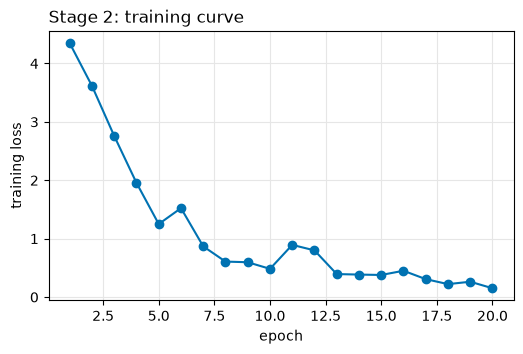

In [73]:
# ======== 7.7 Stage 2: a small convolutional network learns to find the centres of the automatic labels ========
import os, torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(0); rng_t = np.random.default_rng(0)
torch.set_num_threads(max(1, os.cpu_count() or 1))

def conv_bn(i8, o, stride=1, dil=1):
    return nn.Sequential(nn.Conv2d(i8, o, 3, stride, padding=dil, dilation=dil, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class SmallNet(nn.Module):
    """U-Net with two down steps: 160 -> 80 -> 40 cells; dilated convolutions in the middle widen the field of view to about 20 m."""
    def __init__(self, c_in=4, w=16):
        super().__init__()
        self.e0 = nn.Sequential(conv_bn(c_in, w), conv_bn(w, w))
        self.e1 = nn.Sequential(conv_bn(w, 2 * w, 2), conv_bn(2 * w, 2 * w))
        self.e2 = nn.Sequential(conv_bn(2 * w, 4 * w, 2), conv_bn(4 * w, 4 * w, dil=2), conv_bn(4 * w, 4 * w, dil=4))
        self.u1 = conv_bn(4 * w + 2 * w, 2 * w); self.u0 = conv_bn(2 * w + w, w)
        self.head = nn.Conv2d(w, 1, 1); nn.init.constant_(self.head.bias, -4.0)     # start with "nothing here" everywhere
    def forward(self, x):
        a8 = self.e0(x); b = self.e1(a8); c8 = self.e2(b)
        u = self.u1(torch.cat([F.interpolate(c8, scale_factor=2), b], 1))
        u = self.u0(torch.cat([F.interpolate(u, scale_factor=2), a8], 1))
        return self.head(u)[:, 0]

def focal_loss(logits, target):
    """Heat-map loss of CenterNet: strong penalty for missing a peak, weak penalty for firing near a peak, rare peaks do not drown."""
    p = torch.sigmoid(logits).clamp(1e-4, 1 - 1e-4); pos = target.eq(1).float()
    l_pos = -(((1 - p) ** 2) * torch.log(p) * pos).sum()
    l_neg = -(((1 - target) ** 4) * (p ** 2) * torch.log(1 - p) * (1 - pos)).sum()
    return (l_pos + l_neg) / pos.sum().clamp(min=1)

EPOCHS, BATCH, LR = int(os.environ.get("EP", 20)), 16, 2e-3
model = SmallNet(); opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
pos_idx = np.where(train & has_pos)[0]; neg_idx = np.where(train & ~has_pos)[0]
assert len(pos_idx) > 0, "Stage 1 found no car-like objects in the training scans: relax the size limits in Section 7.4 first"
steps_per_epoch = int(np.ceil((len(pos_idx) + min(len(neg_idx), 2 * len(pos_idx) + 16)) / BATCH))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters | {len(pos_idx)} training scans with a label, {len(neg_idx)} without")

def make_batch(idx8):
    x = torch.from_numpy(X[idx8].astype(np.float32)); y8 = torch.from_numpy(Y[idx8])
    for j in range(len(idx8)):                                       # random mirror images (a car looks like a car from any side)
        if rng_t.random() < 0.5: x[j] = x[j].flip(1); y8[j] = y8[j].flip(0)
        if rng_t.random() < 0.5: x[j] = x[j].flip(2); y8[j] = y8[j].flip(1)
    return x, y8

hist = []; t_beg8 = time.time()
for ep in range(EPOCHS):
    model.train()
    neg = rng_t.choice(neg_idx, size=min(len(neg_idx), 2 * len(pos_idx) + 16), replace=False)    # all labelled scans + twice as many empty ones
    idx8 = np.r_[pos_idx, neg]; rng_t.shuffle(idx8); tot = 0.0; nb = 0
    for s8 in range(0, len(idx8), BATCH):
        x, y8 = make_batch(idx8[s8:s8 + BATCH])
        loss = focal_loss(model(x), y8)
        opt.zero_grad(); loss.backward(); opt.step()
        sched.step(); tot += float(loss); nb += 1
    hist.append(tot / nb)
    print(f"epoch {ep + 1:2d}/{EPOCHS} | loss {hist[-1]:.3f} | {time.time() - t_beg8:4.0f} s")
torch.save(model.state_dict(), DATA / "detector.pt")
fig8, ax8 = plt.subplots(figsize=(6, 3.5)); ax8.plot(range(1, EPOCHS + 1), hist, "o-", c="#0072B2")
ax8.set_xlabel("epoch"); ax8.set_ylabel("training loss"); ax8.set_title("Stage 2: training curve", loc="left"); ax8.grid(color="#e6e6e6")
fig8.savefig("figures/19_training_curve.png", dpi=150, bbox_inches="tight"); plt.show()

### 7.8 Comparison of the two stages on held-out data (Figures 20 and 21)

The trained network is applied to the test scans, whose objects it has never seen. Peaks of the heat map above a threshold of 0.3 are taken as detections, and the recall per distance bin and the precision-recall curve are compared with those of Stage 1. Because the network learns from the output of Stage 1, it can only be expected to reproduce it, not to exceed it by much. Two outcomes would still be informative. If the recall is similar, then the network has learned to recognise cars from shape alone, without the persistence map, which would allow it to be applied to a track without repeated laps. If it is lower, then the persistence map contributes information that the network does not recover from a single scan.

**Results.** On the 151 held-out scans, KAIST is within 60 m in 72. Stage 1 detects it in 56 of them (recall 78%) with a precision of 100% (56 detections), and the trained network detects it in 43 (recall 60%) with a precision of 98% (48 detections). Both stages are almost perfect close to the car and become weaker with distance, because the LiDAR returns on a car are sparse at long range: Stage 1 finds KAIST in 45 of the 48 scans up to 40 m and in 11 of the 24 scans between 40 and 60 m, and the network finds it in 43 of 48 and in none of 24. The network was trained on only 53 scans with an automatic label, and its training loss fell from 4.3 to 0.15 in 20 epochs. The result is therefore a proof of concept on one other car and two held-out encounters, not an estimate of general performance. The network matches Stage 1 close to the car and falls behind at range, which is the expected direction, since it learns from the output of Stage 1 and has no map.

Figure 21 shows four scans in the seconds before the pass with the heat map, the detections of both stages and the position of KAIST from its log.

Stage 1 (map + clustering)   | recall  78% | precision 100% | 56 detections in 151 held-out scans
Stage 2 (trained network)    | recall  60% | precision  98% | 48 detections in 151 held-out scans
recall per distance bin (held-out passes), Stage 1 vs Stage 2:
   0-10 m:   7/  7   vs     7/  7
  10-20 m:  14/ 14   vs    12/ 14
  20-30 m:  13/ 14   vs    13/ 14
  30-40 m:  11/ 13   vs    11/ 13
  40-50 m:   7/ 11   vs     0/ 11
  50-60 m:   4/ 13   vs     0/ 13


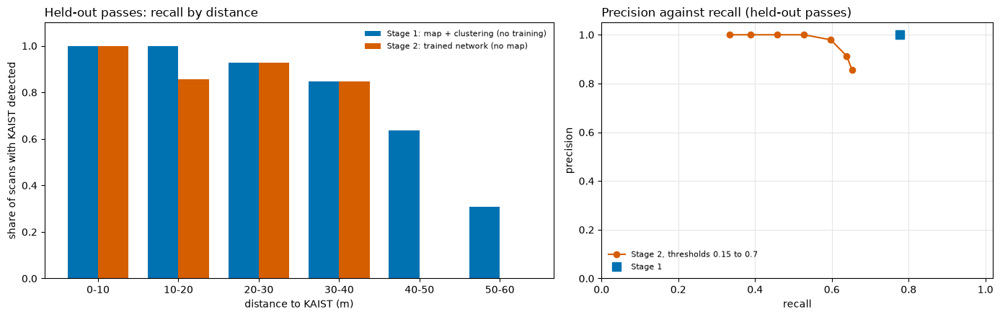

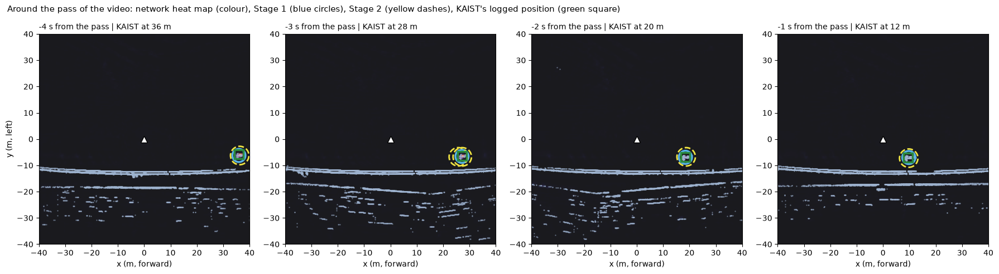

In [74]:
# ======== 7.8 Stage 2: detections of the trained network, and the comparison with Stage 1 on the held-out passes ========
THR = 0.3                                            # a peak of the heat map above this value is a detection

@torch.no_grad()
def predict(idx8, thr=THR):
    """Run the network on the scans idx; returns, per scan, the detected centres (vehicle frame) and the heat maps."""
    model.eval(); dets = [[] for _ in scans8]; heat = {}
    for s8 in range(0, len(idx8), 32):
        b = idx8[s8:s8 + 32]
        h = torch.sigmoid(model(torch.from_numpy(X[b].astype(np.float32))))
        pk8 = (h == F.max_pool2d(h[:, None], 5, 1, 2)[:, 0]) & (h > thr)                 # local maxima = one detection per object
        for j, i8 in enumerate(b):
            cells = np.argwhere(pk8[j].numpy())
            dets[i8] = [(-BEV_B + (a8 + 0.5) * BEV_C, -BEV_B + (c8 + 0.5) * BEV_C) for a8, c8 in cells]
            heat[i8] = h[j].numpy()
    return dets, heat

test_idx = np.where(test)[0]
dets2, heat2 = predict(test_idx)
ev1t = evaluate(dets1, test); ev2t = evaluate(dets2, test)
for name8, ev in (("Stage 1 (map + clustering)", ev1t), ("Stage 2 (trained network)", ev2t)):
    n_in8 = (inr & test).sum()
    print(f"{name8:28s} | recall {ev['hit'].sum() / max(n_in8, 1):4.0%} | precision {ev['precision']:4.0%} | {ev['n_det']} detections in {test.sum()} held-out scans")
print("recall per distance bin (held-out passes), Stage 1 vs Stage 2:")
for k8 in range(len(BINS) - 1):
    print(f"  {BINS[k8]:2d}-{BINS[k8+1]:2d} m: {ev1t['got'][k8]:3d}/{ev1t['tot'][k8]:3d}   vs   {ev2t['got'][k8]:3d}/{ev2t['tot'][k8]:3d}")

# --- Figure 20: the two detectors side by side; precision and recall at several thresholds for Stage 2
fig8, axs8 = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
xk8 = np.arange(len(BINS) - 1); bw = 0.38
axs8[0].bar(xk8 - bw / 2, ev1t["recall"], bw, color="#0072B2", label="Stage 1: map + clustering (no training)")
axs8[0].bar(xk8 + bw / 2, ev2t["recall"], bw, color="#D55E00", label="Stage 2: trained network (no map)")
axs8[0].set_xticks(xk8); axs8[0].set_xticklabels([f"{BINS[k8]}-{BINS[k8+1]}" for k8 in xk8]); axs8[0].set_ylim(0, 1.1)
axs8[0].set_xlabel("distance to KAIST (m)"); axs8[0].set_ylabel("share of scans with KAIST detected")
axs8[0].set_title("Held-out passes: recall by distance", loc="left"); axs8[0].legend(frameon=False, fontsize=8, loc="upper right")
pr = []
for thr in (0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7):
    d_, _ = predict(test_idx, thr); e_ = evaluate(d_, test); pr.append((thr, e_["hit"].sum() / max((inr & test).sum(), 1), e_["precision"]))
pr = np.array(pr)
axs8[1].plot(pr[:, 1], pr[:, 2], "o-", c="#D55E00", label="Stage 2, thresholds 0.15 to 0.7")
axs8[1].plot([ev1t["hit"].sum() / max((inr & test).sum(), 1)], [ev1t["precision"]], "s", c="#0072B2", ms=9, label="Stage 1")
axs8[1].set_xlabel("recall"); axs8[1].set_ylabel("precision"); axs8[1].set_xlim(0, 1.02); axs8[1].set_ylim(0, 1.05); axs8[1].grid(color="#e6e6e6")
axs8[1].set_title("Precision against recall (held-out passes)", loc="left"); axs8[1].legend(frameon=False, fontsize=8, loc="lower left")
fig8.tight_layout(); fig8.savefig("figures/20_stage1_vs_stage2.png", dpi=150, bbox_inches="tight"); plt.show()

# --- Figure 21: the scans around the pass of the video: heat map of the network, Stage 1 (blue), Stage 2 (orange), KAIST's logged position (green square)
want_t = [-4.0, -3.0, -2.0, -1.0]
pick = [int(np.argmin(np.abs(t8 - (T_PASS + d8)))) for d8 in want_t]
dpick, hpick = predict(np.array(pick))
fig8, axs8 = plt.subplots(1, 4, figsize=(18, 4.8))
for a8, i8, d8 in zip(axs8, pick, want_t):
    a8.imshow(hpick[i8].T, origin="lower", extent=(-BEV_B, BEV_B, -BEV_B, BEV_B), cmap="magma", vmin=0, vmax=1, alpha=0.9)
    P8 = scans8[i8]["P"]; a8.scatter(P8[scans8[i8]["struct"], 0], P8[scans8[i8]["struct"], 1], s=0.3, c="#9fb4d0", alpha=0.6)
    for c8 in dets1[i8]: a8.add_patch(plt.Circle(c8, 2.5, fill=False, ec="#56B4E9", lw=2.5))
    for c8 in dpick[i8]: a8.add_patch(plt.Circle(c8, 3.5, fill=False, ec="#F0E442", lw=2, ls="--"))
    if scans8[i8]["gt_d"] < R_MAX: a8.plot(*scans8[i8]["gt"], "s", ms=12, mfc="none", mec="#2B8A3E", mew=2.5)
    a8.plot(0, 0, "^", c="w", ms=9, mec="k"); a8.set_xlim(-BEV_B, BEV_B); a8.set_ylim(-BEV_B, BEV_B)
    a8.set_title(f"{d8:+.0f} s from the pass | KAIST at {scans8[i8]['gt_d']:.0f} m", loc="left", fontsize=10); a8.set_xlabel("x (m, forward)")
axs8[0].set_ylabel("y (m, left)")
fig8.suptitle("Around the pass of the video: network heat map (colour), Stage 1 (blue circles), Stage 2 (yellow dashes), KAIST's logged position (green square)", x=0.01, ha="left", fontsize=11)
fig8.tight_layout(); fig8.savefig("figures/21_detections_around_the_pass.png", dpi=130, bbox_inches="tight"); plt.show()

## 8. Summary, limitations and files produced

### Summary

The analysis started from the metadata only and showed that, among the multi-car recordings, the pair MIT-PITT-RW and KAIST (2022-01-02) is the only one in which one car has camera images and the two logs overlap in time (by about 699 s). After normalising the timestamps per value, five overtakes were detected from the relative motion of the two cars. One of them (pass 1, with MIT-PITT-RW overtaking KAIST at about 66 mph and a lateral distance of about 7 m) was selected and its files were extracted from a 29 GB archive by streaming. A comparison of the stored orientation with the direction of motion revealed a constant offset of 90 degrees, and the position of the second car in the camera image showed a clock offset of about -0.12 s between the two logs (a later comparison with the LiDAR gave +0.10 s, see Section 7.5a). With these corrections, the LiDAR scans, the trajectory of KAIST and the camera images could be combined into one video of 27.8 s, whose four seams are free of visible jumps.

### Extension: a detector without labels

Section 7 asked whether the passing car can be found without using its log. A persistence map over the 8 laps of the recording separated the fixed track from the moving car, and clustering the remainder with a size filter found KAIST in 56 of the 72 held-out scans in which it was within 60 m (78%, with a precision of 100%), and in 45 of the 48 scans up to 40 m. A small network trained only on these automatic labels reached 60% (43 of 72 scans) and found nothing beyond 40 m. Comparing the detections with the log also revealed that the clock offset which fits the LiDAR (+0.10 s) differs from the one fitted on the camera photograph (-0.12 s) by about 0.22 s, which is about 5 m at the speed of KAIST. With the LiDAR value the green points of the other car in the cockpit view lie on the car.

### Limitations

**Frame rate of the camera.** The front-right camera delivers only about 4.6 photographs per second. The intermediate frames are interpolated, and pixels with an unreliable motion estimate (the other car, thin fence wires) are copied from the nearest real photograph. KAIST therefore still advances in small steps, and the upper part of the fence and the stands wobble slightly in some interpolated frames.

**Clock offset.** The value of -0.12 s was adjusted visually on a single photograph (Section 5.5), and the value of +0.10 s was found by comparing the log with the LiDAR detections (Section 7.5a). Both are estimates and not measured quantities. The reason for their difference of 0.22 s was not tested. The video uses the LiDAR value for the LiDAR points and the camera value for the marker on the photograph.

**Orientation fix.** The 90 degree correction was determined from the log of MIT-PITT-RW and is applied to this car only; for KAIST only the position is used.

**Assumptions on the other car.** The height of KAIST is assumed to be the ground level plus 0.6 m, and its width is assumed to be 2 m when apparent sizes are estimated. Its LiDAR points are identified by their distance to the predicted position and not by an object detector.

**Timestamps.** The per-value normalisation relies on the number of digits. Values of another format (1,688 in `ego_pose`) cannot be rescaled and were not used.

**Extension.** The detector of Section 7 is trained on labels that it produces itself, so its scores are only as reliable as the persistence map; the log of KAIST is the only independent reference, and it contains one object. The numbers in Section 7 depend on the parameters listed at the top of each cell.

**Scope.** Only one of the five detected passes and one pair of cars are processed. Other passes can be reproduced by changing `K` in Section 3.5 and re-running the following cells.

### Files produced

| Location | Content |
|---|---|
| `data/phase1_choice.json` | the chosen pass and the two vehicles |
| `data/raw_mit/` | the 2,514 extracted sensor files (1.45 GB) |
| `figures/01` to `figures/21` | all figures of this notebook (number 12 is not used; 17 to 21 belong to Section 7) |
| `data/raw_mit/` (additional files) | the LiDAR keyframes of the whole log, downloaded in Section 7.1 |
| `data/detector.pt` | the trained network of Section 7.7 |
| `videos/p1_map_sweep.mp4` to `videos/p5_camera.mp4` | the five pieces |
| `videos/overtake_1920x1080_30fps.mp4` | the final video |
| `figures/18_stage1_evaluation.png` | the second version of the evaluation (Section 7.5b) |